<p class="lead">Este notebook desarrolla la sexta unidad del curso. Las diapositivas de clase son un mapa; este texto es el territorio. Las Unidades 2–4 construyeron clasificadores cuya forma estaba fijada de antemano —una frontera recta (regresión logística), una gaussiana por clase (Bayes ingenuo), cortes paralelos a los ejes (árboles)— y la Unidad 5 encontró estructura sin etiquetas. Esta unidad presenta la familia de modelos que hoy domina el campo: las <em>redes neuronales artificiales</em>, que ensamblan muchas unidades simples en una función lo bastante flexible como para representar casi cualquier relación entre entradas y salidas, y que aprenden esa función mediante descenso de gradiente. La unidad sigue en orden las subunidades oficiales: la inspiración biológica (Sección 2), qué es una red (3), para qué sirve y para qué no (4), dónde se usa en medicina (5), el modelo computacional de la neurona (6), el perceptrón simple (7), el perceptrón multicapa y la retropropagación (8), el entrenamiento en la práctica (9) y un ejemplo resuelto completo con los datos de cáncer de mama (10). Cada algoritmo se escribe primero en papel, luego se implementa en unas pocas líneas de <code>numpy</code> y solo entonces se compara con <code>MLPClassifier</code> de scikit-learn. No se usa ningún framework de aprendizaje profundo; todo lo que ocurre dentro de la red queda a la vista.</p>

<div class="box key"><h4>Objetivos de aprendizaje</h4>
<ul class="objectives">
<li>Describir el cerebro humano en cifras (neuronas, sinapsis, velocidad, paralelismo) y explicar qué propiedades toman de él las redes artificiales y cuáles no.</li>
<li>Identificar los componentes de una red neuronal —entradas, pesos, sesgo, suma, función de activación, salida, capas— en un diagrama o en una fórmula, y contar sus parámetros (Taller 4).</li>
<li>Calcular a mano la salida de una neurona de McCulloch–Pitts para las funciones AND y OR, y demostrar geométricamente por qué ninguna neurona individual calcula XOR.</li>
<li>Enunciar la regla de aprendizaje de Rosenblatt y el teorema de convergencia del perceptrón, seguir el algoritmo a mano durante una época y explicar por qué falla con datos no separables.</li>
<li>Escribir la propagación hacia adelante de un perceptrón multicapa como productos de matrices, derivar la retropropagación con la regla de la cadena para una red 2-2-1 y calcular a mano cada derivada parcial para un ejemplo.</li>
<li>Explicar el papel de la tasa de aprendizaje, el número de épocas, la detención temprana, la inicialización de los pesos, la estandarización de las entradas y la regularización, y reconocer en una curva de pérdida la divergencia, el sobreajuste y los gradientes que se desvanecen.</li>
<li>Entrenar, seleccionar y evaluar un MLP con scikit-learn usando la metodología del Suplemento S1, y compararlo de forma justa con los métodos de las Unidades 3–4 (Laboratorio 4).</li>
<li>Explicar qué agrega lo "profundo" a un perceptrón multicapa y qué cambian las redes convolucionales, recurrentes y basadas en atención, como preparación para la Unidad 8.</li>
</ul></div>

<div class="box bridge"><h4>Cómo leer este notebook</h4>
<p>Cada celda de código es breve y está comentada. Ejecútala, lee su salida y luego lee el párrafo que interpreta esa salida. Los ejercicios (cajas verdes) te piden modificar la celda que está sobre ellos y volver a ejecutarla; son la forma más rápida de aprender. Las cajas azules contienen ideas clave, las naranjas errores frecuentes y las moradas conectan esta unidad con otras unidades o con el curso de bioinformática (BGM324). El notebook usa solo <code>numpy</code>, <code>pandas</code>, <code>matplotlib</code>, <code>scipy</code> y <code>scikit-learn</code>, todos preinstalados en Google Colab; no se descarga ningún dato. Tres algoritmos se siguen a mano antes de que el código los confirme: la neurona que calcula AND y OR (Sección 6.3), la regla de aprendizaje del perceptrón (Sección 7.3) y la retropropagación (Sección 8.4). La metodología de evaluación —conjuntos reservados, validación cruzada, sensibilidad y especificidad, curvas ROC— se da por conocida a partir del Suplemento S1.</p></div>

In [1]:
# Configuración: bibliotecas usadas a lo largo del notebook. Las semillas aleatorias se fijan para que
# todos los números citados en el texto sean reproducibles.
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from scipy.special import expit                      # sigmoide numéricamente estable 1 / (1 + exp(-z))
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # algunos experimentos detienen el entrenamiento a propósito

np.random.seed(0)
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN, GREY, PURPLE = "#2b5d9b", "#d2691e", "#3a7d44", "#7f7f7f", "#6a3d9a"
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.6 | pandas 3.0.3 | scipy 1.17.1 | scikit-learn 1.9.0


## 1. Introducción

Hasta ahora, cada clasificador de este curso ha tenido una forma elegida por su diseñador. La regresión logística (Unidad 2) traza una frontera recta; el Bayes ingenuo gaussiano (Unidad 3) supone que cada clase es una campana; un árbol de decisión (Unidad 4) corta el espacio de características en cajas; una máquina de vectores de soporte con kernel radial curva la frontera, pero solo de la manera que el kernel permite. Cuando la verdadera relación entre las características y la etiqueta tiene otra forma, el <em>sesgo</em> del método —el error que comete incluso con datos infinitos— no puede reducirse recolectando más datos. Las redes neuronales artificiales abordan el problema desde la dirección opuesta: ensamblan un gran número de unidades muy simples, cada una de las cuales calcula una suma ponderada seguida de una función no lineal fija, las conectan en capas y dejan que los datos de entrenamiento decidan la forma de la función. El resultado es un modelo que, con suficientes unidades, puede aproximar esencialmente cualquier relación continua (Sección 4), y cuyos parámetros —los <em>pesos</em> de las conexiones— se aprenden todos con el mismo procedimiento: descenso de gradiente sobre una función de pérdida.

La Unidad 1 ubicó esta familia dentro del enfoque <strong>conexionista</strong> de la inteligencia artificial: el conocimiento se almacena de forma implícita, distribuido en los pesos, y se adquiere mediante entrenamiento en lugar de programarse. El enfoque es antiguo. McCulloch y Pitts propusieron la neurona artificial en 1943,<sup class="c"><a href="#r1">[1]</a></sup> Rosenblatt construyó la primera máquina que aprendía, el perceptrón, en 1958,<sup class="c"><a href="#r2">[2]</a></sup> Minsky y Papert demostraron sus límites en 1969,<sup class="c"><a href="#r3">[3]</a></sup> y Rumelhart, Hinton y Williams popularizaron en 1986 el algoritmo que entrena redes de varias capas, la retropropagación.<sup class="c"><a href="#r4">[4]</a></sup> Sin embargo, durante la mayor parte de ese tiempo las redes neuronales fueron un método entre muchos, a menudo superado por las máquinas de vectores de soporte y los bosques aleatorios de las Unidades 3–4 en los pequeños conjuntos de datos tabulares disponibles. El punto de inflexión fue 2012, cuando una red de ocho capas entrenada con un millón de imágenes etiquetadas redujo el error del benchmark de reconocimiento ImageNet por un margen al que ningún otro método se había acercado.<sup class="c"><a href="#r5">[5]</a></sup> Los ingredientes eran los mismos que en 1986; lo que cambió fue la cantidad de datos y de cómputo, y un puñado de detalles de ingeniería (Sección 9) que hicieron que las redes profundas fueran entrenables en la práctica.<sup class="c"><a href="#r6">[6]</a></sup> Desde entonces, las redes neuronales se han convertido en el método por defecto siempre que la entrada es una imagen, una señal, una secuencia o un texto, es decir, siempre que las características no pueden diseñarse a mano.

Esta unidad se detiene antes del aprendizaje "profundo" propiamente tal, que la Unidad 8 aplica a imágenes médicas. Su tema es el <strong>perceptrón multicapa</strong> (MLP): la red más simple con capas ocultas y el componente a partir del cual se construye toda arquitectura moderna. Entender cómo un MLP calcula su salida, cómo la retropropagación calcula el gradiente y qué puede salir mal durante el entrenamiento es todo lo que se necesita para leer críticamente la literatura de aprendizaje profundo; y es el contenido del Laboratorio 4, donde entrenarás redes con datos biomédicos, y del Taller 4, donde se te pedirá identificar los componentes de varios perceptrones a partir de sus diagramas y ecuaciones.

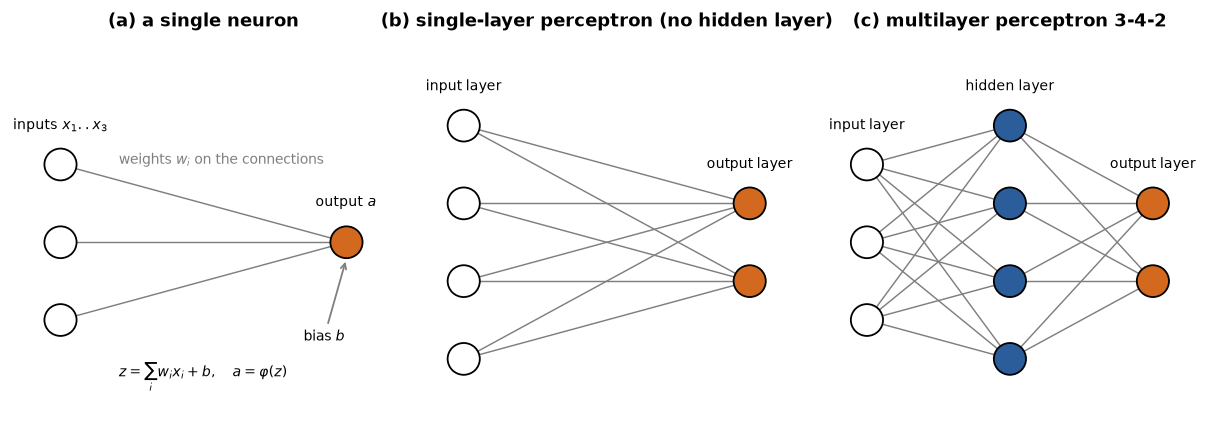

In [2]:
# Figura 1: los tres objetos de esta unidad —una neurona individual, un perceptrón de una capa y un perceptrón multicapa—
# dibujados como grafos para poder nombrar sus componentes (Taller 4).
def draw_layers(ax, sizes, labels, title, show_components=False):
    '''Draw a fully connected feed-forward network with the given layer sizes.'''
    xs = np.linspace(0.1, 0.9, len(sizes)); pos = {}
    for li, (x, n) in enumerate(zip(xs, sizes)):
        ys = np.linspace(0.5 - 0.11 * (n - 1), 0.5 + 0.11 * (n - 1), n)
        for ni, yv in enumerate(ys):
            pos[(li, ni)] = (x, yv)
            face = "white" if li == 0 else (BLUE if li < len(sizes) - 1 else ORANGE)
            ax.add_patch(plt.Circle((x, yv), 0.045, facecolor=face, edgecolor="k", lw=1, zorder=3))
        ax.text(x, 0.5 + 0.11 * (n - 1) + 0.1, labels[li], ha="center", fontsize=8)
    for li in range(len(sizes) - 1):
        for a in range(sizes[li]):
            for b in range(sizes[li + 1]):
                (x0, y0), (x1, y1) = pos[(li, a)], pos[(li + 1, b)]
                ax.plot([x0, x1], [y0, y1], color=GREY, lw=0.8, zorder=1)
    if show_components:   # anotar la neurona individual
        ax.text(0.55, 0.72, "weights $w_i$ on the connections", ha="center", fontsize=7.5, color=GREY)
        ax.text(0.5, 0.12, "$z = \\sum_i w_i x_i + b, \\quad a = \\varphi(z)$", ha="center", va="center", fontsize=8)
        ax.annotate("bias $b$", xy=(0.9, 0.455), xytext=(0.78, 0.22), fontsize=7.5, arrowprops=dict(arrowstyle="->", color=GREY))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.08); ax.axis("off"); ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.4))
draw_layers(axes[0], [3, 1], ["inputs $x_1..x_3$", "output $a$"], "(a) a single neuron", show_components=True)
draw_layers(axes[1], [4, 2], ["input layer", "output layer"], "(b) single-layer perceptron (no hidden layer)")
draw_layers(axes[2], [3, 4, 2], ["input layer", "hidden layer", "output layer"], "(c) multilayer perceptron 3-4-2")
fig.tight_layout()

<p class="caption"><b>Figura 1.</b> Los tres objetos de esta unidad. (a) Una neurona artificial individual: las entradas $x_i$ llegan por conexiones que llevan pesos $w_i$; la unidad calcula la suma ponderada $z = \sum_i w_i x_i + b$ (el sesgo $b$ es un peso sobre una entrada constante igual a 1) y aplica una función de activación $\varphi$ para producir la salida $a$. (b) Un perceptrón de una sola capa: varias neuronas que comparten las mismas entradas; la capa de entrada no realiza ningún cálculo y no se cuenta como capa de neuronas. (c) Un perceptrón multicapa con una capa oculta (azul) y una capa de salida (naranja); cada unidad de una capa está conectada con cada unidad de la siguiente, de ahí que se diga <em>totalmente conectada</em> o <em>densa</em>. La red (c) tiene $3 \times 4 + 4 + 4 \times 2 + 2 = 26$ parámetros.</p>

## 2. Características generales del cerebro humano

El nombre "red neuronal" es una declaración de parentesco con el cerebro, y esa declaración debe examinarse antes de usarla. Esta sección resume lo que se sabe sobre el órgano, indica cuáles de sus propiedades imitan las redes artificiales de esta unidad y deja explícito cuáles no.

### 2.1 El cerebro en cifras

El cerebro humano adulto contiene unos 86 mil millones de neuronas —$86.1 \pm 8.1 \times 10^9$ según los recuentos con fraccionador isotrópico de Azevedo y colaboradores—, junto con un número aproximadamente igual de células no neuronales (gliales).<sup class="c"><a href="#r7">[7]</a></sup> La cifra popular de 100 mil millones es una estimación más antigua que los recuentos directos no confirmaron; y, contrariamente a otra afirmación popular, el cerebro humano no es excepcional por su tamaño, sino que es un cerebro de primate escalado linealmente, notable sobre todo por el número de neuronas que concentra en la corteza cerebral (unos 16 mil millones).<sup class="c"><a href="#r8">[8]</a></sup> Cada neurona cortical recibe del orden de miles de sinapsis; los recuentos estereológicos en la neocorteza humana dan alrededor de $1.5 \times 10^{14}$ sinapsis solo en esa estructura,<sup class="c"><a href="#r9">[9]</a></sup> de modo que el rango habitual de los libros de texto, $10^{14}$–$10^{15}$ sinapsis para todo el cerebro, tiene el orden de magnitud correcto.

### 2.2 La neurona y el potencial de acción

Una neurona tiene tres partes funcionales. Las <strong>dendritas</strong> son prolongaciones ramificadas que reciben señales de otras neuronas; el <strong>soma</strong> (cuerpo celular) las integra; el <strong>axón</strong> es una única fibra larga que lleva la señal de salida hacia otras células y termina en terminales que forman <strong>sinapsis</strong> con las dendritas de las neuronas siguientes. La comunicación a través de una sinapsis es química: las sinapsis excitatorias elevan el potencial de membrana de la célula receptora y las inhibitorias lo reducen; la <em>fuerza</em> de cada sinapsis —cuánto mueve el potencial una señal entrante— es la magnitud biológica a la que corresponden los pesos de una red artificial.

La señal de salida es el <strong>potencial de acción</strong> (espiga): cuando el potencial de membrana al inicio del axón supera un umbral de alrededor de $-55$ a $-50$ mV, se abren canales de sodio dependientes de voltaje, el potencial sube hasta unos $+30$ mV y vuelve en uno o dos milisegundos, y el pulso se propaga a lo largo del axón sin pérdida de amplitud. Hodgkin y Huxley describieron cuantitativamente el mecanismo iónico en 1952, en el trabajo por el que recibieron el Premio Nobel.<sup class="c"><a href="#r10">[10]</a></sup> El potencial de acción es de <em>todo o nada</em>: su tamaño no depende de cuánto se superó el umbral. La información sobre la intensidad de la entrada se transmite, en cambio, mediante la <em>frecuencia</em> de disparo: una neurona estimulada con más fuerza emite más espigas por segundo, hasta un límite fijado por el período refractario de unos pocos milisegundos durante el cual no puede volver a disparar. Este <strong>código de frecuencia</strong> (rate code) es la lectura biológica de la función de activación de la Sección 6: la salida de una unidad artificial es un número continuo que representa una frecuencia de disparo, no una espiga individual. La celda siguiente simula el modelo más simple que captura el mecanismo, la neurona de <em>integración y disparo con fuga</em> (leaky integrate-and-fire) propuesta por Lapicque en 1907,<sup class="c"><a href="#r11">[11]</a></sup> y grafica su frecuencia de disparo en función de la corriente de entrada.

input  1.5 nA -> firing rate     0 Hz
input  2.5 nA -> firing rate    28 Hz
input  4.0 nA -> firing rate    62 Hz
input  8.0 nA -> firing rate   128 Hz
input 50.0 nA -> firing rate   346 Hz


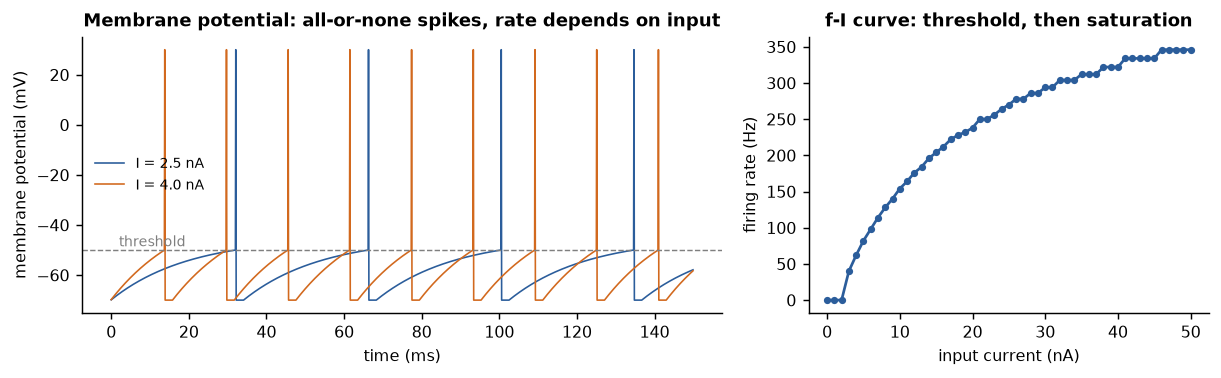

In [3]:
# Una neurona de integración y disparo con fuga: el potencial de membrana integra la corriente de entrada, se fuga de vuelta hacia el reposo
# y emite una espiga (y luego se reinicia) cada vez que alcanza el umbral. La frecuencia de disparo frente a la entrada es la curva f-I.
tau_m, R, V_rest, V_th, V_reset, t_ref = 20.0, 10.0, -70.0, -50.0, -70.0, 2.0   # ms, MOhm, mV, mV, mV, ms
dt, T = 0.1, 500.0                                                               # paso de tiempo y duración (ms)

def lif(I_nA):
    '''Euler integration of tau_m dV/dt = -(V - V_rest) + R I; returns the potential trace and spike times.'''
    V, refractory, trace, spikes = V_rest, 0.0, [], []
    for step in range(int(T / dt)):
        if refractory > 0: refractory -= dt; V = V_reset
        else: V += dt / tau_m * (-(V - V_rest) + R * I_nA)
        if V >= V_th: spikes.append(step * dt); V = 30.0; refractory = t_ref    # espiga y luego reinicio refractario
        trace.append(V)
    return np.array(trace), np.array(spikes)

currents = np.linspace(0, 50, 51)
rates = np.array([len(lif(I)[1]) / T * 1000 for I in currents])                  # espigas por segundo (Hz)
for I in (1.5, 2.5, 4.0, 8.0, 50.0):
    print(f"input {I:4.1f} nA -> firing rate {len(lif(I)[1]) / T * 1000:5.0f} Hz")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.0), gridspec_kw={"width_ratios": [1.6, 1]})
t = np.arange(0, T, dt)
for I, col in ((2.5, BLUE), (4.0, ORANGE)):
    axes[0].plot(t[:1500], lif(I)[0][:1500], color=col, lw=0.9, label=f"I = {I} nA")
axes[0].axhline(V_th, color=GREY, ls="--", lw=0.8); axes[0].text(2, V_th + 1.5, "threshold", color=GREY, fontsize=8)
axes[0].set_xlabel("time (ms)"); axes[0].set_ylabel("membrane potential (mV)"); axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Membrane potential: all-or-none spikes, rate depends on input")
axes[1].plot(currents, rates, "o-", color=BLUE, ms=3); axes[1].set_xlabel("input current (nA)"); axes[1].set_ylabel("firing rate (Hz)")
axes[1].set_title("f-I curve: threshold, then saturation"); fig.tight_layout()

<p class="caption"><b>Figura 2.</b> Izquierda: potencial de membrana de una neurona de integración y disparo con fuga para dos corrientes de entrada. Todas las espigas tienen la misma amplitud; una entrada más intensa solo las hace más frecuentes. Derecha: frecuencia de disparo en función de la corriente de entrada. Por debajo de unos 2 nA gana la fuga y la neurona nunca alcanza el umbral (frecuencia 0); por encima, la frecuencia sube abruptamente al principio y luego se curva hacia el techo $1/t_{\text{ref}} = 500$ Hz impuesto por el período refractario (unos 350 Hz a 50 nA). La curva tiene exactamente la forma de las funciones de activación de la Sección 6: un umbral, una subida pronunciada y una meseta; una sigmoide biológica.</p>

### 2.3 Lento, paralelo, distribuido, robusto, plástico

Hay cinco propiedades del cerebro como dispositivo de cómputo que los modelos conexionistas se proponen capturar.

**Es lento pero masivamente paralelo.** Una neurona dispara a lo sumo unos cientos de veces por segundo y una señal cruza una sinapsis en alrededor de un milisegundo, unas $10^6$ veces más lento de lo que conmuta un transistor. Aun así, una persona reconoce un rostro en unos 100–150 ms, es decir, en a lo sumo cien pasos en serie. El cerebro compensa la lentitud de sus componentes teniendo $10^{11}$ de ellos trabajando a la vez; cualquiera que sea el algoritmo que ejecuta, debe ser poco profundo y ancho, no profundo y serial. Las redes artificiales heredan esto: cada capa se calcula en paralelo como un único producto de matrices, razón por la cual los procesadores gráficos (Sección 11) les resultan tan adecuados.

**El conocimiento está distribuido.** Ninguna neurona individual almacena el concepto "abuela"; un concepto es un patrón de actividad sobre muchas neuronas, y una neurona participa en muchos patrones. Del mismo modo, en una red artificial ningún peso significa algo por sí solo; el conocimiento de una red entrenada está repartido entre todos sus pesos, lo que está en la raíz de su opacidad (Sección 4).

**Se degrada con suavidad.** Las neuronas mueren a diario durante toda la vida adulta, y el cerebro tolera la pérdida de una fracción considerable antes de que la función se vea perceptiblemente afectada; el daño produce un declive gradual en lugar de un colapso. La Sección 4.3 muestra la misma propiedad en una red artificial a la que se le eliminan pesos al azar.

**Aprende modificando sinapsis.** La fuerza de una sinapsis cambia con el uso. Hebb propuso la regla en 1949: cuando una neurona presináptica participa repetidamente en el disparo de una postsináptica, la conexión entre ellas se fortalece; en la consigna, <em>las células que disparan juntas se conectan juntas</em>.<sup class="c"><a href="#r12">[12]</a></sup> La regla de Hebb es la antecesora de todas las reglas de aprendizaje de esta unidad, y la celda siguiente la implementa en tres líneas. Tal como está escrita, la regla solo fortalece sinapsis —reglas posteriores agregaron normalización o una señal de error (Sección 7.5)—, pero la idea de que <em>aprender es ajustar la fuerza de las conexiones</em> es la que toda red artificial comparte con el cerebro.

**Construye sus propias características.** La corteza visual es una jerarquía: las áreas tempranas responden a bordes orientados, y las posteriores a contornos, texturas, partes y, finalmente, objetos y rostros. Nadie diseña estas características; emergen de la exposición al mundo visual. Las redes profundas de la Unidad 8 son su contraparte artificial, y los filtros que aprenden en su primera capa se parecen lo suficiente a los detectores de bordes de la corteza visual primaria como para que el parecido sea una de las ilustraciones clásicas del campo.<sup class="c"><a href="#r6">[6]</a></sup>

In [4]:
# La regla de Hebb en numpy: dw_i = eta * x_i * y. El peso de una entrada que dispara junto con la salida crece;
# el peso de una entrada que dispara independientemente de la salida crece mucho más lentamente.
rng = np.random.default_rng(0); steps = 500
post     = rng.random(steps) < 0.3                                              # la neurona de salida dispara en ~30 % de los pasos
pre_corr = np.where(post, rng.random(steps) < 0.9, rng.random(steps) < 0.05)    # la entrada 1 suele disparar JUNTO CON la salida
pre_rand = rng.random(steps) < 0.3                                              # la entrada 2 dispara de forma independiente
eta, w, history = 0.01, np.zeros(2), []
for x1, x2, yv in zip(pre_corr, pre_rand, post):
    w = w + eta * np.array([x1, x2]) * yv              # Hebb: fortalecer la sinapsis cuando pre Y post están activas
    history.append(w.copy())
history = np.array(history)
corr = pd.DataFrame({"input": ["input 1 (correlated)", "input 2 (independent)"],
                     "P(input fires)": [pre_corr.mean(), pre_rand.mean()],
                     "P(input fires | output fires)": [pre_corr[post].mean(), pre_rand[post].mean()],
                     "final weight": history[-1]}).round(3)
print(corr.to_string(index=False))

                input  P(input fires)  P(input fires | output fires)  final weight
 input 1 (correlated)           0.282                          0.899          1.16
input 2 (independent)           0.342                          0.341          0.44


Ambas entradas disparan alrededor del 30 % del tiempo, de modo que una regla que fortaleciera una sinapsis cada vez que la <em>entrada</em> estuviera activa las trataría por igual. La regla de Hebb está condicionada a la coincidencia entre entrada y salida, y la entrada que dispara junto con la salida en cerca del 90 % de las espigas de esta termina con un peso entre dos y tres veces mayor que el de la entrada que coincide con ella solo por azar. La red ha aprendido una <em>correlación</em> a partir de la experiencia, sin un profesor: es el mecanismo que la regla del perceptrón de la Sección 7 convierte en aprendizaje supervisado al agregar una señal de error.

### 2.4 Cerebro y computador, lado a lado

| Propiedad | Cerebro humano | Computador digital |
|---|---|---|
| Elemento básico | neurona (~$10^{11}$) con ~$10^3$–$10^4$ sinapsis cada una | transistor (~$10^{10}$ por chip) |
| Tiempo de conmutación | ~1 ms | ~0.1 ns |
| Funcionamiento | analógico, ruidoso, masivamente paralelo | digital, exacto, mayormente serial |
| Memoria | distribuida en la fuerza de las sinapsis; direccionable por contenido | localizada en direcciones; basada en direcciones |
| Programación | aprendida de la experiencia; plasticidad sináptica | escrita explícitamente por un programador |
| Tolerancia a fallos | degradación suave; tolera la pérdida diaria de neuronas | un solo bit erróneo puede hacer fallar un programa |
| Energía | ~20 W | cientos de watts para una GPU de entrenamiento |
| Fortalezas | percepción, reconocimiento de patrones, control motor, generalización a partir de pocos ejemplos | aritmética, lógica exacta, almacenamiento y recuperación de grandes volúmenes |

<div class="box warn"><h4>Inspiradas en el cerebro, no un modelo de él</h4><p>Las redes neuronales artificiales toman del cerebro las ideas de unidades simples, conexiones ponderadas, capas, representación distribuida y aprendizaje mediante ajuste de pesos, y nada más. Las unidades de esta unidad no tienen espigas, ni tiempo, ni cómputo dendrítico, ni neurotransmisores, ni glía; su regla de aprendizaje, la retropropagación, requiere que cada sinapsis conozca el error en la salida y se ajuste con la misma señal global, algo para lo cual no se conoce ningún mecanismo biológico; y su entrenamiento necesita millones de ejemplos etiquetados donde a un niño le bastan unos pocos. Una red neuronal es un modelo estadístico ajustado por optimización, y el vocabulario de "neuronas" y "aprendizaje" es una metáfora histórica. Afirmaciones como "la red piensa" o "el algoritmo aprende como un cerebro" deben leerse teniendo esto en cuenta.<sup class="c"><a href="#r6">[6]</a></sup></p></div>

## 3. Qué es una red neuronal artificial

### 3.1 Unidades, pesos, capas, arquitectura

Una <strong>red neuronal artificial</strong> es un grafo dirigido cuyos nodos son <em>unidades</em> (neuronas) y cuyas aristas son <em>conexiones</em>, cada una con un <em>peso</em> de valor real. Todas las unidades calculan lo mismo: la suma ponderada de sus entradas más un <em>sesgo</em> (bias), pasada por una <em>función de activación</em> (Sección 6). Las unidades se organizan en <strong>capas</strong>: una <em>capa de entrada</em>, que simplemente contiene el vector de características y no realiza ningún cálculo; cero o más <em>capas ocultas</em>, llamadas así porque sus valores no se entregan como datos ni se leen como predicciones; y una <em>capa de salida</em>, cuyos valores son la predicción. La <strong>arquitectura</strong> es la especificación de cuántas capas hay, cuántas unidades tiene cada una, qué activación usa cada una y cómo se conectan las capas. La notación 30-16-1 significa 30 entradas, una capa oculta de 16 unidades y una salida; por convención, el número de capas de una red cuenta las capas que calculan, de modo que una red 30-16-1 es una red de <em>dos capas</em> con <em>una capa oculta</em>. Los libros de texto difieren en este conteo —algunos incluyen la capa de entrada—, así que, cuando importe, indica la arquitectura de forma explícita.

Existen dos tipos de arquitectura. En una red <strong>prealimentada</strong> (feed-forward) el grafo no tiene ciclos: la información fluye desde la capa de entrada, a través de las capas ocultas, hasta la salida, y la salida es función solo de la entrada actual. Todas las redes de esta unidad son prealimentadas. En una red <strong>recurrente</strong> algunas conexiones vuelven hacia atrás, de modo que la salida en un paso de tiempo depende de las entradas en pasos anteriores; las redes recurrentes procesan secuencias —habla, electrocardiogramas, texto— y la Sección 11 vuelve sobre ellas.

### 3.2 La red como función parametrizada

Matemáticamente, una red prealimentada con parámetros $\boldsymbol{\theta}$ (todos sus pesos y sesgos) es una función $f(\mathbf{x}; \boldsymbol{\theta})$ que va del vector de características $\mathbf{x} \in \mathbb{R}^p$ a una salida $\hat{\mathbf{y}}$. La arquitectura fija la <em>forma</em> de $f$; el entrenamiento elige los <em>valores</em> de $\boldsymbol{\theta}$ que hacen que $f(\mathbf{x}_i; \boldsymbol{\theta}) \approx y_i$ en la muestra de entrenamiento, minimizando una función de pérdida con descenso de gradiente: exactamente la receta de la Unidad 2 para la regresión lineal y logística, con una $f$ más flexible. Una red es un modelo, en el vocabulario de la Unidad 1, y la retropropagación es el algoritmo que lo ajusta.

El número de parámetros es lo primero que hay que calcular al leer una arquitectura, porque acota la cantidad de datos que la red necesita. Para una red totalmente conectada con tamaños de capa $n_0, n_1, \dots, n_L$ (con $n_0 = p$), cada capa $l$ tiene una matriz de pesos de $n_{l-1} \times n_l$ y $n_l$ sesgos, de modo que

<div class="eq">$$\#\boldsymbol{\theta} = \sum_{l=1}^{L} \left( n_{l-1}\, n_l + n_l \right).$$</div>

In [5]:
# Contar los parámetros a partir de la arquitectura: pesos más sesgos de cada capa que calcula.
def n_parameters(sizes):
    '''Number of weights and biases of a fully connected network with the given layer sizes.'''
    return sum(n_in * n_out + n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))

archs = {"single neuron, 2 inputs":           [2, 1],
         "single neuron, 30 inputs":          [30, 1],
         "2-2-1 (the XOR network, Section 8)": [2, 2, 1],
         "30-16-1 (breast cancer, Section 8)": [30, 16, 1],
         "64-100-10 (digits, Section 9)":      [64, 100, 10],
         "784-500-500-10 (handwritten digits at 28 x 28)": [784, 500, 500, 10]}
pd.DataFrame({"layer sizes": [str(s) for s in archs.values()],
              "parameters": [n_parameters(s) for s in archs.values()]}, index=list(archs))

,layer sizes,parameters
"single neuron, 2 inputs","[2, 1]",3
"single neuron, 30 inputs","[30, 1]",31
"2-2-1 (the XOR network, Section 8)","[2, 2, 1]",9
"30-16-1 (breast cancer, Section 8)","[30, 16, 1]",513
"64-100-10 (digits, Section 9)","[64, 100, 10]",7510
784-500-500-10 (handwritten digits at 28 x 28),"[784, 500, 500, 10]",648010


Una neurona individual con 30 entradas tiene 31 parámetros, el mismo número que una regresión logística con 30 características, y no es una coincidencia (siguiente subsección). Agregar una capa oculta de 16 unidades multiplica el conteo por alrededor de 16; una modesta red de tres capas para imágenes de 28 × 28 ya tiene unos 650,000 parámetros, más que el número de imágenes de entrenamiento de la mayoría de los conjuntos de datos médicos. La razón entre parámetros y casos de entrenamiento es la magnitud que hay que tener presente a lo largo de las Secciones 8–10: una red con más parámetros que casos puede memorizar perfectamente la muestra de entrenamiento, y solo la metodología del Suplemento S1 revela si ha aprendido algo más.

### 3.3 Una neurona individual con sigmoide es una regresión logística

La red más simple —una unidad, activación sigmoide— calcula $\hat{y} = \sigma(\mathbf{w}^\top \mathbf{x} + b)$ con $\sigma(z) = 1/(1+e^{-z})$. Ese es exactamente el modelo de regresión logística de la Unidad 2: los pesos son los coeficientes de la regresión, el sesgo es el intercepto y, si la unidad se entrena con descenso de gradiente sobre la pérdida de entropía cruzada, debe llegar a la misma solución, porque la pérdida es convexa y tiene un único mínimo. La celda siguiente entrena la neurona a mano con dos características estandarizadas de los datos de cáncer de mama<sup class="c"><a href="#r13">[13]</a></sup> y compara sus pesos con los de <code>LogisticRegression</code> de scikit-learn ajustada con una penalización despreciable.

In [6]:
# Una neurona sigmoide individual entrenada con descenso de gradiente ES una regresión logística: mismo modelo, misma solución.
from sklearn.linear_model import LogisticRegression
cancer = datasets.load_breast_cancer(as_frame=True)
X_all, y_all = cancer.data, cancer.target                         # scikit-learn codifica 0 = maligno, 1 = benigno
y_mal = (y_all == 0).astype(float).to_numpy()                     # predecimos P(maligno): 1 = maligno
feat2 = ["mean radius", "mean concave points"]
Z2 = StandardScaler().fit_transform(X_all[feat2].to_numpy())      # estandarizadas: media 0, de 1 por característica

w, b = np.zeros(2), 0.0
for it in range(30000):                                           # descenso de gradiente con lote completo sobre la entropía cruzada
    p = expit(Z2 @ w + b)
    w -= 1.0 * Z2.T @ (p - y_mal) / len(y_mal); b -= 1.0 * (p - y_mal).mean()
logreg = LogisticRegression(C=1e6, max_iter=5000).fit(Z2, y_mal)  # C muy grande = prácticamente sin regularización
print("sigmoid neuron     : w =", w.round(3), " b =", round(b, 3))
print("LogisticRegression : w =", logreg.coef_[0].round(3), " b =", round(logreg.intercept_[0], 3))
print(f"identical predictions on the 569 cases: {np.mean((expit(Z2 @ w + b) >= 0.5) == (logreg.predict(Z2) == 1)):.3f}")

sigmoid neuron     : w = [2.25  3.265]  b = -0.553
LogisticRegression : w = [2.243 3.27 ]  b = -0.552
identical predictions on the 569 cases: 1.000


Los pesos coinciden hasta aproximadamente el segundo decimal —el residuo se debe a la tolerancia de convergencia de scikit-learn y a su pequeña penalización— y los dos modelos hacen la misma predicción para todos los casos. Por lo tanto, todo lo que sabes sobre la regresión logística —cómo leer un coeficiente, estandarizar las características, la frontera recta— se aplica a una neurona individual. Más importante para esta unidad: una red con capas ocultas es una regresión logística <em>sobre características que la propia red ha aprendido</em>. La unidad de salida de la red 30-16-1 de la Sección 8 es una regresión logística con 16 entradas, pero esas 16 entradas no son características medidas; son combinaciones no lineales de las 30 mediciones, elegidas por el entrenamiento para que la regresión logística final sea exacta. Esto es lo que significa "aprender características", y es la idea más importante de la unidad.

<div class="box key"><h4>Idea clave</h4><p>Una red neuronal es una función parametrizada $f(\mathbf{x}; \boldsymbol{\theta})$ cuya capa de salida es un modelo conocido (regresión logística para clasificación, regresión lineal para regresión) y cuyas capas ocultas calculan las características que ese modelo recibe. El entrenamiento ajusta todos los parámetros a la vez mediante descenso de gradiente, de modo que las características se aprenden para la tarea en lugar de ser diseñadas por el analista.</p></div>

## 4. Ventajas y limitaciones

### 4.1 Qué hacen bien las redes

**No linealidad y aproximación universal.** Con una función de activación no lineal en la capa oculta, un MLP puede representar funciones que ninguna recta, gaussiana o caja puede representar. El resultado tiene una forma precisa: Cybenko (1989) demostró que una red con una capa oculta de unidades sigmoides y una salida lineal puede aproximar cualquier función continua sobre un dominio acotado con la exactitud que se desee, siempre que tenga suficientes unidades ocultas;<sup class="c"><a href="#r14">[14]</a></sup> Hornik, Stinchcombe y White extendieron el resultado a cualquier activación no constante, acotada y continua.<sup class="c"><a href="#r15">[15]</a></sup> Dos precauciones son esenciales. El teorema garantiza la <em>existencia</em>, no la <em>aprendibilidad</em>: no dice cuántas unidades se necesitan (el número puede ser astronómicamente grande), ni que el descenso de gradiente vaya a encontrar los pesos correctos, ni que una red que ajusta los datos de entrenamiento vaya a generalizar. Y "basta con una capa oculta" es una afirmación sobre la representación, no sobre la eficiencia; la Sección 11 explica por qué la profundidad ayuda en la práctica. La celda siguiente muestra el teorema en acción sobre una señal sintética.

**Características aprendidas.** La Sección 3.3 lo dejó claro: las capas ocultas son extractores de características entrenados para la tarea. Para datos tabulares con treinta características diseñadas esto importa poco; para imágenes, señales y secuencias, donde nadie sabe cómo diseñar las características, es decisivo.<sup class="c"><a href="#r6">[6]</a></sup>

**Paralelismo y degradación suave.** Cada unidad de una capa calcula de forma independiente, de modo que una capa es un único producto de matrices, y una red con millones de parámetros se ejecuta en milisegundos en hardware paralelo. Y como el conocimiento está distribuido entre muchos pesos, ningún peso individual es crítico: eliminar una fracción de ellos degrada el desempeño de forma gradual y no abrupta (Sección 4.3), una propiedad que no comparte ningún árbol de decisión, en el que cortar un nodo elimina un subárbol completo.

  2 tanh hidden units:    7 parameters, RMSE = 0.1510, L-BFGS iterations = 213
  4 tanh hidden units:   13 parameters, RMSE = 0.0685, L-BFGS iterations = 160
 16 tanh hidden units:   49 parameters, RMSE = 0.0064, L-BFGS iterations = 1893
 64 tanh hidden units:  193 parameters, RMSE = 0.0116, L-BFGS iterations = 1562


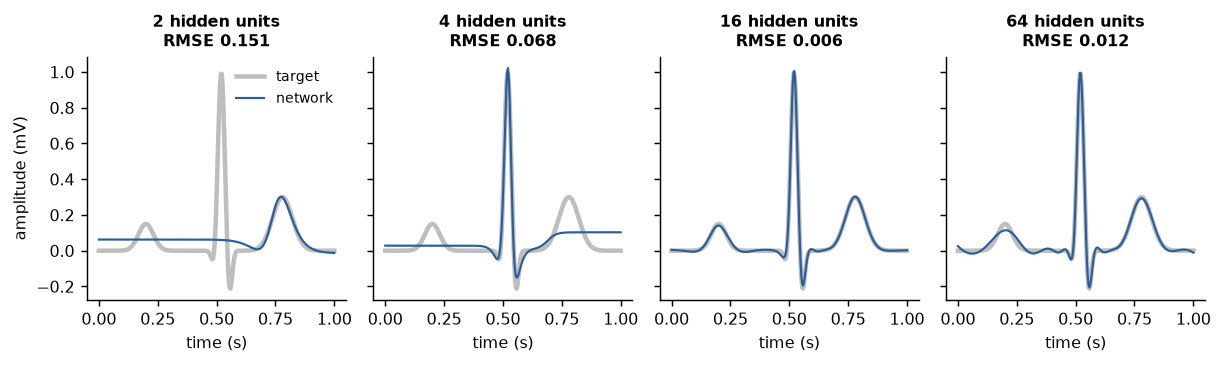

In [7]:
# La aproximación universal en acción: una red de una capa oculta con unidades tanh ajusta un latido de ECG sintético
# (onda P, complejo QRS, onda T como bultos gaussianos). Más unidades ocultas -> mejor ajuste, hasta cierto punto.
def ecg_beat(t):
    '''Synthetic one-beat ECG: Gaussian bumps for P, Q, R, S and T, in arbitrary mV units.'''
    g = lambda mu, s, a: a * np.exp(-((t - mu) / s) ** 2)
    return g(0.20, 0.045, 0.15) + g(0.49, 0.015, -0.10) + g(0.52, 0.020, 1.0) + g(0.555, 0.015, -0.25) + g(0.78, 0.06, 0.30)
t = np.linspace(0, 1, 300); signal = ecg_beat(t)
X_t = ((t - 0.5) * 6)[:, None]                        # entrada reescalada a [-3, 3], el rango donde tanh no es trivial

fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.9), sharey=True)
for ax, h in zip(axes, (2, 4, 16, 64)):
    net = MLPRegressor(hidden_layer_sizes=(h,), activation="tanh", solver="lbfgs", max_iter=20000, tol=1e-12,
                       random_state=0).fit(X_t, signal)
    rmse = np.sqrt(np.mean((net.predict(X_t) - signal) ** 2))
    ax.plot(t, signal, color=GREY, lw=2.5, alpha=0.5, label="target"); ax.plot(t, net.predict(X_t), color=BLUE, lw=1.2, label="network")
    ax.set_title(f"{h} hidden units\nRMSE {rmse:.3f}", fontsize=9); ax.set_xlabel("time (s)")
    print(f"{h:3d} tanh hidden units: {n_parameters([1, h, 1]):4d} parameters, RMSE = {rmse:.4f}, L-BFGS iterations = {net.n_iter_}")
axes[0].set_ylabel("amplitude (mV)"); axes[0].legend(frameon=False, fontsize=8); fig.tight_layout()

<p class="caption"><b>Figura 3.</b> Una red de una capa oculta ajustada a un latido de ECG sintético con 2, 4, 16 y 64 unidades tanh. Dos unidades solo pueden colocar dos escalones suaves y omiten por completo el complejo QRS; cuatro capturan toscamente la onda R; dieciséis reproducen el latido completo con un error inferior a 0.01 mV. La red de 64 unidades, con cuatro veces más parámetros, ajusta ligeramente <em>peor</em> que la de 16: el optimizador se detuvo en un mínimo local de una pérdida no convexa, lo que ilustra la segunda limitación de la Sección 4.2: el teorema promete que los pesos existen, no que el entrenamiento los encontrará.</p>

### 4.2 Qué hacen mal las redes

**Necesitan muchos datos.** La flexibilidad que permite a una red representar cualquier función también le permite ajustar el ruido. Una red con $10^5$ parámetros entrenada con $10^2$ pacientes los memorizará; los métodos de la Sección 9 (detención temprana, regularización) mitigan el problema, pero no lo eliminan. En conjuntos de datos tabulares pequeños —la cohorte clínica típica de unos pocos cientos de casos—, los bosques aleatorios y las máquinas de vectores de soporte (Unidades 3–4) con frecuencia igualan o superan a las redes, y la Sección 10 pone esto a prueba honestamente con los datos de cáncer de mama.

**Son opacas.** Un árbol entrenado es una regla legible; una red entrenada es un conjunto de unos pocos miles de números cuyo significado individual es nulo. Los métodos post hoc —importancia por permutación (Sección 10), mapas de saliencia (Unidad 8)— ayudan, pero ninguno entrega una explicación que un clínico pueda verificar con la fisiología, y los marcos regulatorios de la Unidad 1 la exigen cada vez más.

**Tienen muchos hiperparámetros.** La arquitectura (cuántas capas, cuántas unidades), la función de activación, la tasa de aprendizaje, el tamaño de lote, el número de épocas, la inicialización, la intensidad de la regularización: cada una es una decisión sin teoría que la guíe, y cada una interactúa con las demás. La Sección 9 las revisa una por una; en la práctica se eligen por validación cruzada (Suplemento S1), con un costo en tiempo de cómputo en el que los métodos más simples no incurren.

**El entrenamiento es no convexo.** La pérdida de la regresión logística tiene un único mínimo; la pérdida de una red con capas ocultas tiene muchos mínimos locales, puntos de silla y mesetas planas, de modo que el resultado del entrenamiento depende de los pesos iniciales y del orden de los datos (de ahí <code>random_state</code>), y dos ejecuciones pueden dar modelos distintos y de distinta calidad. La Figura 3 mostró un pequeño ejemplo.

**Son frágiles fuera de la distribución de entrenamiento.** Una red extrapola con confianza hacia regiones donde no ha visto datos; las fallas por aprendizaje de atajos (shortcut learning) y por cambio en la distribución de los datos (dataset shift) de la Unidad 1 son, en la práctica, fallas de redes desplegadas más allá de sus datos de entrenamiento.

### 4.3 La degradación suave, medida

La celda siguiente entrena una red con los dígitos manuscritos (un sustituto de las imágenes médicas, como en la Unidad 1), luego elimina al azar una fracción creciente de los pesos de su primera capa —el equivalente artificial de perder neuronas— y mide la exactitud que se conserva. Se comparan dos anchos.

 32 hidden units: accuracy intact 0.974 | 30 % of weights deleted 0.937 | 60 % deleted 0.878
256 hidden units: accuracy intact 0.983 | 30 % of weights deleted 0.976 | 60 % deleted 0.944


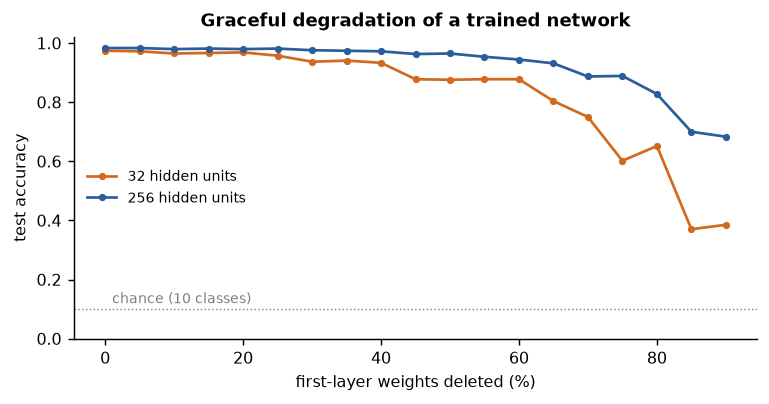

In [8]:
# Degradación suave: eliminar una fracción aleatoria de los pesos entrenados de la primera capa y medir la exactitud en dígitos reservados.
digits = datasets.load_digits()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(digits.data, digits.target, test_size=0.3, random_state=0, stratify=digits.target)
scaler_d = StandardScaler().fit(Xd_tr); Zd_tr, Zd_te = scaler_d.transform(Xd_tr), scaler_d.transform(Xd_te)
fractions = np.arange(0, 0.95, 0.05); rng = np.random.default_rng(0); results = {}
for h in (32, 256):
    net = MLPClassifier(hidden_layer_sizes=(h,), max_iter=400, random_state=0).fit(Zd_tr, yd_tr)
    W0 = net.coefs_[0].copy(); accs = []
    for frac in fractions:
        net.coefs_[0] = np.where(rng.random(W0.shape) < frac, 0.0, W0)      # 'matar' una fracción de las conexiones
        accs.append(net.score(Zd_te, yd_te))
    net.coefs_[0] = W0; results[h] = np.array(accs)
    print(f"{h:3d} hidden units: accuracy intact {accs[0]:.3f} | 30 % of weights deleted {accs[6]:.3f} | 60 % deleted {accs[12]:.3f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
for h, col in ((32, ORANGE), (256, BLUE)):
    ax.plot(fractions * 100, results[h], "o-", color=col, ms=3, label=f"{h} hidden units")
ax.axhline(0.1, color=GREY, ls=":", lw=0.8); ax.text(1, 0.12, "chance (10 classes)", color=GREY, fontsize=8)
ax.set_xlabel("first-layer weights deleted (%)"); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=8); ax.set_title("Graceful degradation of a trained network"); fig.tight_layout()

<p class="caption"><b>Figura 4.</b> Exactitud en prueba de dos redes entrenadas a medida que una fracción aleatoria de los pesos de su primera capa se lleva a cero. El declive es gradual: la red más ancha conserva la mayor parte de su exactitud con más de la mitad de sus conexiones eliminadas, e incluso la angosta necesita que se elimine más de un tercio antes de que la exactitud caiga por debajo de 0.9. La redundancia de la representación distribuida absorbe el daño. Compárese con un programa, en el que una sola instrucción corrupta detiene la ejecución, o con un árbol de decisión, en el que eliminar el nodo raíz elimina todas las decisiones.</p>

<div class="exercise"><h4>Ejercicio 1</h4><p>En la celda anterior, elimina pesos de la <em>segunda</em> capa (<code>net.coefs_[1]</code>, 32 o 256 × 10) en lugar de la primera. La segunda capa tiene muchos menos pesos; ¿es la red igual de tolerante a perderlos? Luego repite el experimento con un <code>DecisionTreeClassifier</code> de la Unidad 4, desactivando nodos al azar (asigna infinito a <code>tree.tree_.threshold</code> de nodos internos aleatorios), y compara la forma de la curva.</p></div>

## 5. Aplicaciones en medicina

Las redes neuronales entraron en la medicina mucho antes que el aprendizaje profundo. Baker y colaboradores entrenaron en 1995 una red de tres capas para predecir la malignidad del cáncer de mama a partir de los descriptores mamográficos estandarizados del léxico BI-RADS, y reportaron un área bajo la curva ROC mayor que la de los radiólogos tratantes en los mismos casos: un ejemplo temprano del patrón que el curso ha subrayado, una red ajustada a características diseñadas por clínicos y evaluada con la metodología ROC del Suplemento S1.<sup class="c"><a href="#r16">[16]</a></sup> Hacia 2006 la literatura era lo bastante amplia como para que Lisboa y Taktak la revisaran sistemáticamente en el ámbito del apoyo a la decisión en cáncer: de 396 estudios, solo 27 eran ensayos clínicos o ensayos controlados aleatorizados, y de ellos 21 mostraron un aumento del beneficio para la atención de salud, 6 no mostraron ninguno y ninguno mostró una disminución; un veredicto cautelosamente positivo y un recordatorio de que la mayoría de los modelos publicados nunca se evaluaron de un modo que pudiera demostrar beneficio.<sup class="c"><a href="#r17">[17]</a></sup>

La era del aprendizaje profundo produjo los sistemas que la Unidad 1 citó como evidencia de un desempeño de nivel especialista, todos ellos redes multicapa del tipo que describe esta unidad, escaladas y dotadas de capas convolucionales para imágenes (Unidad 8):

| Año | Tarea | Entrada | Arquitectura | Desempeño reportado | Ref. |
|---|---|---|---|---|---|
| 2016 | Retinopatía diabética | fotografías de fondo de ojo | red convolucional profunda | sensibilidad 97.5 %, especificidad 93.4 % en el punto de operación de alta sensibilidad (EyePACS-1) | <sup class="c"><a href="#r18">[18]</a></sup> |
| 2017 | Clasificación de cáncer de piel | fotografías dermatoscópicas y clínicas | red convolucional profunda | a la par de 21 dermatólogos en imágenes confirmadas por biopsia | <sup class="c"><a href="#r19">[19]</a></sup> |
| 2018 | Decisiones de derivación a partir de OCT retiniana | tomografía de coherencia óptica 3-D | dos redes: segmentación y luego clasificación | tasa de error de 5.5 %, igual a la de especialistas en retina en 997 exámenes | <sup class="c"><a href="#r20">[20]</a></sup> |
| 2019 | Detección de arritmias | ECG ambulatorio de una sola derivación | red convolucional de 34 capas | F1 0.837, superior al cardiólogo promedio en 12 clases de ritmo | <sup class="c"><a href="#r21">[21]</a></sup> |

Tres lecciones corresponden a esta unidad. Primero, cada uno de estos sistemas es un clasificador del tipo que se construye en la Sección 10 —entradas, capas ocultas, salida softmax, pérdida de entropía cruzada, descenso de gradiente— y se diferencia de la red 30-16-1 en la escala y en el uso de la convolución. Segundo, sus entradas son píxeles o voltajes en bruto: la ventaja de las <em>características aprendidas</em> de la Sección 4.1 es lo que los hizo posibles, y es la razón por la que los datos de cáncer de mama, con 30 características diseñadas a mano, no favorecen a las redes (Sección 10). Tercero, como subrayaron Rajkomar, Dean y Kohane en su revisión para clínicos, el desempeño en un conjunto de prueba curado es el comienzo de la evidencia, no el final: la validación prospectiva, la calibración, el cambio en la distribución de los datos (dataset shift) y la integración en el flujo de trabajo deciden si un modelo ayuda a los pacientes.<sup class="c"><a href="#r22">[22]</a></sup>

<div class="box bridge"><h4>Puente con la bioinformática</h4><p>El avance que mejor conocen los estudiantes de BGM324, AlphaFold, es una red neuronal: sus entradas son alineamientos múltiples de secuencias y características de pares de residuos, y su salida es una estructura proteica. Los modelos QSAR de actividad molecular —los descriptores moleculares de tu curso de bioinformática como capa de entrada y la actividad como salida— estuvieron entre las primeras aplicaciones de los perceptrones multicapa en las ciencias de la vida, y la metodología de validación cruzada que usaste allí es la que aplica la Sección 10.</p></div>

## 6. El modelo computacional de la neurona

### 6.1 De McCulloch–Pitts a la unidad moderna

McCulloch y Pitts abstrajeron la neurona de la Sección 2.2 en un dispositivo lógico: entradas binarias, cada una excitatoria o inhibitoria, un umbral y una salida binaria que se activa cuando el número de entradas excitatorias activas alcanza el umbral y ninguna entrada inhibitoria está activa. Demostraron que redes de tales unidades pueden calcular cualquier función booleana y, con ello, que la lógica del cerebro podía, en principio, ser realizada por neuronas.<sup class="c"><a href="#r1">[1]</a></sup> Su unidad no aprendía. El perceptrón de Rosenblatt (Sección 7) dio a cada entrada un <em>peso</em> de valor real ajustable a partir de los datos, y la unidad moderna generaliza el umbral a una <em>función de activación</em> arbitraria. El cálculo de una unidad con $p$ entradas se hace en dos pasos:

<div class="eq">$$z = \sum_{i=1}^{p} w_i x_i + b = \mathbf{w}^\top \mathbf{x} + b, \qquad a = \varphi(z),$$
<span class="where">donde $z$ es la <em>preactivación</em> (entrada neta), $w_i$ el peso de la entrada $i$, $b$ el sesgo, $\varphi$ la función de activación y $a$ la <em>activación</em> (salida) de la unidad. El sesgo puede incorporarse a los pesos agregando una entrada constante $x_0 = 1$ con peso $w_0 = b$, que es como suele dibujarse y como lo trata el código de la Sección 7.</span></div>

Geométricamente, $z = 0$ es un hiperplano en el espacio de características —una recta cuando $p = 2$— y el signo de $z$ indica en qué lado de él se encuentra $\mathbf{x}$. Por lo tanto, una unidad individual divide el espacio de características en dos semiespacios, cualquiera que sea la activación que use; la activación solo determina cómo varía la salida con la distancia a la frontera.

### 6.2 Funciones de activación

La función de activación es lo que hace que una red sea más que un modelo lineal: sin ella, una pila de capas calcula $\mathbf{W}_2(\mathbf{W}_1 \mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2$, que vuelve a ser una función lineal de $\mathbf{x}$, y ningún número de capas agregaría nada. Cinco funciones cubren casi toda la práctica.

| Función | Fórmula $\varphi(z)$ | Derivada $\varphi'(z)$ | Rango | Uso |
|---|---|---|---|---|
| **Escalón** (Heaviside) | $1$ si $z \geq 0$; si no, $0$ | $0$ en todas partes (indefinida en 0) | $\{0, 1\}$ | unidad de McCulloch–Pitts, perceptrón; no entrenable por gradiente |
| **Sigmoide** (logística) | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | $\sigma(z)\,(1 - \sigma(z))$ | $(0, 1)$ | unidad de salida para clasificación binaria (una probabilidad); históricamente también unidades ocultas |
| **Tangente hiperbólica** | $\tanh(z) = \dfrac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$ | $1 - \tanh^2(z)$ | $(-1, 1)$ | unidades ocultas; centrada en cero, lo que facilita el entrenamiento en comparación con la sigmoide |
| **ReLU** (unidad lineal rectificada) | $\max(0, z)$ | $1$ si $z > 0$; si no, $0$ | $[0, \infty)$ | unidad oculta por defecto desde alrededor de 2011; barata, y su derivada no se desvanece para $z > 0$ |
| **Softmax** | $\dfrac{e^{z_k}}{\sum_j e^{z_j}}$ para cada salida $k$ | (una matriz; ver Sección 8.2) | cada una en $(0,1)$, suma 1 | capa de salida para clasificación en $K$ clases: una distribución de probabilidad sobre las clases |

La columna de la derivada es tan importante como la de la función, porque el entrenamiento (Sección 8) multiplica derivadas de activaciones a lo largo del camino que va desde la salida hasta cada peso. La derivada de la sigmoide tiene un máximo de $0.25$ en $z = 0$ y es prácticamente cero para $|z| > 5$: una unidad cuya preactivación es grande en magnitud está <em>saturada</em>, y el gradiente que pasa por ella se desvanece; ese es el mecanismo detrás del problema del gradiente que se desvanece de la Sección 9.6. La ReLU, introducida en las redes profundas por Nair y Hinton,<sup class="c"><a href="#r26">[26]</a></sup> tiene derivada exactamente igual a 1 para toda entrada positiva, de modo que los gradientes atraviesan las unidades activas sin disminuir; su precio es que una unidad con $z < 0$ para todos los casos de entrenamiento tiene gradiente cero y nunca se recupera (una unidad "muerta"). La función escalón tiene derivada cero en todas partes, por eso el perceptrón (Sección 7) necesita una regla de aprendizaje que no sea descenso de gradiente, y por eso la sigmoide la reemplazó en cuanto se quiso entrenar con gradientes.

logits [2.  1.  0.1] -> softmax [0.659 0.242 0.099] | sum = 1.0
logits + 5  -> softmax [0.659 0.242 0.099] (adding a constant to all logits changes nothing)
logits x 3  -> softmax [0.95  0.047 0.003] (scaling the logits sharpens the distribution)


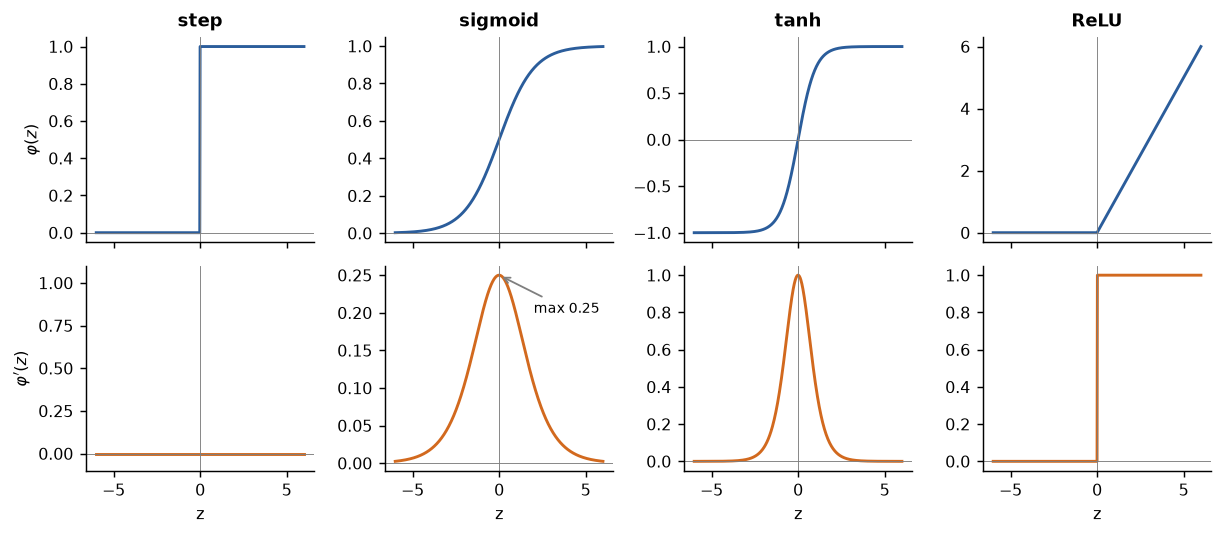

In [9]:
# Las cuatro funciones de activación escalares de la Sección 6.2 y sus derivadas.
z = np.linspace(-6, 6, 601)
acts = {"step":    (np.where(z >= 0, 1.0, 0.0), np.zeros_like(z)),
        "sigmoid": (expit(z), expit(z) * (1 - expit(z))),
        "tanh":    (np.tanh(z), 1 - np.tanh(z) ** 2),
        "ReLU":    (np.maximum(z, 0), (z > 0).astype(float))}
fig, axes = plt.subplots(2, 4, figsize=(9.5, 4.2), sharex=True)
for j, (name, (f, df)) in enumerate(acts.items()):
    axes[0, j].plot(z, f, color=BLUE, lw=1.6); axes[0, j].set_title(name)
    axes[1, j].plot(z, df, color=ORANGE, lw=1.6); axes[1, j].set_xlabel("z")
    for ax in axes[:, j]: ax.axhline(0, color=GREY, lw=0.5); ax.axvline(0, color=GREY, lw=0.5)
axes[0, 0].set_ylabel(r"$\varphi(z)$"); axes[1, 0].set_ylabel(r"$\varphi'(z)$"); axes[1, 0].set_ylim(-0.1, 1.1)
axes[1, 1].annotate("max 0.25", xy=(0, 0.25), xytext=(2, 0.2), fontsize=8, arrowprops=dict(arrowstyle="->", color=GREY))
fig.tight_layout()

# Softmax convierte K puntajes reales (logits) en una distribución de probabilidad sobre K clases.
def softmax(v): e = np.exp(v - v.max()); return e / e.sum()     # restar el máximo evita el desbordamiento; el resultado no cambia
logits = np.array([2.0, 1.0, 0.1])
print("logits", logits, "-> softmax", softmax(logits).round(3), "| sum =", softmax(logits).sum().round(6))
print("logits + 5  -> softmax", softmax(logits + 5).round(3), "(adding a constant to all logits changes nothing)")
print("logits x 3  -> softmax", softmax(logits * 3).round(3), "(scaling the logits sharpens the distribution)")

<p class="caption"><b>Figura 5.</b> Fila superior: las funciones de activación escalón, sigmoide, tanh y ReLU. Fila inferior: sus derivadas. El escalón tiene derivada cero en todas partes, de modo que ningún gradiente puede fluir a través de él. La derivada de la sigmoide alcanza su máximo en 0.25 y es despreciable más allá de $|z| \approx 5$ (saturación); la de tanh alcanza su máximo en 1, pero se satura de manera similar. La derivada de la ReLU es 1 para toda entrada positiva —la propiedad que hizo entrenables las redes profundas— y 0 para las entradas negativas. Bajo la figura, la softmax de tres logits: las salidas son positivas, suman uno, no cambian al sumar una constante a todos los logits y se vuelven más marcadas cuando los logits se escalan hacia arriba. Con $K = 2$ clases, la softmax se reduce a la sigmoide de la diferencia de los dos logits.</p>

### 6.3 Ejemplo resuelto a mano: una neurona calcula AND y OR, y no puede calcular XOR

Toma una unidad de McCulloch–Pitts con dos entradas binarias y activación escalón, $a = \mathbb{1}[w_1 x_1 + w_2 x_2 + b \geq 0]$. Con pesos $w_1 = w_2 = 1$ y sesgo $b = -1.5$, la unidad calcula el **AND** lógico; con los mismos pesos y $b = -0.5$, calcula **OR**:

| $x_1$ | $x_2$ | $z_{\text{AND}} = x_1 + x_2 - 1.5$ | AND | $z_{\text{OR}} = x_1 + x_2 - 0.5$ | OR | XOR (objetivo) |
|---|---|---|---|---|---|---|
| 0 | 0 | $-1.5$ | 0 | $-0.5$ | 0 | 0 |
| 0 | 1 | $-0.5$ | 0 | $0.5$ | 1 | 1 |
| 1 | 0 | $-0.5$ | 0 | $0.5$ | 1 | 1 |
| 1 | 1 | $0.5$ | 1 | $1.5$ | 1 | 0 |

Geométricamente, la frontera $z = 0$ es la recta $x_1 + x_2 = 1.5$ para AND —separa la esquina $(1,1)$ de las otras tres— y la recta $x_1 + x_2 = 0.5$ para OR, que separa $(0,0)$ de las otras tres. NOT se calcula con una entrada con $w = -1$, $b = 0.5$; NAND, con $w_1 = w_2 = -1$, $b = 1.5$.

**Por qué ninguna unidad individual calcula XOR.** Supongamos que existieran pesos $w_1, w_2, b$ con $a = 1$ exactamente para $(0,1)$ y $(1,0)$. Los cuatro casos exigen

$$ b < 0 \quad (0,0 \mapsto 0), \qquad w_2 + b \geq 0 \quad (0,1 \mapsto 1), \qquad w_1 + b \geq 0 \quad (1,0 \mapsto 1), \qquad w_1 + w_2 + b < 0 \quad (1,1 \mapsto 0). $$

Sumar la segunda y la tercera desigualdad da $w_1 + w_2 + 2b \geq 0$, y restar la primera ($-b > 0$) da $w_1 + w_2 + b > 0$, lo que contradice la cuarta. No existen tales pesos. En la imagen, XOR le pide a una sola recta que deje las dos esquinas diagonales $(0,1)$ y $(1,0)$ a un lado y $(0,0)$ y $(1,1)$ al otro, y ninguna recta lo logra: las dos clases no son <strong>linealmente separables</strong>. Esta es la observación que Minsky y Papert convirtieron en una teoría general de lo que los perceptrones de una sola capa no pueden hacer,<sup class="c"><a href="#r3">[3]</a></sup> y la razón por la que las capas ocultas son necesarias: XOR es $(x_1 \text{ OR } x_2) \text{ AND NOT } (x_1 \text{ AND } x_2)$, una composición de tres funciones linealmente separables, que una red con una capa oculta de dos unidades calcula exactamente (la Sección 8.5 entrena una). La celda confirma la tabla y busca exhaustivamente, en una grilla, pesos para XOR.

 x1  x2  AND  OR  NAND  XOR target
  0   0    0   0     1           0
  0   1    0   1     1           1
  1   0    0   1     1           1
  1   1    1   1     0           0

XOR: best number of correct cases over all 1,771,561 weight triples = 3 of 4


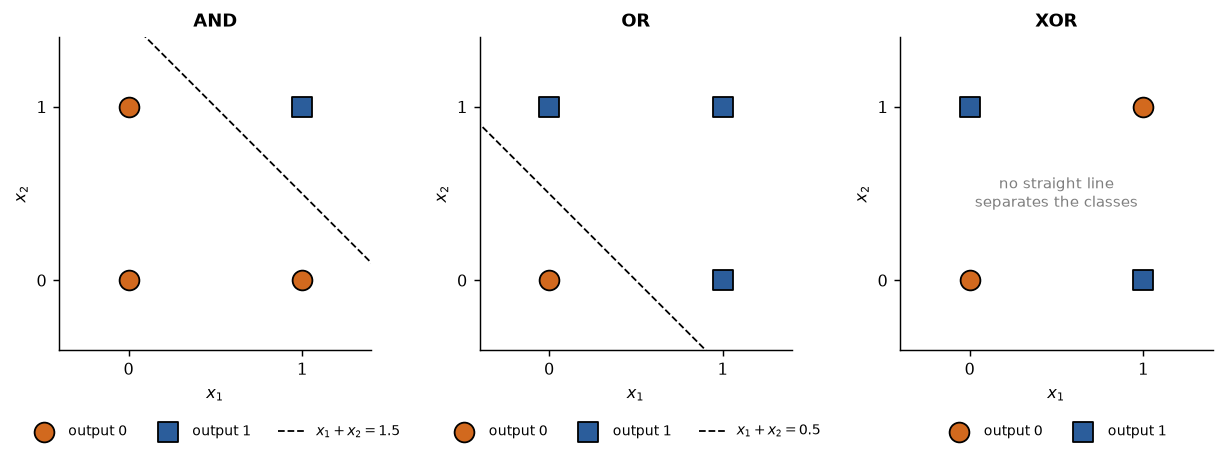

In [10]:
# Una unidad de McCulloch-Pitts que calcula AND, OR y NAND, y una búsqueda exhaustiva que muestra que ningún conjunto de pesos calcula XOR.
def unit(X, w, b):
    '''Step-activation unit: 1 if w.x + b >= 0 else 0.'''
    return (X @ w + b >= 0).astype(int)

X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]); xor_target = np.array([0, 1, 1, 0])
truth = pd.DataFrame(X_bool, columns=["x1", "x2"])
truth["AND"]  = unit(X_bool, np.array([1, 1]), -1.5)
truth["OR"]   = unit(X_bool, np.array([1, 1]), -0.5)
truth["NAND"] = unit(X_bool, np.array([-1, -1]), 1.5)
truth["XOR target"] = xor_target
print(truth.to_string(index=False))

grid = np.linspace(-3, 3, 121); best = 0                  # 121^3 = 1.77 millones de tríos (w1, w2, b)
for w1 in grid:
    for w2 in grid:
        z_all = X_bool @ np.array([w1, w2])                   # preactivación sin sesgo, forma (4,)
        preds = (z_all[None, :] + grid[:, None] >= 0).astype(int)   # una fila por cada sesgo candidato
        best = max(best, (preds == xor_target).sum(axis=1).max())
print(f"\nXOR: best number of correct cases over all {len(grid)**3:,} weight triples = {best} of 4")

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.5))
for ax, (name, target, line) in zip(axes, [("AND", truth["AND"], 1.5), ("OR", truth["OR"], 0.5), ("XOR", xor_target, None)]):
    for c, col, mk in ((0, ORANGE, "o"), (1, BLUE, "s")):
        ax.scatter(*X_bool[target == c].T, s=120, color=col, marker=mk, edgecolor="k", zorder=3, label=f"output {c}")
    if line is not None: ax.plot([-0.5, 2], [line + 0.5, line - 2], "k--", lw=1, label=f"$x_1 + x_2 = {line}$")
    else: ax.text(0.5, 0.5, "no straight line\nseparates the classes", ha="center", va="center", fontsize=8.5, color=GREY)
    ax.set_xlim(-0.4, 1.4); ax.set_ylim(-0.4, 1.4); ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_aspect("equal")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title(name)
    ax.legend(frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
fig.tight_layout()

<p class="caption"><b>Figura 6.</b> Los cuatro patrones de entrada de dos variables binarias, coloreados según la salida de AND (izquierda), OR (centro) y XOR (derecha). Para AND y OR, la recta discontinua $z = 0$ de la unidad resuelta a mano separa las dos salidas. Para XOR, la búsqueda exhaustiva sobre 1.77 millones de tríos de pesos acierta como máximo 3 de 4 casos, lo que confirma la demostración algebraica: las dos clases ocupan las diagonales del cuadrado y ninguna recta las separa.</p>

<div class="exercise"><h4>Ejercicio 2</h4><p>Encuentra a mano pesos y sesgo para NOR y para la función "$x_1$ AND NOT $x_2$", compruébalos con <code>unit()</code> y dibuja sus fronteras. Luego calcula XOR en papel como una red de dos pasos: unidad oculta $h_1$ = OR$(x_1, x_2)$, unidad oculta $h_2$ = NAND$(x_1, x_2)$, salida = AND$(h_1, h_2)$. Escribe la tabla de $h_1, h_2$ y de la salida para las cuatro entradas. La Sección 8.5 aprenderá estos pesos a partir de los datos en lugar de diseñarlos.</p></div>

## 7. El perceptrón simple

### 7.1 La máquina de Rosenblatt

El perceptrón de Rosenblatt de 1958 fue la primera máquina que aprendió a clasificar a partir de ejemplos.<sup class="c"><a href="#r2">[2]</a></sup> El Mark I Perceptron tomaba su entrada de una grilla de 20 × 20 fotocélulas (<em>unidades sensoriales</em>), las conectaba mediante un cableado aleatorio fijo con <em>unidades de asociación</em>, y estas, a través de pesos ajustables —potenciómetros accionados por motores—, con <em>unidades de respuesta</em>; solo el último conjunto de conexiones aprendía. En términos modernos, el perceptrón es una red de una sola capa de unidades de umbral, entrenada con la regla de la subsección siguiente; el "perceptrón simple" del programa del curso es una de esas unidades, que calcula $\hat{y} = \text{sign}(\mathbf{w}^\top \mathbf{x} + b)$ con las clases codificadas como $y \in \{-1, +1\}$.

### 7.2 La regla de aprendizaje y el teorema de convergencia

La regla es una versión supervisada de la de Hebb: ajustar los pesos solo cuando la unidad se equivoca, y en la dirección que la habría hecho acertar. Para un ejemplo de entrenamiento $(\mathbf{x}, y)$ con predicción $\hat{y}$,

<div class="eq">$$\text{if } \hat{y} \neq y: \qquad \mathbf{w} \leftarrow \mathbf{w} + \eta\, y\, \mathbf{x}, \qquad b \leftarrow b + \eta\, y,$$
<span class="where">donde $\eta > 0$ es la tasa de aprendizaje. Si la predicción es correcta, nada cambia.</span></div>

La regla tiene una derivación transparente. Un error en un ejemplo positivo ($y = +1$, pero $z = \mathbf{w}^\top\mathbf{x} + b < 0$) significa que $z$ era demasiado pequeño; después de la actualización, la preactivación del mismo ejemplo pasa a ser $(\mathbf{w} + \eta\mathbf{x})^\top \mathbf{x} + b + \eta = z + \eta(\lVert \mathbf{x} \rVert^2 + 1)$, que es mayor, de modo que el ejemplo se ha desplazado hacia el lado correcto. Un error en un ejemplo negativo hace bajar $z$ en la misma cantidad. Cada actualización es un paso de tamaño $\eta$ en la dirección de $y\mathbf{x}$, que es el gradiente negativo de la <em>pérdida del perceptrón</em> $\max(0, -y z)$: la regla es un descenso de gradiente estocástico sobre una pérdida que vale cero para los ejemplos bien clasificados y crece linealmente con la violación para los mal clasificados. El algoritmo recorre cíclicamente la muestra de entrenamiento (una pasada es una <strong>época</strong>) hasta que una época no produce ninguna actualización.

¿Se detiene? Rosenblatt afirmó que sí; Novikoff dio la demostración en 1962.<sup class="c"><a href="#r23">[23]</a></sup> <strong>Teorema de convergencia del perceptrón.</strong> Si la muestra de entrenamiento es linealmente separable con margen $\gamma$ —es decir, algún vector de pesos de norma unitaria $\mathbf{w}^*$ (con el sesgo incorporado) cumple $y_i\, \mathbf{w}^{*\top} \mathbf{x}_i \geq \gamma > 0$ para todo $i$— y todo ejemplo cumple $\lVert \mathbf{x}_i \rVert \leq R$, entonces la regla del perceptrón, partiendo de $\mathbf{w} = \mathbf{0}$, comete como máximo $(R/\gamma)^2$ errores antes de clasificar correctamente todos los ejemplos, cualquiera que sea el orden de presentación y para cualquier $\eta$. La cota no depende ni del número de ejemplos ni de la dimensión. La premisa del teorema es también su limitación: si la muestra no es separable, el algoritmo nunca se detiene (Sección 7.4).

### 7.3 Ejemplo resuelto a mano: una época del perceptrón sobre AND

Codifica el problema AND con $y \in \{-1, +1\}$: las entradas $(0,0), (0,1), (1,0)$ tienen $y = -1$ y $(1,1)$ tiene $y = +1$. Toma $\eta = 1$, parte de $\mathbf{w} = (0, 0)$, $b = 0$, predice $\hat{y} = +1$ cuando $z \geq 0$ y $-1$ en caso contrario, y presenta los cuatro ejemplos en el orden anterior. La primera época:

| paso | $\mathbf{x}$ | $y$ | $z = \mathbf{w}^\top\mathbf{x} + b$ | $\hat{y}$ | ¿error? | actualización | $\mathbf{w}$ después | $b$ después |
|---|---|---|---|---|---|---|---|---|
| 1 | $(0,0)$ | $-1$ | $0$ | $+1$ | sí | $\mathbf{w} \mathrel{+}= -(0,0)$, $b \mathrel{+}= -1$ | $(0, 0)$ | $-1$ |
| 2 | $(0,1)$ | $-1$ | $-1$ | $-1$ | no | — | $(0, 0)$ | $-1$ |
| 3 | $(1,0)$ | $-1$ | $-1$ | $-1$ | no | — | $(0, 0)$ | $-1$ |
| 4 | $(1,1)$ | $+1$ | $-1$ | $-1$ | sí | $\mathbf{w} \mathrel{+}= +(1,1)$, $b \mathrel{+}= +1$ | $(1, 1)$ | $0$ |

Después de una época, $\mathbf{w} = (1, 1)$ y $b = 0$: la recta $x_1 + x_2 = 0$ pasa por el origen, lo que sigue siendo incorrecto para $(0,0)$ ($z = 0 \Rightarrow \hat{y} = +1$). La segunda época comienza con un error en $(0,0)$ (el sesgo pasa a $-1$), luego otro en $(0,1)$ ($z = 0$; $\mathbf{w} \leftarrow (1, 0)$, $b \leftarrow -2$), y así sucesivamente. La celda siguiente ejecuta la misma aritmética hasta la convergencia; debería reproducir exactamente las cuatro filas anteriores y terminar en una recta separadora.

In [11]:
# La regla de aprendizaje del perceptrón en numpy, sobre el problema AND, registrando cada paso (compárala con la tabla hecha a mano).
def perceptron_fit(X, y, eta=1.0, max_epochs=20, log=None):
    '''Rosenblatt's rule: cycle through the sample, update on mistakes only; stop at the first epoch with no update.'''
    w, b = np.zeros(X.shape[1]), 0.0; mistakes_per_epoch = []
    for epoch in range(1, max_epochs + 1):
        mistakes = 0
        for xi, yi in zip(X, y):
            z = w @ xi + b; yhat = 1 if z >= 0 else -1
            if yhat != yi: w = w + eta * yi * xi; b = b + eta * yi; mistakes += 1
            if log is not None: log.append((epoch, tuple(xi.astype(int)), yi, z, yhat, yhat != yi, tuple(w), b))
        mistakes_per_epoch.append(mistakes)
        if mistakes == 0: break
    return w, b, mistakes_per_epoch

X_and = X_bool.astype(float); y_and = np.array([-1, -1, -1, 1])
log = []; w_and, b_and, hist_and = perceptron_fit(X_and, y_and, log=log)
table = pd.DataFrame(log, columns=["epoch", "x", "y", "z", "yhat", "mistake", "w after", "b after"])
print(table[table.epoch == 1].to_string(index=False))                      # época 1: las filas seguidas a mano
print(f"\nmistakes per epoch: {hist_and}  ->  converged after {len(hist_and)} epochs, {sum(hist_and)} updates in total")
print(f"final w = {w_and}, b = {b_and}: boundary {w_and[0]:.0f} x1 + {w_and[1]:.0f} x2 + ({b_and:.0f}) = 0; "
      f"predictions {np.where(X_and @ w_and + b_and >= 0, 1, -1)} vs targets {y_and}")

 epoch      x  y    z  yhat  mistake    w after  b after
     1 (0, 0) -1  0.0     1     True (0.0, 0.0)     -1.0
     1 (0, 1) -1 -1.0    -1    False (0.0, 0.0)     -1.0
     1 (1, 0) -1 -1.0    -1    False (0.0, 0.0)     -1.0
     1 (1, 1)  1 -1.0    -1     True (1.0, 1.0)      0.0

mistakes per epoch: [2, 3, 3, 2, 1, 0]  ->  converged after 6 epochs, 11 updates in total
final w = [2. 1.], b = -3.0: boundary 2 x1 + 1 x2 + (-3) = 0; predictions [-1 -1 -1  1] vs targets [-1 -1 -1  1]


Las cuatro primeras filas coinciden línea por línea con la tabla hecha a mano. El algoritmo necesita seis épocas —cinco con errores y una sexta que confirma que ya no hay ninguno— y once actualizaciones en total, y termina con $\mathbf{w} = (2, 1)$, $b = -3$: la recta $2x_1 + x_2 = 3$, que pasa exactamente por $(1,1)$ (clasificado como $+1$ porque $z = 0 \geq 0$) y deja las otras tres esquinas en el lado negativo. Es <em>una</em> recta separadora, no la "mejor"; el perceptrón se detiene en la primera solución que encuentra, y un orden de presentación distinto produciría una recta distinta.

<div class="box warn"><h4>Error frecuente</h4><p>"El perceptrón minimiza el número de errores". No lo hace: se detiene en el primer vector de pesos con cero errores de entrenamiento, si existe, y en caso contrario nunca se detiene. La máquina de vectores de soporte de la Unidad 3 resuelve el problema que el perceptrón deja abierto —<em>cuál</em> recta separadora— eligiendo la de mayor margen, y la regresión logística (Unidad 2) y el Adaline de la Sección 7.5 minimizan pérdidas suaves que están definidas tanto si los datos son separables como si no.</p></div>

### 7.4 El perceptrón con datos reales: cáncer de mama, y el fracaso con XOR

La celda siguiente aplica la regla a las dos características estandarizadas de la Sección 3.3 para los 569 casos y dibuja la recta de decisión después de algunas épocas seleccionadas. Las dos clases se superponen, de modo que la muestra no es linealmente separable y el teorema no se aplica; la figura muestra lo que ocurre entonces.

training accuracy after epoch: {1: np.float64(0.919), 2: np.float64(0.923), 3: np.float64(0.916), 5: np.float64(0.928), 10: np.float64(0.924), 20: np.float64(0.926), 50: np.float64(0.926), 100: np.float64(0.921)}


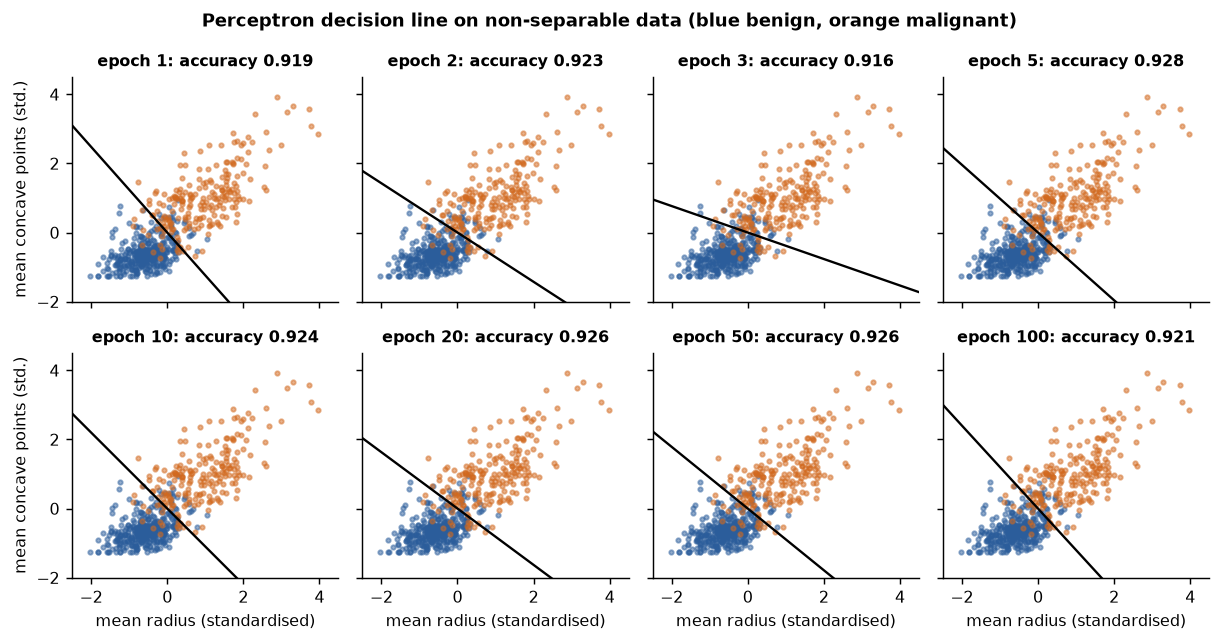

In [12]:
# El perceptrón con dos características de cáncer de mama (estandarizadas). Las clases se superponen: la frontera no deja de moverse.
y_pm = np.where(y_mal == 1, 1, -1)                                 # +1 = maligno, -1 = benigno
snapshots = [1, 2, 3, 5, 10, 20, 50, 100]
w, b, states = np.zeros(2), 0.0, {}
for epoch in range(1, 101):
    for xi, yi in zip(Z2, y_pm):
        if yi * (w @ xi + b) <= 0: w = w + yi * xi; b = b + yi        # eta = 1; error si sign(z) != y
    if epoch in snapshots: states[epoch] = (w.copy(), b, np.mean(np.where(Z2 @ w + b >= 0, 1, -1) == y_pm))
print("training accuracy after epoch:", {e: round(s[2], 3) for e, s in states.items()})

fig, axes = plt.subplots(2, 4, figsize=(9.5, 5.0), sharex=True, sharey=True)
xs = np.linspace(-2.5, 4.5, 2)
for ax, epoch in zip(axes.ravel(), snapshots):
    w_e, b_e, acc_e = states[epoch]
    ax.scatter(*Z2[y_pm == -1].T, s=6, color=BLUE, alpha=0.5); ax.scatter(*Z2[y_pm == 1].T, s=6, color=ORANGE, alpha=0.5)
    ax.plot(xs, -(w_e[0] * xs + b_e) / w_e[1], "k-", lw=1.3)
    ax.set_title(f"epoch {epoch}: accuracy {acc_e:.3f}", fontsize=9); ax.set_xlim(-2.5, 4.5); ax.set_ylim(-2, 4.5)
for ax in axes[1]: ax.set_xlabel("mean radius (standardised)")
for ax in axes[:, 0]: ax.set_ylabel("mean concave points (std.)")
fig.suptitle("Perceptron decision line on non-separable data (blue benign, orange malignant)", fontsize=10, fontweight="bold")
fig.tight_layout()

<p class="caption"><b>Figura 7.</b> La recta de decisión del perceptrón después de 1, 2, 3, 5, 10, 20, 50 y 100 épocas en el problema de cáncer de mama con dos características. La exactitud de entrenamiento ya es de alrededor de 0.92 después de la primera época y luego <em>fluctúa</em> en lugar de mejorar, porque cada época contiene casos mal clasificados que mueven la recta; el algoritmo nunca termina, y la recta de la época 100 no es mejor que la de la época 5. Con datos no separables, los pesos finales del perceptrón dependen de cuándo se decida detenerlo, una elección arbitraria que los métodos de la Sección 7.5 y de la Unidad 2 eliminan al minimizar una pérdida en lugar de perseguir cero errores.</p>

AND: mistakes per epoch [2, 3, 3, 2, 1, 0]
XOR: mistakes per epoch [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4] -> minimum 3 per epoch, never 0


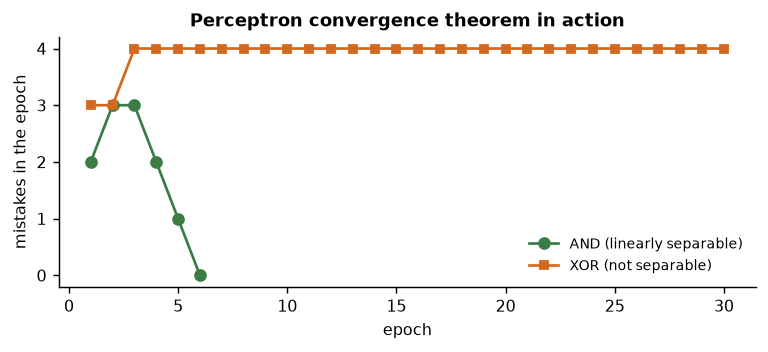

In [13]:
# Errores por época: el perceptrón converge en AND (separable) y nunca lo hace en XOR (no separable).
X_xor = X_bool.astype(float); y_xor = np.array([-1, 1, 1, -1])
_, _, hist_and = perceptron_fit(X_and, y_and, max_epochs=30)
_, _, hist_xor = perceptron_fit(X_xor, y_xor, max_epochs=30)
print("AND: mistakes per epoch", hist_and)
print("XOR: mistakes per epoch", hist_xor, f"-> minimum {min(hist_xor)} per epoch, never 0")

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(range(1, len(hist_and) + 1), hist_and, "o-", color=GREEN, label="AND (linearly separable)")
ax.plot(range(1, len(hist_xor) + 1), hist_xor, "s-", color=ORANGE, ms=4, label="XOR (not separable)")
ax.set_xlabel("epoch"); ax.set_ylabel("mistakes in the epoch"); ax.set_yticks([0, 1, 2, 3, 4]); ax.legend(frameon=False, fontsize=8)
ax.set_title("Perceptron convergence theorem in action"); fig.tight_layout()

<p class="caption"><b>Figura 8.</b> Errores por época de la regla del perceptrón en AND y en XOR. En AND el conteo llega a cero en la sexta época y el algoritmo se detiene, tal como garantiza el teorema de convergencia. En XOR el conteo nunca llega a cero dentro de las 30 épocas permitidas —ni lo haría en 30 millones—, porque no existe ninguna recta separadora; los pesos recorren cíclicamente un conjunto finito de estados para siempre. Este es el experimento detrás de la crítica de Minsky y Papert.<sup class="c"><a href="#r3">[3]</a></sup></p>

### 7.5 Adaline, la regla delta y el vínculo con el descenso de gradiente

Dos años después de Rosenblatt, Widrow y Hoff propusieron una unidad que se diferencia del perceptrón en un solo aspecto, pero de grandes consecuencias.<sup class="c"><a href="#r24">[24]</a></sup> El <strong>Adaline</strong> (adaptive linear neuron, neurona lineal adaptativa) compara el objetivo no con la salida umbralizada $\hat{y} = \text{sign}(z)$, sino con la propia salida <em>lineal</em> $z = \mathbf{w}^\top\mathbf{x} + b$, y minimiza el error cuadrático $L = \tfrac{1}{2}(y - z)^2$ mediante descenso de gradiente. Como $\partial L / \partial \mathbf{w} = -(y - z)\,\mathbf{x}$, la actualización es

<div class="eq">$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y - z)\,\mathbf{x}, \qquad b \leftarrow b + \eta\,(y - z),$$
<span class="where">la <strong>regla delta</strong> (regla de Widrow–Hoff, regla LMS), llamada así por el error $\delta = y - z$.</span></div>

Tres cosas cambian respecto de la regla del perceptrón: la actualización se aplica a <em>todos</em> los ejemplos, escalada según cuán equivocada esté la salida lineal; la pérdida es suave y convexa, de modo que el descenso de gradiente converge a su mínimo único tanto si los datos son separables como si no; y ahora el tamaño del paso $\eta$ importa: si es demasiado grande diverge y si es demasiado pequeño avanza a paso de tortuga (Sección 9.1). Si se reemplaza el error cuadrático por la entropía cruzada y la salida lineal por una sigmoide, el Adaline se convierte en la regresión logística de la Unidad 2; la Sección 8 generaliza su "error por entrada" a unidades ocultas cuyo error no es directamente observable. La celda aplica el Adaline a las mismas dos características con tres tasas de aprendizaje.

correlation of the two standardised features = 0.823 -> gradient descent diverges for eta > 2/(1+rho) = 1.10
eta = 0.01 : loss after 60 epochs =     0.218, training accuracy = 0.902
eta = 0.3  : loss after 60 epochs =     0.174, training accuracy = 0.910
eta = 1.15 : loss after 60 epochs =  1.73e+04, training accuracy = 0.074


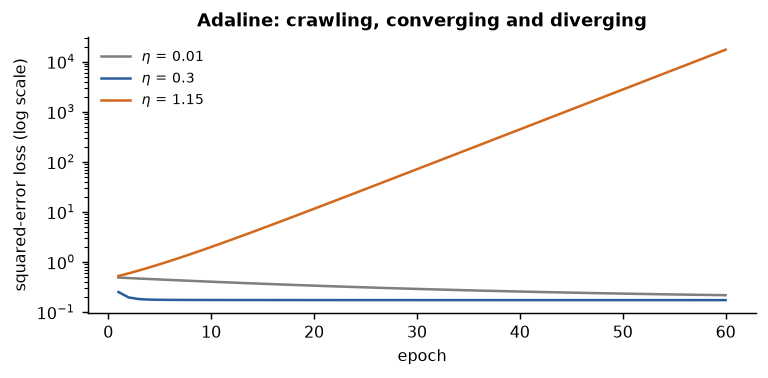

In [14]:
# Adaline (regla delta) con las mismas dos características: descenso de gradiente con lote completo sobre el error cuadrático, tres tasas de aprendizaje.
def adaline_fit(X, y, eta, epochs=60):
    '''Full-batch gradient descent on L = mean 0.5 (y - z)^2 with z = X w + b; returns the loss per epoch.'''
    w, b, losses = np.zeros(X.shape[1]), 0.0, []
    for _ in range(epochs):
        z = X @ w + b; err = y - z
        w = w + eta * X.T @ err / len(y); b = b + eta * err.mean()
        losses.append(0.5 * np.mean((y - (X @ w + b)) ** 2))
    return w, b, np.array(losses)

rho = np.corrcoef(Z2.T)[0, 1]
print(f"correlation of the two standardised features = {rho:.3f} -> gradient descent diverges for eta > 2/(1+rho) = {2/(1+rho):.2f}")
fig, ax = plt.subplots(figsize=(6, 3.0))
for eta, col in ((0.01, GREY), (0.3, BLUE), (1.15, ORANGE)):
    w_a, b_a, losses = adaline_fit(Z2, y_pm.astype(float), eta)
    acc = np.mean(np.where(Z2 @ w_a + b_a >= 0, 1, -1) == y_pm)
    print(f"eta = {eta:<5}: loss after 60 epochs = {losses[-1]:9.3g}, training accuracy = {acc:.3f}")
    ax.plot(range(1, 61), losses, color=col, lw=1.4, label=f"$\\eta$ = {eta}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("squared-error loss (log scale)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Adaline: crawling, converging and diverging"); fig.tight_layout()

<p class="caption"><b>Figura 9.</b> Pérdida por época del Adaline para tres tasas de aprendizaje. Con $\eta = 0.01$ la pérdida disminuye, pero no ha convergido después de 60 épocas; con $\eta = 0.3$ alcanza su mínimo en unas veinte; con $\eta = 1.15$, justo por encima del umbral de estabilidad, cada paso sobrepasa el mínimo en más de lo que gana y la pérdida <em>crece</em> exponencialmente: divergencia. Para una pérdida cuadrática convexa el umbral es exacto: el descenso de gradiente con lote completo diverge cuando $\eta$ supera $2/\lambda_{\max}$, donde $\lambda_{\max}$ es el mayor valor propio de la matriz de covarianza de las características; para dos características estandarizadas con correlación $\rho$, $\lambda_{\max} = 1 + \rho$, lo que da el umbral impreso sobre la figura (alrededor de 1.1). La exactitud con $\eta = 0.3$ —alrededor de 0.91— es cercana a la del perceptrón, pero el Adaline la alcanzó mediante un procedimiento que se detiene.</p>

<div class="box bridge"><h4>Puente con la Unidad 2</h4><p>El Adaline es exactamente la regresión lineal de la Unidad 2, ajustada por descenso de gradiente en lugar de mediante las ecuaciones normales, con la clase codificada como $\pm 1$. La regla delta, el paso de gradiente de la Unidad 2 para la regresión logística y la retropropagación de la sección siguiente son la misma instrucción —<em>mover cada peso en proporción al error multiplicado por la entrada que ese peso multiplica</em>— aplicada a modelos de profundidad creciente.</p></div>

## 8. El perceptrón multicapa

### 8.1 Arquitectura y propagación hacia adelante

Un <strong>perceptrón multicapa</strong> es una red prealimentada con al menos una capa oculta, en la que cada capa está totalmente conectada con la siguiente. Pese al nombre, sus unidades no son perceptrones en el sentido de Rosenblatt: usan activaciones diferenciables (sigmoide, tanh, ReLU) en lugar del escalón, precisamente para que la red pueda entrenarse con descenso de gradiente. El cálculo de la capa $l$, para los $n$ casos de entrenamiento a la vez, es un producto de matrices seguido de una activación elemento a elemento:

<div class="eq">$$\mathbf{Z}^{(l)} = \mathbf{A}^{(l-1)} \mathbf{W}^{(l)} + \mathbf{b}^{(l)}, \qquad \mathbf{A}^{(l)} = \varphi^{(l)}\!\left(\mathbf{Z}^{(l)}\right), \qquad \mathbf{A}^{(0)} = \mathbf{X},$$
<span class="where">donde $\mathbf{X}$ es la matriz de datos de $n \times n_0$, $\mathbf{W}^{(l)}$ es de $n_{l-1} \times n_l$, $\mathbf{b}^{(l)}$ es una fila de $n_l$ sesgos que se suma a cada fila (broadcasting), y $\mathbf{Z}^{(l)}$ y $\mathbf{A}^{(l)}$ son de $n \times n_l$. La salida $\hat{\mathbf{Y}} = \mathbf{A}^{(L)}$ es de $n \times n_L$. Esto es la <strong>propagación hacia adelante</strong> (forward propagation).</span></div>

Para la red 30-16-1 con los datos de cáncer de mama: $\mathbf{X}$ es de $569 \times 30$, $\mathbf{W}^{(1)}$ es de $30 \times 16$, $\mathbf{A}^{(1)}$ es de $569 \times 16$ (las dieciséis características aprendidas de cada caso), $\mathbf{W}^{(2)}$ es de $16 \times 1$ y $\hat{\mathbf{y}}$ es una columna de 569 probabilidades.

### 8.2 Funciones de pérdida

El entrenamiento necesita un número, que se minimizará, que diga cuán equivocada está la red en la muestra de entrenamiento. Para la <strong>regresión</strong> con una unidad de salida lineal, la elección natural es el <strong>error cuadrático medio</strong>, $L = \frac{1}{n}\sum_i (\hat{y}_i - y_i)^2$, como en la Unidad 2. Para la <strong>clasificación binaria</strong> con una salida sigmoide interpretada como $\hat{y} = P(y = 1 \mid \mathbf{x})$, la pérdida es la <strong>entropía cruzada binaria</strong> (log-verosimilitud negativa del modelo de Bernoulli),

$$ L = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \ln \hat{y}_i + (1 - y_i) \ln (1 - \hat{y}_i) \right], $$

y para $K$ clases con salida softmax y objetivos codificados one-hot $y_{ik}$, la <strong>entropía cruzada categórica</strong> $L = -\frac{1}{n}\sum_i \sum_k y_{ik} \ln \hat{y}_{ik}$. Para clasificación se prefiere la entropía cruzada al error cuadrático por una razón que se hace visible en la derivación siguiente: con una salida sigmoide y entropía cruzada, la señal de error en la salida es simplemente $\hat{y} - y$, mientras que con error cuadrático es $(\hat{y} - y)\,\sigma'(z)$, que se desvanece cuando la unidad de salida está saturada; una red que se equivoca con mucha confianza aprendería entonces casi nada de su error. La misma simplificación vale para softmax con entropía cruzada categórica: la derivada de la pérdida respecto de los logits es $\hat{\mathbf{y}} - \mathbf{y}$. El seguimiento a mano de la Sección 8.4 usa el error cuadrático para que todos los factores queden a la vista; la implementación general de la Sección 8.6 usa entropía cruzada.

### 8.3 Retropropagación: la regla de la cadena, organizada

La minimización se hace por descenso de gradiente, $\theta \leftarrow \theta - \eta\, \partial L / \partial \theta$ para cada peso y sesgo, de modo que todo el problema consiste en calcular las derivadas parciales. Para una red con capas ocultas ese es un problema de contabilidad, y la <strong>retropropagación</strong> (backpropagation) es esa contabilidad: una organización eficiente de la regla de la cadena, descubierta varias veces y llevada a la atención del campo por Rumelhart, Hinton y Williams en 1986.<sup class="c"><a href="#r4">[4]</a></sup> Su idea es definir, para cada unidad, la derivada de la pérdida respecto de la <em>preactivación</em> de esa unidad, $\delta = \partial L / \partial z$, y notar que el $\delta$ de una capa puede calcularse a partir del $\delta$ de la capa siguiente; así, las derivadas se calculan hacia atrás, desde la salida hasta la entrada, en una sola pasada que cuesta aproximadamente lo mismo que la pasada hacia adelante.

Toma una red 2-2-1 con activaciones sigmoides en todas partes y la pérdida de error cuadrático para un ejemplo, $L = \tfrac{1}{2}(a^{(2)} - y)^2$. Hacia adelante: $z_j^{(1)} = \sum_i W^{(1)}_{ij} x_i + b^{(1)}_j$, $a_j^{(1)} = \sigma(z_j^{(1)})$ para $j = 1, 2$; $z^{(2)} = \sum_j W^{(2)}_j a_j^{(1)} + b^{(2)}$, $a^{(2)} = \sigma(z^{(2)})$. Hacia atrás, por la regla de la cadena:

**Unidad de salida.** $\delta^{(2)} = \dfrac{\partial L}{\partial z^{(2)}} = \dfrac{\partial L}{\partial a^{(2)}} \dfrac{\partial a^{(2)}}{\partial z^{(2)}} = (a^{(2)} - y)\; a^{(2)} (1 - a^{(2)})$. Luego, como $z^{(2)}$ depende linealmente de cada peso, $\dfrac{\partial L}{\partial W^{(2)}_j} = \delta^{(2)} a_j^{(1)}$ y $\dfrac{\partial L}{\partial b^{(2)}} = \delta^{(2)}$: "error por entrada", la regla delta.

**Unidades ocultas.** La unidad oculta $j$ afecta a $L$ solo a través de $z^{(2)}$, de modo que $\delta^{(1)}_j = \dfrac{\partial L}{\partial z^{(1)}_j} = \dfrac{\partial L}{\partial z^{(2)}} \dfrac{\partial z^{(2)}}{\partial a^{(1)}_j} \dfrac{\partial a^{(1)}_j}{\partial z^{(1)}_j} = \delta^{(2)}\, W^{(2)}_j\; a_j^{(1)}(1 - a_j^{(1)})$: el error de salida se envía <em>de vuelta a lo largo del peso</em> que conecta las dos unidades y se escala por la derivada de la activación oculta. Luego, $\dfrac{\partial L}{\partial W^{(1)}_{ij}} = \delta^{(1)}_j x_i$ y $\dfrac{\partial L}{\partial b^{(1)}_j} = \delta^{(1)}_j$.

El patrón se generaliza a cualquier profundidad. En forma matricial, para un minilote, con $\odot$ el producto elemento a elemento:

<div class="eq">$$\boldsymbol{\Delta}^{(L)} = \frac{\partial L}{\partial \mathbf{Z}^{(L)}}, \qquad \boldsymbol{\Delta}^{(l)} = \left(\boldsymbol{\Delta}^{(l+1)} \mathbf{W}^{(l+1)\top}\right) \odot \varphi'\!\left(\mathbf{Z}^{(l)}\right), \qquad \frac{\partial L}{\partial \mathbf{W}^{(l)}} = \mathbf{A}^{(l-1)\top} \boldsymbol{\Delta}^{(l)}, \qquad \frac{\partial L}{\partial \mathbf{b}^{(l)}} = \mathbf{1}^\top \boldsymbol{\Delta}^{(l)}.$$
<span class="where">Para una salida sigmoide con entropía cruzada, o una salida softmax con entropía cruzada categórica, $\boldsymbol{\Delta}^{(L)} = (\hat{\mathbf{Y}} - \mathbf{Y})/n$. Estas cuatro líneas son la totalidad del método <code>backward</code> de la Sección 8.6.</span></div>

### 8.4 Ejemplo resuelto a mano: un paso de entrenamiento de la red 2-2-1

Toma el ejemplo de XOR $\mathbf{x} = (1, 1)$ con objetivo $y = 0$, tasa de aprendizaje $\eta = 0.5$ y los pesos

$$\mathbf{W}^{(1)} = \begin{pmatrix} 0.5 & -0.5 \\ 0.3 & 0.8 \end{pmatrix}, \quad \mathbf{b}^{(1)} = (0.1, -0.2), \quad \mathbf{W}^{(2)} = (0.6, -0.4), \quad b^{(2)} = 0.2,$$

con la convención, para este ejemplo a mano y para la celda que lo comprueba, de que <em>la fila $j$ de $\mathbf{W}^{(1)}$ contiene los pesos que entran a la unidad oculta $j$</em>, de modo que $z^{(1)}_j = \sum_i W^{(1)}_{ji} x_i + b^{(1)}_j$, es decir, $\mathbf{z}^{(1)} = \mathbf{W}^{(1)}\mathbf{x} + \mathbf{b}^{(1)}$. (La forma matricial de la Sección 8.1 usa la traspuesta, $\mathbf{X}\mathbf{W}$, porque allí los casos son filas; los libros de texto difieren, y la única regla es usar una convención de forma consistente).

**Pasada hacia adelante.**
$z^{(1)}_1 = 0.5 \times 1 + (-0.5) \times 1 + 0.1 = 0.1$, $\quad z^{(1)}_2 = 0.3 \times 1 + 0.8 \times 1 - 0.2 = 0.9$, de modo que
$z^{(1)} = (0.1,\ 0.9)$, $\quad a^{(1)} = (\sigma(0.1), \sigma(0.9)) = (0.5250,\ 0.7109)$,
$z^{(2)} = 0.6 \times 0.5250 - 0.4 \times 0.7109 + 0.2 = 0.3150 - 0.2844 + 0.2 = 0.2306$, $\quad a^{(2)} = \sigma(0.2306) = 0.5574$,
$L = \tfrac{1}{2}(0.5574 - 0)^2 = 0.1553$.

**Pasada hacia atrás.**
$\delta^{(2)} = (a^{(2)} - y)\,a^{(2)}(1 - a^{(2)}) = 0.5574 \times 0.5574 \times 0.4426 = 0.1375$.
$\partial L/\partial W^{(2)} = \delta^{(2)} a^{(1)} = (0.1375 \times 0.5250,\ 0.1375 \times 0.7109) = (0.0722,\ 0.0978)$; $\quad \partial L/\partial b^{(2)} = 0.1375$.
$\delta^{(1)}_1 = \delta^{(2)} W^{(2)}_1\, a^{(1)}_1 (1 - a^{(1)}_1) = 0.1375 \times 0.6 \times 0.5250 \times 0.4750 = 0.0206$;
$\delta^{(1)}_2 = 0.1375 \times (-0.4) \times 0.7109 \times 0.2891 = -0.0113$.
$\partial L/\partial W^{(1)}_{j i} = \delta^{(1)}_j x_i$: ambas entradas valen 1, así que la fila 1 del gradiente es $(0.0206, 0.0206)$ y la fila 2 es $(-0.0113, -0.0113)$; $\quad \partial L/\partial b^{(1)} = (0.0206, -0.0113)$.

**Actualización** ($\theta \leftarrow \theta - 0.5\, \partial L/\partial\theta$).
$W^{(2)} \leftarrow (0.6 - 0.0361,\ -0.4 - 0.0489) = (0.5639,\ -0.4489)$, $\quad b^{(2)} \leftarrow 0.2 - 0.0688 = 0.1312$;
$W^{(1)} \leftarrow \begin{pmatrix} 0.4897 & -0.5103 \\ 0.3057 & 0.8057 \end{pmatrix}$, $\quad b^{(1)} \leftarrow (0.0897,\ -0.1943)$.

Observa la dirección de cada cambio: la salida fue 0.5574 para un objetivo de 0, así que $W^{(2)}_1$, que multiplica una activación oculta positiva, disminuyó, y $W^{(2)}_2$, que ya era negativo, se hizo más negativo; ambos empujan $z^{(2)}$ hacia abajo. Los cambios en la capa oculta son un orden de magnitud menores que los de la capa de salida: en su camino de vuelta, el error se ha multiplicado por un peso de magnitud $\leq 0.6$ y por una derivada de la sigmoide $\leq 0.25$. Una capa más lo reduciría de nuevo; este es, en miniatura, el gradiente que se desvanece de la Sección 9.6. La celda reproduce cada número y luego comprueba el gradiente contra una diferencia finita.

In [15]:
# Retropropagación a mano, en código: pasada hacia adelante, deltas, gradientes y actualización para el ejemplo 2-2-1.
x_ex, y_ex, eta = np.array([1.0, 1.0]), 0.0, 0.5
W1 = np.array([[0.5, -0.5], [0.3, 0.8]]); b1 = np.array([0.1, -0.2])     # fila j = pesos que ENTRAN a la unidad oculta j
W2 = np.array([0.6, -0.4]); b2 = 0.2

z1 = W1 @ x_ex + b1; a1 = expit(z1)                   # capa oculta
z2 = W2 @ a1 + b2;   a2 = expit(z2)                   # unidad de salida
loss = 0.5 * (a2 - y_ex) ** 2
print(f"forward : z1 = {z1.round(4)}, a1 = {a1.round(4)}, z2 = {z2:.4f}, a2 = {a2:.4f}, loss = {loss:.4f}")

d2 = (a2 - y_ex) * a2 * (1 - a2)                      # delta en la salida
gW2, gb2 = d2 * a1, d2
d1 = d2 * W2 * a1 * (1 - a1)                          # deltas en las unidades ocultas: el error se envía de vuelta a lo largo de W2
gW1, gb1 = np.outer(d1, x_ex), d1
print(f"backward: delta2 = {d2:.4f}, dL/dW2 = {gW2.round(4)}, dL/db2 = {gb2:.4f}")
print(f"          delta1 = {d1.round(4)}, dL/dW1 =\n{gW1.round(4)}, dL/db1 = {gb1.round(4)}")
print(f"update  : W2 -> {(W2 - eta * gW2).round(4)}, b2 -> {b2 - eta * gb2:.4f}")
print(f"          W1 ->\n{(W1 - eta * gW1).round(4)}, b1 -> {(b1 - eta * gb1).round(4)}")

# Comprobación por diferencias finitas de una derivada parcial: perturbar W1[0,0] en +-1e-6 y recalcular la pérdida.
def loss_of(W1_):
    return 0.5 * (expit(W2 @ expit(W1_ @ x_ex + b1) + b2) - y_ex) ** 2
h = 1e-6; Wp, Wm = W1.copy(), W1.copy(); Wp[0, 0] += h; Wm[0, 0] -= h
print(f"\ncheck   : dL/dW1[0,0] by backprop = {gW1[0, 0]:.7f}, by finite difference = {(loss_of(Wp) - loss_of(Wm)) / (2 * h):.7f}")

forward : z1 = [0.1 0.9], a1 = [0.525  0.7109], z2 = 0.2306, a2 = 0.5574, loss = 0.1553
backward: delta2 = 0.1375, dL/dW2 = [0.0722 0.0978], dL/db2 = 0.1375
          delta1 = [ 0.0206 -0.0113], dL/dW1 =
[[ 0.0206  0.0206]
 [-0.0113 -0.0113]], dL/db1 = [ 0.0206 -0.0113]
update  : W2 -> [ 0.5639 -0.4489], b2 -> 0.1312
          W1 ->
[[ 0.4897 -0.5103]
 [ 0.3057  0.8057]], b1 -> [ 0.0897 -0.1943]

check   : dL/dW1[0,0] by backprop = 0.0205755, by finite difference = 0.0205755


Cada número del seguimiento a mano se reproduce con cuatro decimales, y la derivada por diferencias finitas —la pérdida recalculada con un peso empujado hacia arriba y hacia abajo— coincide con la retropropagada hasta el séptimo decimal. La comprobación por diferencias finitas es demasiado lenta para entrenar (dos pasadas hacia adelante por parámetro), pero es la forma estándar de verificar una implementación, y la Sección 8.7 la aplica a la clase general.

### 8.5 Entrenar XOR hasta la convergencia

Repetir el paso de la Sección 8.4 sobre los cuatro patrones de XOR, miles de veces, es entrenar. La celda siguiente lo hace con descenso de gradiente con lote completo sobre el error cuadrático y la misma arquitectura 2-2-1, partiendo de pesos aleatorios con <code>random_state=0</code>, y luego muestra la función que la red ha aprendido sobre todo el cuadrado unitario.

loss at epochs 1, 1000, 5000, 10000: [np.float64(0.1257), np.float64(0.125), np.float64(0.0023), np.float64(0.0004)]
network output for (0,0), (0,1), (1,0), (1,1): [0.03  0.972 0.966 0.027] -> rounded: [0 1 1 0]
learned hidden units: W1 =
 [[-5.8  -5.37]
 [ 5.91  5.17]] 
b1 = [ 2.96 -2.81] | output: W2 = [-8.17  8.65] b2 = [3.8]


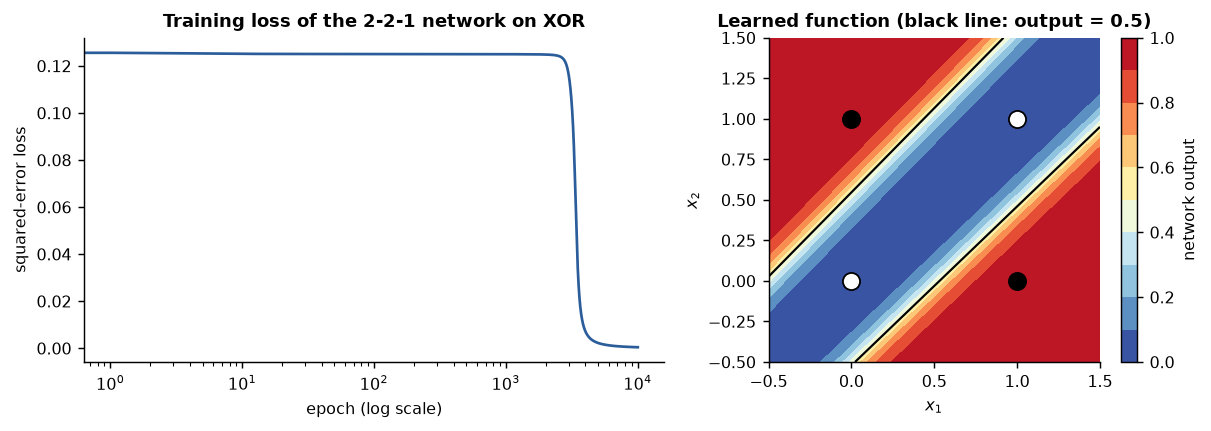

In [16]:
# Entrenamiento de la red sigmoide 2-2-1 sobre XOR con descenso de gradiente con lote completo (pérdida de error cuadrático, como en el seguimiento a mano).
rng = np.random.default_rng(0)
X_xor01 = X_bool.astype(float); y_xor01 = np.array([0.0, 1.0, 1.0, 0.0])
W1 = rng.normal(0, 1, (2, 2)); b1 = np.zeros(2); W2 = rng.normal(0, 1, (2, 1)); b2 = np.zeros(1)
losses = []
for epoch in range(10000):
    A1 = expit(X_xor01 @ W1 + b1); A2 = expit(A1 @ W2 + b2)             # hacia adelante (filas = casos; aquí W1 es entrada x oculta)
    D2 = (A2 - y_xor01[:, None]) * A2 * (1 - A2) / 4                    # deltas de salida, promediados sobre los 4 casos
    D1 = (D2 @ W2.T) * A1 * (1 - A1)                                    # deltas ocultos
    W2 -= 1.0 * A1.T @ D2; b2 -= 1.0 * D2.sum(0); W1 -= 1.0 * X_xor01.T @ D1; b1 -= 1.0 * D1.sum(0)
    losses.append(0.5 * np.mean((A2.ravel() - y_xor01) ** 2))
out = expit(expit(X_xor01 @ W1 + b1) @ W2 + b2).ravel()
print("loss at epochs 1, 1000, 5000, 10000:", [round(losses[i], 4) for i in (0, 999, 4999, 9999)])
print("network output for (0,0), (0,1), (1,0), (1,1):", out.round(3), "-> rounded:", (out >= 0.5).astype(int))
print("learned hidden units: W1 =\n", W1.round(2), "\nb1 =", b1.round(2), "| output: W2 =", W2.ravel().round(2), "b2 =", b2.round(2))

xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid_out = expit(expit(np.c_[xx.ravel(), yy.ravel()] @ W1 + b1) @ W2 + b2).reshape(xx.shape)
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].plot(losses, color=BLUE); axes[0].set_xscale("log"); axes[0].set_xlabel("epoch (log scale)"); axes[0].set_ylabel("squared-error loss")
axes[0].set_title("Training loss of the 2-2-1 network on XOR")
cs = axes[1].contourf(xx, yy, grid_out, levels=np.linspace(0, 1, 11), cmap="RdYlBu_r"); fig.colorbar(cs, ax=axes[1], label="network output")
axes[1].contour(xx, yy, grid_out, levels=[0.5], colors="k", linewidths=1.2)
axes[1].scatter(*X_bool[y_xor01 == 0].T, s=90, color="white", edgecolor="k", zorder=3); axes[1].scatter(*X_bool[y_xor01 == 1].T, s=90, color="k", zorder=3)
axes[1].set_xlabel("$x_1$"); axes[1].set_ylabel("$x_2$"); axes[1].set_title("Learned function (black line: output = 0.5)"); fig.tight_layout()

<p class="caption"><b>Figura 10.</b> Izquierda: la pérdida de error cuadrático durante 10,000 épocas de descenso de gradiente sobre XOR. La pérdida se mantiene en una meseta en 0.125 durante aproximadamente las primeras tres mil épocas —la salida de la red es de alrededor de 0.5 para todos los patrones— y luego cae bruscamente una vez que las unidades ocultas se han diferenciado. Derecha: la función aprendida sobre el cuadrado unitario. Cada una de las dos unidades ocultas ha aprendido una recta, ambas casi paralelas a la diagonal $x_1 = x_2$, y la unidad de salida asigna una salida baja a la franja entre ellas, que contiene $(0,0)$ y $(1,1)$ (puntos blancos), y una salida alta fuera de ella, donde se encuentran $(0,1)$ y $(1,0)$ (puntos negros). La frontera de decisión (salida = 0.5) está formada por dos rectas: exactamente la geometría que la Sección 6.3 demostró que una unidad individual no puede producir.</p>

Los pesos impresos muestran cómo resolvió la red el problema: cada unidad oculta implementa una subfunción linealmente separable —aquí los dos semiplanos $x_2 - x_1 > -0.5$ y $x_2 - x_1 > 0.5$, que se leen en las columnas de $\mathbf{W}^{(1)}$ y $\mathbf{b}^{(1)}$— y la unidad de salida las combina. Esta es una descomposición distinta de la OR–NAND del Ejercicio 2; ambas son válidas, y cuál encuentra el descenso de gradiente depende de los pesos iniciales, un primer ejemplo de la no convexidad de la Sección 4.2. Minsky y Papert sabían en 1969 que esta arquitectura <em>representa</em> XOR; lo que dudaban era que algún procedimiento pudiera <em>aprender</em> los pesos de la capa oculta solo a partir de pares de entrada y salida, ya que nadie les dice a las unidades ocultas qué deben calcular.<sup class="c"><a href="#r3">[3]</a></sup> La retropropagación responde a esa duda: las unidades ocultas reciben su señal de error desde la salida mediante la regla de la cadena.

<div class="exercise"><h4>Ejercicio 3</h4><p>Cambia la semilla en <code>default_rng(0)</code> a 1, 2, 3, 4 y vuelve a ejecutar. ¿Converge siempre la red en 10,000 épocas? Compara las pérdidas finales y las funciones aprendidas. Luego reemplaza el gradiente del error cuadrático <code>(A2 - y) * A2 * (1 - A2)</code> por el gradiente de la entropía cruzada <code>(A2 - y)</code> y observa cómo cambia la meseta del comienzo del entrenamiento. La Sección 8.2 explica por qué.</p></div>

### 8.6 Un MLP general en numpy

El código de XOR deja fijas dos capas. La clase siguiente implementa las ecuaciones matriciales de las Secciones 8.1 y 8.3 para cualquier lista de tamaños de capa, con la opción de elegir la activación oculta (sigmoide o ReLU), inicialización de Glorot o gaussiana (Sección 9.3), una penalización L2 opcional (Sección 9.5) y una salida sigmoide entrenada con la entropía cruzada binaria. <code>MLPClassifier</code> de scikit-learn hace lo mismo con más opciones y mejores optimizadores, y se usa a partir de la Sección 9.7; esta clase es la que conviene leer línea por línea junto a las ecuaciones.

In [17]:
# Un perceptrón multicapa general para clasificación binaria: propagación hacia adelante, retropropagación, predicción.
class MLP:
    '''sizes = [n_in, h1, ..., 1]; activation 'relu' or 'sigmoid' in the hidden layers; sigmoid output + cross-entropy.
    init = 'glorot' (uniform in +-sqrt(6/(n_in+n_out))) or a number (standard deviation of a Gaussian).'''
    def __init__(self, sizes, activation="relu", init="glorot", l2=0.0, seed=0):
        self.sizes, self.act, self.l2 = sizes, activation, l2
        rng = np.random.default_rng(seed); self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            if init == "glorot": lim = np.sqrt(6 / (n_in + n_out)); self.W.append(rng.uniform(-lim, lim, (n_in, n_out)))
            else:                self.W.append(rng.normal(0, init, (n_in, n_out)))
            self.b.append(np.zeros(n_out))
    def _phi(self, z):      return np.maximum(z, 0) if self.act == "relu" else expit(z)
    def _dphi(self, z, a):  return (z > 0).astype(float) if self.act == "relu" else a * (1 - a)
    def forward(self, X):                                     # Z[l] = A[l-1] W[l] + b[l];  A[l] = phi(Z[l])
        self.Z, self.A = [], [X]
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            z = self.A[-1] @ W + b
            self.Z.append(z); self.A.append(expit(z) if l == len(self.W) - 1 else self._phi(z))
        return self.A[-1].ravel()
    def loss(self, X, y):                                     # entropía cruzada binaria (+ penalización L2)
        p = np.clip(self.forward(X), 1e-12, 1 - 1e-12)
        penalty = 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W) if self.l2 else 0.0
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)) + penalty
    def backward(self, X, y):                                 # devuelve dL/dW y dL/db para cada capa
        n = len(y); self.forward(X)
        delta = (self.A[-1] - y[:, None]) / n                 # Delta(L) = (Yhat - Y)/n para sigmoide + entropía cruzada
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for l in range(len(self.W) - 1, -1, -1):
            gW[l] = self.A[l].T @ delta + self.l2 * self.W[l]; gb[l] = delta.sum(axis=0)
            if l > 0: delta = (delta @ self.W[l].T) * self._dphi(self.Z[l - 1], self.A[l])
        return gW, gb
    def predict_proba(self, X): return self.forward(X)
    def predict(self, X):       return (self.forward(X) >= 0.5).astype(int)
print("MLP class defined:", [m for m in dir(MLP) if not m.startswith("__")])

MLP class defined: ['_dphi', '_phi', 'backward', 'forward', 'loss', 'predict', 'predict_proba']


La clase separa el <em>modelo</em> (cómo calcular la salida y el gradiente) del <em>bucle de entrenamiento</em>, que la celda siguiente agrega como función. El bucle implementa el <strong>descenso de gradiente estocástico por minilotes</strong>: en cada época baraja los casos de entrenamiento, los divide en lotes de tamaño fijo y da un paso de gradiente por lote. Un gradiente estimado a partir de 32 casos es lo bastante bueno para avanzar y cuesta una fracción de uno estimado con todos ellos. El bucle registra la pérdida de entrenamiento, y la de validación si se entrega un conjunto de validación, después de cada época: las <em>curvas de pérdida</em> que son el principal instrumento de diagnóstico de la Sección 9.

training cases 455 (malignant 170), test cases 114 (malignant 42)
30-16-1 sigmoid: final training loss 0.0536, test loss 0.1021, test accuracy 0.947
30-16-1 relu   : final training loss 0.0216, test loss 0.0941, test accuracy 0.956


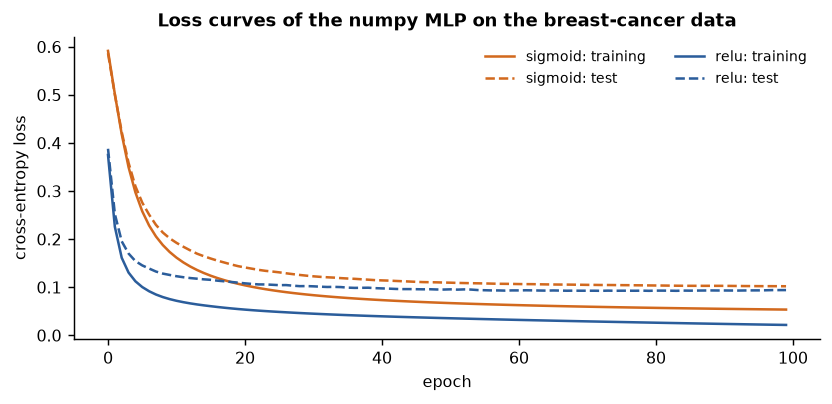

In [18]:
# El bucle de entrenamiento: descenso de gradiente estocástico por minilotes, registrando la pérdida después de cada época.
def train(net, X, y, lr=0.1, epochs=100, batch_size=32, X_val=None, y_val=None, seed=0):
    '''Mini-batch SGD. Returns a dict with the per-epoch training (and validation) loss.'''
    rng = np.random.default_rng(seed); hist = {"train": [], "val": []}
    with np.errstate(all="ignore"):                       # una ejecución que diverge produce inf/nan: registrarlo, sin advertir
        for epoch in range(epochs):
            for idx in np.array_split(rng.permutation(len(y)), max(1, len(y) // batch_size)):
                gW, gb = net.backward(X[idx], y[idx])
                for l in range(len(net.W)):
                    net.W[l] -= lr * gW[l]; net.b[l] -= lr * gb[l]
            hist["train"].append(net.loss(X, y))
            if X_val is not None: hist["val"].append(net.loss(X_val, y_val))
            if not np.isfinite(hist["train"][-1]): break      # divergencia: detener antes
    return hist

# Cáncer de mama, las 30 características: 80 % entrenamiento, 20 % prueba, estandarizadas solo con estadísticos de la parte de entrenamiento.
X_tr, X_te, y_tr, y_te = train_test_split(X_all.to_numpy(), y_mal, test_size=0.2, random_state=0, stratify=y_mal)
scaler = StandardScaler().fit(X_tr); Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)
print(f"training cases {len(y_tr)} (malignant {int(y_tr.sum())}), test cases {len(y_te)} (malignant {int(y_te.sum())})")

fig, ax = plt.subplots(figsize=(6.5, 3.2)); nets = {}
for act, col in (("sigmoid", ORANGE), ("relu", BLUE)):
    nets[act] = MLP([30, 16, 1], activation=act)
    hist = train(nets[act], Z_tr, y_tr, lr=0.1, epochs=100, X_val=Z_te, y_val=y_te)
    ax.plot(hist["train"], color=col, lw=1.4, label=f"{act}: training"); ax.plot(hist["val"], color=col, lw=1.4, ls="--", label=f"{act}: test")
    print(f"30-16-1 {act:7s}: final training loss {hist['train'][-1]:.4f}, test loss {hist['val'][-1]:.4f}, "
          f"test accuracy {np.mean(nets[act].predict(Z_te) == y_te):.3f}")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy loss"); ax.legend(frameon=False, fontsize=8, ncol=2)
ax.set_title("Loss curves of the numpy MLP on the breast-cancer data"); fig.tight_layout()

<p class="caption"><b>Figura 11.</b> Entropía cruzada de entrenamiento (línea continua) y de prueba (línea discontinua) de la red 30-16-1 con unidades ocultas sigmoides y ReLU, durante 100 épocas de SGD por minilotes con tasa de aprendizaje 0.1. Ambas redes alcanzan una exactitud en prueba de alrededor de 0.95, cercana al nivel de los mejores métodos de las Unidades 3–4 con estos datos (la Sección 10 los ajusta como corresponde). La red ReLU desciende más rápido en las primeras épocas, como predice su derivada que no se satura. En ambos casos la pérdida de prueba se aplana mientras la de entrenamiento sigue bajando: la red empieza a ajustar la muestra de entrenamiento mejor de lo que ajusta los casos nuevos, el sobreajuste que la Sección 9.2 aborda con la detención temprana.</p>

### 8.7 Comprobación del gradiente

Es fácil que el código de retropropagación quede sutilmente mal —una matriz traspuesta, una derivada faltante, un índice de capa desplazado en uno— y un gradiente erróneo a menudo igual hace bajar la pérdida, lentamente, de modo que el error pasa inadvertido. La prueba estándar compara el gradiente analítico con la diferencia finita centrada $\left[L(\theta + \epsilon) - L(\theta - \epsilon)\right] / 2\epsilon$ para una muestra de parámetros, y reporta el error relativo $|g_{\text{bp}} - g_{\text{fd}}| / (|g_{\text{bp}}| + |g_{\text{fd}}|)$. Una implementación correcta da errores relativos por debajo de alrededor de $10^{-7}$ en doble precisión; un error de programación da errores del orden de 1.

In [19]:
# Comprobación del gradiente: retropropagación frente a diferencias finitas centradas, para pesos de cada capa elegidos al azar.
net_chk = MLP([30, 8, 4, 1], activation="sigmoid", seed=1); X_s, y_s = Z_tr[:25], y_tr[:25]
gW, gb = net_chk.backward(X_s, y_s); eps = 1e-5; rng = np.random.default_rng(0); rows = []
for l in range(len(net_chk.W)):
    for _ in range(4):
        i, j = rng.integers(net_chk.W[l].shape[0]), rng.integers(net_chk.W[l].shape[1])
        orig = net_chk.W[l][i, j]
        net_chk.W[l][i, j] = orig + eps; L_plus = net_chk.loss(X_s, y_s)
        net_chk.W[l][i, j] = orig - eps; L_minus = net_chk.loss(X_s, y_s)
        net_chk.W[l][i, j] = orig
        g_fd = (L_plus - L_minus) / (2 * eps); g_bp = gW[l][i, j]
        rows.append((l + 1, f"W[{i},{j}]", g_bp, g_fd, abs(g_bp - g_fd) / (abs(g_bp) + abs(g_fd) + 1e-15)))
check = pd.DataFrame(rows, columns=["layer", "weight", "backprop", "finite difference", "relative error"])
print(check.to_string(index=False, float_format=lambda v: f"{v: .3e}"))
print(f"\nlargest relative error: {check['relative error'].max():.2e}")

 layer  weight   backprop  finite difference  relative error
     1 W[25,5] -1.545e-02         -1.545e-02       1.010e-10
     1 W[15,2] -5.656e-03         -5.656e-03       4.749e-10
     1  W[9,0]  4.930e-05          4.930e-05       4.687e-08
     1  W[2,0]  1.262e-04          1.262e-04       6.024e-09
     2  W[1,3] -4.339e-03         -4.339e-03       6.036e-10
     2  W[5,3] -1.804e-02         -1.804e-02       1.747e-11
     2  W[4,2] -2.023e-03         -2.023e-03       3.841e-10
     2  W[7,2] -3.408e-03         -3.408e-03       1.979e-10
     3  W[2,0]  3.700e-02          3.700e-02       2.388e-11
     3  W[2,0]  3.700e-02          3.700e-02       2.388e-11
     3  W[2,0]  3.700e-02          3.700e-02       2.388e-11
     3  W[3,0]  1.106e-01          1.106e-01       9.637e-12

largest relative error: 4.69e-08


Todos los errores relativos están por debajo de $10^{-7}$ —la mayoría del orden de $10^{-10}$, y el mayor corresponde a una derivada que es en sí misma diminuta—, de modo que la implementación de las cuatro ecuaciones de retropropagación es correcta para una red de tres capas con entrada de 30 dimensiones, incluidas las capas que el ejemplo de XOR nunca puso a prueba.

<div class="box key"><h4>Idea clave</h4><p>La retropropagación no es una regla de aprendizaje, sino un método para calcular derivadas: la regla de la cadena aplicada capa por capa desde la salida hacia atrás, reutilizando la cantidad $\delta^{(l)} = \partial L / \partial z^{(l)}$, de modo que el costo del gradiente completo es aproximadamente el doble del costo de una pasada hacia adelante. Luego, el descenso de gradiente usa esas derivadas. Todo framework moderno automatiza exactamente el cálculo de la Sección 8.6 —para cualquier arquitectura— registrando las operaciones hacia adelante y diferenciándolas en sentido inverso (diferenciación automática).</p></div>

## 9. El entrenamiento en la práctica

La retropropagación entrega el gradiente; todo lo demás en el entrenamiento de una red es un conjunto de decisiones que la teoría no toma por ti. Esta sección las revisa en el orden en que suelen causar problemas, con un experimento para cada una, usando la clase de numpy con los datos de cáncer de mama y luego la implementación de scikit-learn.

### 9.1 La tasa de aprendizaje

La tasa de aprendizaje $\eta$ es el hiperparámetro más importante. Si es demasiado pequeña, el entrenamiento tarda miles de épocas en avanzar; si es demasiado grande, cada paso sobrepasa el mínimo, la pérdida oscila y finalmente se vuelve infinita: la divergencia que se vio con el Adaline en la Figura 9, ahora en un problema no convexo donde ninguna fórmula da el umbral. La práctica habitual es probar valores separados por factores de 10, elegir el mayor que haga disminuir la pérdida de forma suave y reducirlo durante el entrenamiento (un <em>calendario de la tasa de aprendizaje</em>, learning-rate schedule). Los métodos adaptativos como Adam, que mantienen una estimación móvil de la media y la varianza del gradiente y escalan el paso para cada parámetro,<sup class="c"><a href="#r28">[28]</a></sup> son la opción por defecto en scikit-learn (<code>solver="adam"</code>) y en todos los frameworks; reducen la sensibilidad a $\eta$, pero no la eliminan.

lr = 0.001 : 60 epochs run, loss after epoch 1 = 0.719, final loss 0.4700
lr = 0.1   : 60 epochs run, loss after epoch 1 = 0.375, final loss 0.0324
lr = 10.0  : 13 epochs run, loss after epoch 1 = 23.866, diverged (loss became inf/nan)


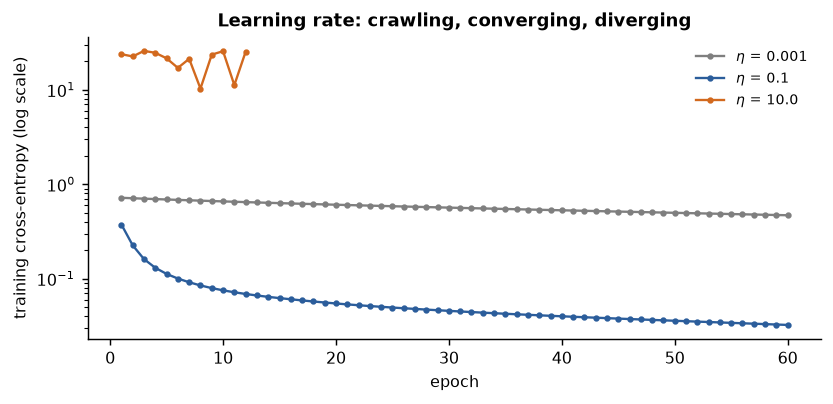

In [20]:
# Tres tasas de aprendizaje en la red ReLU 30-16-1: demasiado pequeña (avanza muy lento), adecuada, demasiado grande (diverge).
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for lr, col in ((0.001, GREY), (0.1, BLUE), (10.0, ORANGE)):
    hist = train(MLP([30, 16, 1], activation="relu"), Z_tr, y_tr, lr=lr, epochs=60)
    status = "diverged (loss became inf/nan)" if not np.isfinite(hist["train"][-1]) else f"final loss {hist['train'][-1]:.4f}"
    print(f"lr = {lr:<6}: {len(hist['train']):2d} epochs run, loss after epoch 1 = {hist['train'][0]:.3f}, {status}")
    ax.plot(range(1, len(hist["train"]) + 1), hist["train"], "o-", ms=2.5, color=col, lw=1.3, label=f"$\\eta$ = {lr}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("training cross-entropy (log scale)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Learning rate: crawling, converging, diverging"); fig.tight_layout()

<p class="caption"><b>Figura 12.</b> Pérdida de entrenamiento para tres tasas de aprendizaje. Con $\eta = 0.001$ la pérdida sigue por encima de 0.4 después de 60 épocas (la red apenas se ha movido de su inicialización); con $\eta = 0.1$ cae por debajo de 0.05; con $\eta = 10$ el primer paso lanza los pesos tan lejos que varias unidades ReLU mueren o se saturan, la pérdida salta por encima de 20 (la salida está equivocada con mucha confianza para una gran fracción de los casos) y, en pocas épocas, los pesos se desbordan hacia infinito y la pérdida queda indefinida. La función de entrenamiento detiene la ejecución en ese punto.</p>

### 9.2 Épocas y detención temprana

Cuánto tiempo entrenar es la segunda decisión, y conviene tomarla observando un <strong>conjunto de validación</strong> —una parte de los datos de entrenamiento que se excluye de los pasos de gradiente, exactamente como en el Suplemento S1— en lugar de fijarla de antemano. Típicamente, la pérdida de validación disminuye al principio junto con la de entrenamiento, luego se aplana y comienza a subir mientras la de entrenamiento sigue bajando: desde ese punto, la red está ajustando los casos de entrenamiento particulares en lugar del patrón que comparten. La <strong>detención temprana</strong> (early stopping) es la regla "detenerse cuando la pérdida de validación no ha mejorado durante $k$ épocas (la <em>paciencia</em>) y conservar los pesos de la mejor época". Es la forma de regularización más barata y más usada en redes neuronales, y scikit-learn la implementa con <code>early_stopping=True</code>, que por defecto reserva el 10 % de los datos de entrenamiento. El experimento siguiente exagera el fenómeno entrenando una red ancha (30-256-1, unos 8,000 parámetros) con solo 80 casos.

8,193 parameters trained on 80 cases
validation loss: minimum 0.1401 at epoch 51, final (epoch 1500) 0.2079  |  training loss at the end 0.00019


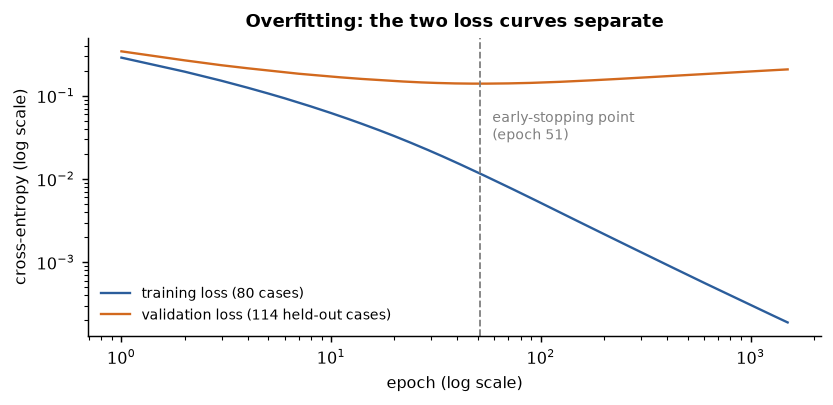

In [21]:
# Sobreajuste y detención temprana: una red ancha entrenada con una muestra pequeña; la pérdida de validación vuelve a subir.
rng = np.random.default_rng(0); small = rng.choice(len(y_tr), 80, replace=False)
net_small = MLP([30, 256, 1], activation="relu")
hist = train(net_small, Z_tr[small], y_tr[small], lr=0.1, epochs=1500, batch_size=16, X_val=Z_te, y_val=y_te)
val = np.array(hist["val"]); best = int(np.argmin(val)) + 1
print(f"{n_parameters([30, 256, 1]):,} parameters trained on 80 cases")
print(f"validation loss: minimum {val.min():.4f} at epoch {best}, final (epoch 1500) {val[-1]:.4f}  |  "
      f"training loss at the end {hist['train'][-1]:.5f}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(range(1, 1501), hist["train"], color=BLUE, lw=1.3, label="training loss (80 cases)")
ax.plot(range(1, 1501), val, color=ORANGE, lw=1.3, label=f"validation loss ({len(y_te)} held-out cases)")
ax.axvline(best, color=GREY, ls="--", lw=1); ax.text(best * 1.15, 0.03, f"early-stopping point\n(epoch {best})", fontsize=8, color=GREY)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("epoch (log scale)"); ax.set_ylabel("cross-entropy (log scale)")
ax.legend(frameon=False, fontsize=8); ax.set_title("Overfitting: the two loss curves separate"); fig.tight_layout()

<p class="caption"><b>Figura 13.</b> Pérdida de entrenamiento y de validación de una red 30-256-1 entrenada con 80 casos durante 1,500 épocas. La pérdida de entrenamiento disminuye de forma monótona hacia cero: la red puede memorizar 80 casos con 8,000 parámetros sin dificultad. La pérdida de validación alcanza su mínimo alrededor de la época 50 y luego sube de manera sostenida: cada época adicional hace que la red sea <em>peor</em> con pacientes nuevos mientras la hace mejor con los de entrenamiento. La detención temprana habría conservado los pesos de la época marcada. Observa los ejes log–log: la separación comienza temprano y continúa durante toda la ejecución.</p>

### 9.3 Inicialización de los pesos

El descenso de gradiente debe comenzar en algún lugar, y el punto de partida importa más en las redes que en los modelos convexos. Comenzar con todos los pesos en cero es fatal: cada unidad oculta recibe entonces la misma entrada y el mismo gradiente, de modo que todas las unidades de una capa permanecen idénticas para siempre, y la red se comporta como si tuviera una sola unidad oculta (el problema de la <em>simetría</em>). Los pesos aleatorios rompen la simetría, pero su <em>escala</em> también importa: si son demasiado grandes, las unidades sigmoides y tanh se saturan de inmediato y sus gradientes se desvanecen; si son demasiado pequeños, la señal se encoge capa a capa, y el gradiente también. Glorot y Bengio analizaron la varianza hacia adelante y hacia atrás a través de las capas y propusieron pesos extraídos de forma uniforme de $\pm\sqrt{6 / (n_{\text{in}} + n_{\text{out}})}$, lo que mantiene ambas aproximadamente constantes a lo largo de una pila de capas tanh;<sup class="c"><a href="#r25">[25]</a></sup> esta inicialización de <strong>Glorot</strong> (Xavier) es la opción por defecto de scikit-learn y la que usa la clase <code>MLP</code>. Para las unidades ReLU, que descartan la mitad de sus entradas, la varianza debe duplicarse (inicialización de He). La Sección 9.6 muestra el efecto de esta elección sobre los gradientes de una red profunda.

### 9.4 Estandarización de las entradas

Las redes se entrenan con pasos de gradiente de un único tamaño $\eta$ en todas las direcciones del espacio de parámetros, y una característica cuya escala es mil veces la de otra produce gradientes mil veces mayores para sus pesos, de modo que ningún $\eta$ único sirve para ambas. Por lo tanto, estandarizar cada característica a media 0 y desviación estándar 1 (o escalarla a $[0,1]$) no es opcional para las redes, como sí lo es para los árboles: es parte del modelo. Las características de cáncer de mama van desde 0 (un núcleo sin concavidad) hasta más de 4,000 ("worst area"), y el experimento siguiente entrena la misma red con las características sin procesar y con las estandarizadas, usando la metodología de validación cruzada del Suplemento S1. El escalador debe ajustarse solo con los pliegues de entrenamiento —un <code>Pipeline</code> lo garantiza—, porque ajustarlo con todos los datos filtra los estadísticos de los casos de prueba hacia el entrenamiento.

In [22]:
# Estandarización de las entradas: el mismo MLPClassifier con características sin procesar y estandarizadas, validación cruzada estratificada de 5 pliegues.
from sklearn.pipeline import make_pipeline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
mlp = MLPClassifier(hidden_layer_sizes=(16,), max_iter=500, random_state=0)
raw = cross_val_score(mlp, X_tr, y_tr, cv=cv)
std = cross_val_score(make_pipeline(StandardScaler(), mlp), X_tr, y_tr, cv=cv)
print(f"feature ranges: min {X_tr.min():.3f} ('{cancer.feature_names[X_tr.min(axis=0).argmin()]}'), "
      f"max {X_tr.max():.0f} ('{cancer.feature_names[X_tr.max(axis=0).argmax()]}')")
print(f"raw features          : CV accuracy {raw.mean():.3f} ± {raw.std():.3f}   folds {raw.round(3)}")
print(f"standardised features : CV accuracy {std.mean():.3f} ± {std.std():.3f}   folds {std.round(3)}")

feature ranges: min 0.000 ('mean concavity'), max 4254 ('worst area')
raw features          : CV accuracy 0.626 ± 0.000   folds [0.626 0.626 0.626 0.626 0.626]
standardised features : CV accuracy 0.982 ± 0.015   folds [0.989 0.989 0.956 0.978 1.   ]


Con las características sin procesar la red no aprende nada: su exactitud en validación cruzada es igual a la fracción de casos benignos en cada pliegue —predice la clase mayoritaria para todos los pacientes—, porque los gradientes de los pesos asociados a "worst area" son miles de veces mayores que los demás y la tasa de aprendizaje por defecto de Adam no puede servir a ambos. La misma arquitectura, el mismo optimizador y los mismos pliegues con las características estandarizadas dan una exactitud cercana a 0.98. De aquí en adelante, todo se estandariza dentro de un pipeline.

### 9.5 Regularización: penalización L2 y dropout

La detención temprana limita el <em>tiempo</em> que la red tiene para ajustar el ruido; la regularización limita su <em>capacidad</em> para hacerlo. La <strong>penalización L2</strong> (weight decay, decaimiento de pesos) agrega $\frac{\alpha}{2}\sum \theta^2$ a la pérdida, de modo que cada paso de gradiente también encoge cada peso hacia cero en un factor $(1 - \eta\alpha)$; así se desincentivan los pesos grandes, que producen funciones abruptas y demasiado confiadas. Es el parámetro <code>alpha</code> de <code>MLPClassifier</code> y el argumento <code>l2</code> de la clase de numpy, y es el mismo recurso que la penalización ridge de la Unidad 2. El <strong>dropout</strong>, propuesto por Srivastava y colaboradores, toma otro camino: durante el entrenamiento, en cada pasada hacia adelante, cada unidad oculta se lleva a cero al azar con probabilidad $p$ (típicamente 0.2–0.5), de modo que la red no puede depender de ninguna unidad en particular y aprende características redundantes; en el momento de la prueba se usan todas las unidades, con las activaciones escaladas por $1 - p$.<sup class="c"><a href="#r27">[27]</a></sup> El dropout puede leerse como el entrenamiento de un conjunto (ensemble) de redes adelgazadas que comparten pesos: la idea del bosque aleatorio de la Unidad 4 dentro de una sola red. El MLP de scikit-learn no lo implementa; los frameworks de la Unidad 8 sí.

### 9.6 Gradientes que se desvanecen: por qué la profundidad era difícil

La Sección 8.4 observó que el gradiente que llegaba a la capa oculta era diez veces menor que el gradiente en la salida, porque se había multiplicado por un peso y por una derivada de la sigmoide $\leq 0.25$. En una red con diez capas ocultas el factor se aplica diez veces, y el gradiente de la primera capa puede ser $10^{-6}$ del gradiente de la última: las primeras capas, que deberían aprender las características más básicas, casi no reciben señal y apenas se mueven. Hochreiter identificó este <strong>problema del gradiente que se desvanece</strong> (vanishing gradient) en 1991 para las redes recurrentes, donde la misma multiplicación ocurre a través de los pasos de tiempo,<sup class="c"><a href="#r29">[29]</a></sup> y es la principal razón por la que las redes con más de dos o tres capas ocultas eran poco prácticas antes de alrededor de 2010. Tres remedios rompieron la barrera: la activación ReLU, cuya derivada es exactamente 1 para las unidades activas;<sup class="c"><a href="#r26">[26]</a></sup> la inicialización escalada (Sección 9.3), que mantiene constante la varianza de la señal y del gradiente a través de las capas;<sup class="c"><a href="#r25">[25]</a></sup> y, para redes muy profundas, atajos arquitectónicos (conexiones residuales) que menciona la Unidad 8. El experimento mide, capa por capa, la magnitud de los gradientes en una red con diez capas ocultas en el momento de la inicialización.

ratio of first-layer to last-layer gradient magnitude:
  sigmoid, Glorot init     : 1.0e-06
  sigmoid, N(0, 0.1) init  : 2.5e-09
  ReLU, Glorot init        : 1.4e-01


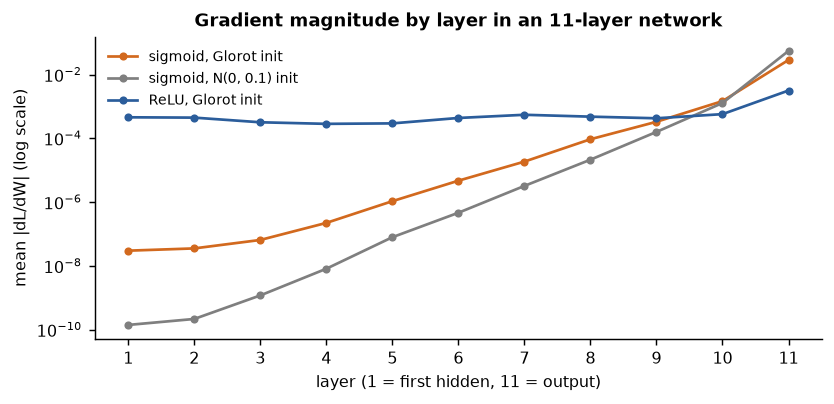

In [23]:
# Gradientes que se desvanecen: media de |dL/dW| por capa en la inicialización, para una red 30-[32 x 10]-1 en tres configuraciones.
configs = {"sigmoid, Glorot init": ("sigmoid", "glorot"), "sigmoid, N(0, 0.1) init": ("sigmoid", 0.1), "ReLU, Glorot init": ("relu", "glorot")}
sizes_deep = [30] + [32] * 10 + [1]; rows = {}
for name, (act, init) in configs.items():
    deep = MLP(sizes_deep, activation=act, init=init, seed=0)
    gW, _ = deep.backward(Z_tr[:64], y_tr[:64])
    rows[name] = np.array([np.abs(g).mean() for g in gW])
grad_table = pd.DataFrame(rows, index=[f"layer {l}" for l in range(1, 12)])
print("ratio of first-layer to last-layer gradient magnitude:")
for name in configs: print(f"  {name:25s}: {rows[name][0] / rows[name][-1]:.1e}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for (name, g), col in zip(rows.items(), (ORANGE, GREY, BLUE)):
    ax.plot(range(1, 12), g, "o-", ms=3.5, color=col, label=name)
ax.set_yscale("log"); ax.set_xlabel("layer (1 = first hidden, 11 = output)"); ax.set_ylabel("mean |dL/dW| (log scale)")
ax.set_xticks(range(1, 12)); ax.legend(frameon=False, fontsize=8); ax.set_title("Gradient magnitude by layer in an 11-layer network"); fig.tight_layout()

<p class="caption"><b>Figura 14.</b> Gradiente absoluto medio de los pesos de cada capa, en la inicialización, en una red con diez capas ocultas de 32 unidades. Con unidades sigmoides e inicialización de Glorot (naranja), el gradiente se reduce aproximadamente en un factor constante por capa y, en la primera capa, es seis o más órdenes de magnitud menor que en la salida; con pesos extraídos de $\mathcal{N}(0, 0.1)$ (gris) la reducción es todavía más rápida. Con unidades ReLU (azul), el gradiente se mantiene dentro de un orden de magnitud a lo largo de las once capas. Las primeras capas de la red sigmoide en la práctica no se entrenarían; las de la red ReLU sí. Las razones impresas sobre la figura hacen cuantitativa la comparación.</p>

<div class="box warn"><h4>Error frecuente</h4><p>"Más capas siempre es mejor". Una red más profunda tiene más capacidad, pero es más difícil de optimizar (gradientes que se desvanecen o que explotan), necesita más datos y, en problemas tabulares de unos pocos cientos de casos, rara vez mejora a una sola capa oculta. La profundidad rinde cuando la entrada tiene estructura composicional —píxeles que forman bordes, bordes que forman partes, partes que forman objetos—, que es el tema de la Unidad 8. Para las características de cáncer de mama, una capa oculta es la opción por defecto adecuada, y la Sección 10 muestra que incluso esa apenas es necesaria.</p></div>

### 9.7 Hiperparámetros y selección de modelos con scikit-learn

Las decisiones anteriores —arquitectura, activación, tasa de aprendizaje, tamaño de lote, épocas o paciencia de la detención temprana, inicialización, intensidad de L2, tasa de dropout— son <strong>hiperparámetros</strong>: magnitudes fijadas antes del entrenamiento que el propio entrenamiento no puede establecer. Se seleccionan con la metodología del Suplemento S1: validación cruzada sobre los datos de entrenamiento, nunca sobre el conjunto de prueba. De aquí en adelante el notebook usa <code>MLPClassifier</code>, cuyos valores por defecto son un punto de partida razonable (una capa oculta de 100 unidades ReLU, Adam con tasa de aprendizaje 0.001, penalización L2 de $10^{-4}$, hasta 200 épocas). La primera pregunta es el tamaño de la capa oculta, que se examina con una <em>curva de validación</em>: la exactitud en validación cruzada en función de un hiperparámetro.

 hidden units  CV accuracy    sd  training accuracy  parameters
            1        0.976 0.008              0.991          33
            2        0.974 0.011              0.985          65
            4        0.976 0.016              0.989         129
            8        0.978 0.007              0.993         257
           16        0.982 0.015              0.993         513
           32        0.982 0.005              0.996        1025
           64        0.982 0.011              0.996        2049
          128        0.985 0.009              1.000        4097


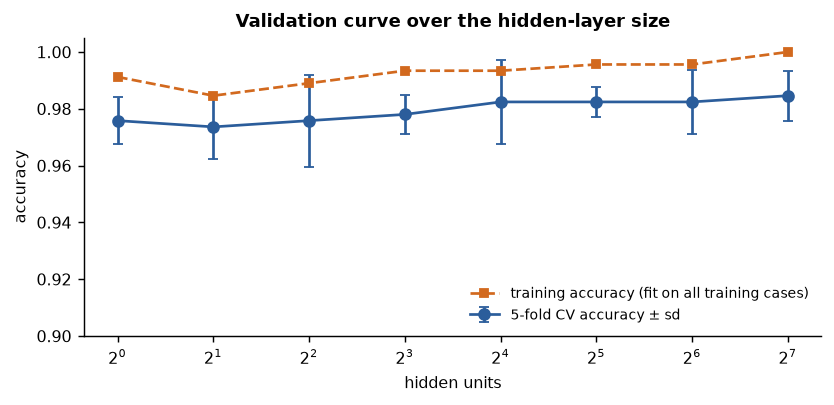

In [24]:
# Curva de validación: exactitud en validación cruzada de 5 pliegues de un MLP de una capa oculta en función del número de unidades ocultas.
hidden_sizes = [1, 2, 4, 8, 16, 32, 64, 128]; means, sds, train_means = [], [], []
for h in hidden_sizes:
    pipe = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(h,), max_iter=500, random_state=0))
    scores = cross_val_score(pipe, X_tr, y_tr, cv=cv)
    means.append(scores.mean()); sds.append(scores.std())
    train_means.append(pipe.fit(X_tr, y_tr).score(X_tr, y_tr))
curve = pd.DataFrame({"hidden units": hidden_sizes, "CV accuracy": np.round(means, 3), "sd": np.round(sds, 3),
                      "training accuracy": np.round(train_means, 3), "parameters": [n_parameters([30, h, 1]) for h in hidden_sizes]})
print(curve.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.errorbar(hidden_sizes, means, yerr=sds, fmt="o-", color=BLUE, capsize=3, label="5-fold CV accuracy ± sd")
ax.plot(hidden_sizes, train_means, "s--", color=ORANGE, ms=4, label="training accuracy (fit on all training cases)")
ax.set_xscale("log", base=2); ax.set_xlabel("hidden units"); ax.set_ylabel("accuracy"); ax.set_ylim(0.9, 1.005)
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_title("Validation curve over the hidden-layer size"); fig.tight_layout()

<p class="caption"><b>Figura 15.</b> Exactitud en validación cruzada (azul, con una desviación estándar entre pliegues) y exactitud de entrenamiento (naranja) de la red 30-$h$-1 para $h$ de 1 a 128. Una sola unidad oculta —una regresión logística sobre una característica aprendida— ya obtiene alrededor de 0.97, y la curva es esencialmente plana a partir de 4 unidades: dentro de la desviación estándar entre pliegues, de alrededor de 0.01, ningún tamaño es mejor que otro. La exactitud de entrenamiento sube hasta 1.0 con el ancho, y la brecha respecto de la exactitud en validación cruzada es el sobreajuste que la detención temprana y la penalización L2 contienen. Con estos datos, el tamaño de la capa oculta no es un hiperparámetro sensible.</p>

### 9.8 Clasificación multiclase: los dígitos manuscritos

Con $K > 2$ clases, la capa de salida tiene $K$ unidades softmax y la pérdida es la entropía cruzada categórica (Sección 8.2); <code>MLPClassifier</code> cambia a esta configuración automáticamente cuando ve más de dos etiquetas. Los datos de dígitos<sup class="c"><a href="#r31">[31]</a></sup> ofrecen un problema de diez clases con una entrada de 64 dimensiones: imágenes pequeñas, el escenario de la Unidad 8 en miniatura.

64-64-10 network: 4,810 parameters | CV accuracy 0.971 ± 0.006 | test accuracy 0.974 (14 errors in 540 test images)
output layer: softmax | classes: [0 1 2 3 4 5 6 7 8 9]


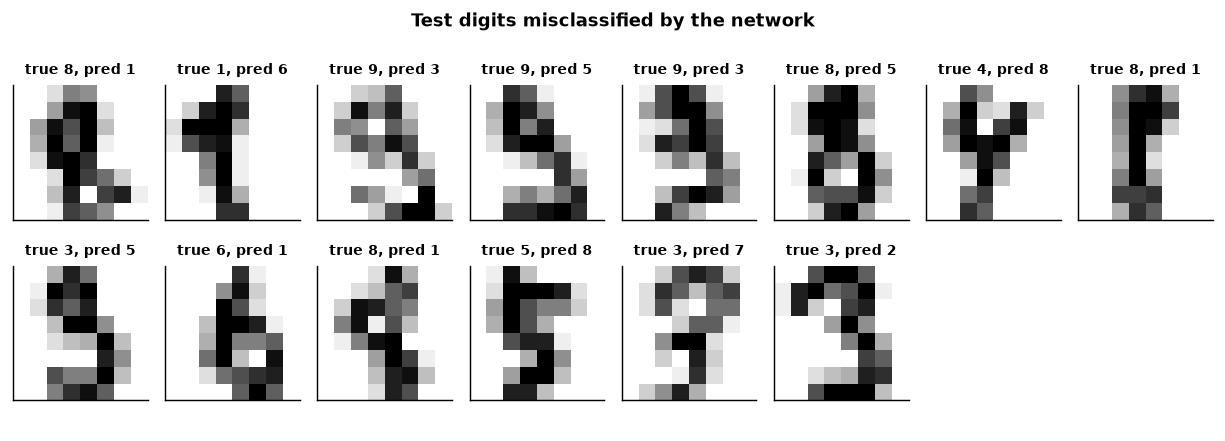

In [25]:
# Una red 64-64-10 con los dígitos manuscritos: exactitud en validación cruzada y luego una mirada a los errores en prueba.
pipe_d = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), max_iter=300, random_state=0))
cv_d = cross_val_score(pipe_d, Xd_tr, yd_tr, cv=StratifiedKFold(5, shuffle=True, random_state=0))
pipe_d.fit(Xd_tr, yd_tr); pred_d = pipe_d.predict(Xd_te); wrong = np.flatnonzero(pred_d != yd_te)
print(f"64-64-10 network: {n_parameters([64, 64, 10]):,} parameters | CV accuracy {cv_d.mean():.3f} ± {cv_d.std():.3f} | "
      f"test accuracy {np.mean(pred_d == yd_te):.3f} ({len(wrong)} errors in {len(yd_te)} test images)")
print("output layer:", pipe_d[-1].out_activation_, "| classes:", pipe_d[-1].classes_)

fig, axes = plt.subplots(2, 8, figsize=(9.5, 3.4))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(Xd_te[i].reshape(8, 8), cmap="gray_r"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"true {yd_te[i]}, pred {pred_d[i]}", fontsize=8)
for ax in axes.ravel()[len(wrong[:16]):]: ax.axis("off")
fig.suptitle("Test digits misclassified by the network", fontsize=10, fontweight="bold"); fig.tight_layout()

<p class="caption"><b>Figura 16.</b> Las imágenes de prueba que la red 64-64-10 clasificó mal (14 de 540), con las etiquetas verdadera y predicha. La mayoría son ambiguas incluso para un lector humano a 8 × 8 píxeles: un 9 con el bucle abierto leído como 4, un 3 y un 5 confundidos por la curva inferior que comparten. La exactitud de la red, de alrededor de 0.97 en imágenes reservadas, está en línea con los resultados de k-NN y SVM de la Unidad 3 con estos datos; con píxeles en bruto como entrada, ningún método de las unidades anteriores tiene ventaja, y son las redes convolucionales de la Unidad 8 las que reducen aún más el error.</p>

### 9.9 Regresión: MLPRegressor con los datos de diabetes

La misma red con una unidad de salida lineal y la pérdida de error cuadrático es un modelo de regresión. Los datos de diabetes<sup class="c"><a href="#r30">[30]</a></sup> —442 pacientes, diez variables basales y una medida cuantitativa de la progresión de la enfermedad un año después— son el ejemplo de regresión de la Unidad 2, donde la regresión lineal explicaba alrededor de la mitad de la varianza. La pregunta es si un modelo no lineal lo hace mejor.

In [26]:
# MLPRegressor frente a regresión lineal con los datos de diabetes: R^2 en validación cruzada de 5 pliegues.
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge
diab = datasets.load_diabetes()
cv_r = KFold(n_splits=5, shuffle=True, random_state=0); rows = []
models = {"linear regression (Unit 2)": LinearRegression(),
          "ridge regression, alpha = 0.1": Ridge(alpha=0.1),
          "MLP 10-8-1, alpha = 1": MLPRegressor(hidden_layer_sizes=(8,), alpha=1.0, max_iter=3000, random_state=0),
          "MLP 10-32-1, alpha = 1": MLPRegressor(hidden_layer_sizes=(32,), alpha=1.0, max_iter=3000, random_state=0),
          "MLP 10-32-1, alpha = 1e-4 (default)": MLPRegressor(hidden_layer_sizes=(32,), max_iter=3000, random_state=0)}
for name, model in models.items():
    r2 = cross_val_score(make_pipeline(StandardScaler(), model), diab.data, diab.target, cv=cv_r, scoring="r2")
    rows.append((name, r2.mean(), r2.std()))
print(pd.DataFrame(rows, columns=["model", "CV R^2", "sd"]).round(3).to_string(index=False))

                              model  CV R^2    sd
         linear regression (Unit 2)   0.489 0.090
      ridge regression, alpha = 0.1   0.489 0.090
              MLP 10-8-1, alpha = 1   0.398 0.138
             MLP 10-32-1, alpha = 1   0.494 0.119
MLP 10-32-1, alpha = 1e-4 (default)   0.495 0.118


Ninguna red supera a la regresión lineal con estos datos: las dos redes de 32 unidades empatan con ella ($R^2$ en validación cruzada de alrededor de 0.49 en los tres casos), con una mayor variabilidad entre pliegues, y la red pequeña de 8 unidades es peor. Esto no es un fracaso del método, sino el contenido de información de 442 pacientes y diez variables, que una recta ya extrae. Una red se justifica cuando la relación es no lineal <em>y</em> los datos son lo bastante numerosos como para revelarla; aquí no se cumple ninguna de las dos condiciones, y el trabajo del ingeniero es informarlo en lugar de ajustar la red hasta que alguna configuración gane en el conjunto de prueba.

## 10. Ejemplo resuelto: un MLP para el diagnóstico de cáncer de mama, de principio a fin

La subunidad 6.8 pide un ejemplo resuelto completo. Esta sección construye, selecciona, evalúa e interpreta una red neuronal para el problema diagnóstico recurrente —maligno frente a benigno a partir de las 30 características nucleares<sup class="c"><a href="#r13">[13]</a></sup>— siguiendo en cada paso el protocolo del Suplemento S1, y termina comparándola de forma justa con los métodos de las Unidades 3–4. Las decisiones de diseño, tomadas antes de mirar ningún resultado:

1. **División de los datos.** La división estratificada 80/20 de la Sección 8.6 (455 casos de entrenamiento y 114 de prueba). Los casos de prueba se tocan una sola vez, al final.
2. **Preprocesamiento.** Estandarización dentro de un pipeline, ajustada solo con los pliegues de entrenamiento.
3. **Arquitectura y pérdida.** Una o dos capas ocultas ReLU, una salida sigmoide, entropía cruzada binaria: el modelo de la Sección 8.
4. **Optimizador y detención.** Adam; si usar o no la detención temprana de scikit-learn (<code>early_stopping=True</code>, que reserva el 10 % de los datos de entrenamiento) se trata como un hiperparámetro, porque la Sección 9.2 mostró su valor y el Suplemento S1 advirtió que un conjunto de validación de 45 casos es un instrumento ruidoso.
5. **Selección del modelo.** Una grilla de 3 × 3 × 2 sobre el tamaño de la capa oculta, la penalización L2 y la detención temprana, puntuada con el ROC-AUC en validación cruzada de 5 pliegues sobre el conjunto de entrenamiento; se usa el AUC en lugar de la exactitud porque el umbral de operación es una decisión clínica que se toma después.
6. **Evaluación.** En el conjunto de prueba: matriz de confusión, sensibilidad (casos malignos detectados), especificidad, AUC y calibración, es decir, si una probabilidad predicha de 0.8 significa "maligno en el 80 % de esos casos".
7. **Interpretación.** Importancia por permutación: en qué características se apoya la red.
8. **Comparación.** El mismo protocolo de validación cruzada aplicado a regresión logística, Bayes ingenuo, SVM, k-NN, un árbol de decisión y un bosque aleatorio.

In [27]:
# Paso 5 - selección del modelo por AUC en validación cruzada de 5 pliegues sobre tamaños ocultos, penalizaciones L2 y detención temprana sí/no.
from sklearn.model_selection import GridSearchCV
pipe = make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=0))
param_grid = {"mlpclassifier__hidden_layer_sizes": [(8,), (32,), (32, 16)], "mlpclassifier__alpha": [1e-4, 1e-2, 1.0],
              "mlpclassifier__early_stopping": [False, True]}
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="roc_auc").fit(X_tr, y_tr)
res = pd.DataFrame(search.cv_results_)
res["hidden"] = res["param_mlpclassifier__hidden_layer_sizes"].astype(str); res["alpha"] = res["param_mlpclassifier__alpha"].astype(float)
res["early stopping"] = res["param_mlpclassifier__early_stopping"].astype(bool)
print("mean CV AUC (rows: hidden layers; columns: early stopping, alpha)")
print(res.pivot(index="hidden", columns=["early stopping", "alpha"], values="mean_test_score").round(4).to_string())
print(f"\nbest configuration: {search.best_params_}  ->  CV AUC {search.best_score_:.4f} "
      f"(sd across folds {res.loc[search.best_index_, 'std_test_score']:.4f})")
mlp_final = search.best_estimator_
print(f"epochs actually run by the selected network: {mlp_final[-1].n_iter_} (max_iter = 1000; Adam stopped on its tolerance)")

mean CV AUC (rows: hidden layers; columns: early stopping, alpha)
early stopping   False   True    False   True    False   True 
alpha           0.0001  0.0001  0.0100  0.0100  1.0000  1.0000
hidden                                                        
(32, 16)        0.9897  0.9839  0.9897  0.9839  0.9895  0.9843
(32,)           0.9898  0.9610  0.9898  0.9610  0.9905  0.9610
(8,)            0.9953  0.9454  0.9953  0.9454  0.9956  0.9454

best configuration: {'mlpclassifier__alpha': 1.0, 'mlpclassifier__early_stopping': False, 'mlpclassifier__hidden_layer_sizes': (8,)}  ->  CV AUC 0.9956 (sd across folds 0.0054)
epochs actually run by the selected network: 343 (max_iter = 1000; Adam stopped on its tolerance)


La tabla responde dos preguntas a la vez. La detención temprana, tal como está implementada aquí, <em>perjudica</em>: todas las configuraciones con <code>early_stopping=True</code> obtienen puntajes más bajos, porque scikit-learn monitorea la exactitud en un 10 % reservado —45 pacientes, es decir, saltos de 2.2 puntos porcentuales— y se detiene tras diez épocas sin mejora, mucho antes de que la red haya terminado de aprender. El remedio de la Sección 9.2 es correcto en principio y necesita un conjunto de validación lo bastante grande como para medir la mejora. Sin él, la penalización L2 y la propia tolerancia de convergencia de Adam se encargan de regularizar, y las nueve configuraciones alcanzan un AUC en validación cruzada superior a 0.99, con diferencias menores que la desviación estándar entre pliegues: de nuevo el paisaje plano de la Figura 15. <code>GridSearchCV</code> elige la mejor media, la reajusta con los 455 casos de entrenamiento, y ese único modelo pasa al conjunto de prueba.

test set: TP 40, FN 2, TN 67, FP 5  |  accuracy 0.939, sensitivity 0.952, specificity 0.931, AUC 0.9911
threshold for sensitivity >= 0.95: 0.694 -> sensitivity 0.952, specificity 0.986


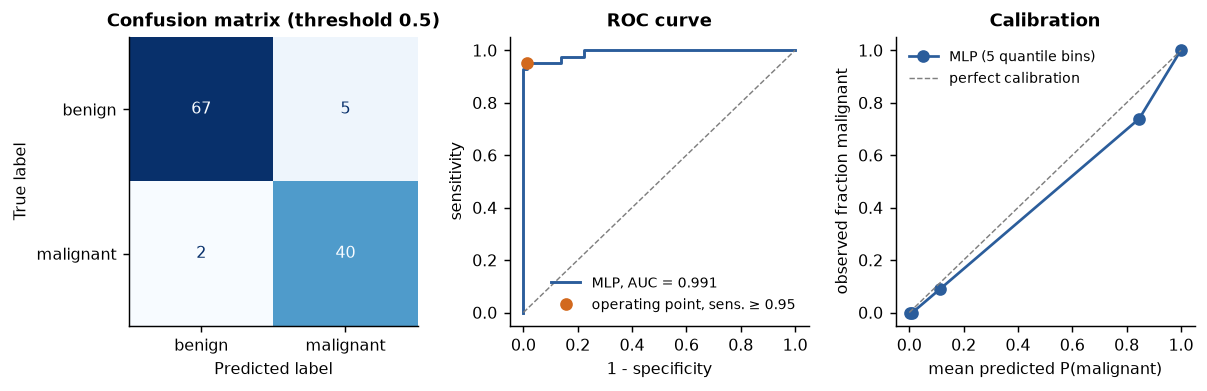

In [28]:
# Paso 6 - evaluación en los 114 casos de prueba: matriz de confusión, sensibilidad, especificidad, AUC, calibración.
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
p_te = mlp_final.predict_proba(X_te)[:, 1]; pred_te = (p_te >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
sens, spec, auc = tp / (tp + fn), tn / (tn + fp), roc_auc_score(y_te, p_te)
print(f"test set: TP {tp}, FN {fn}, TN {tn}, FP {fp}  |  accuracy {(tp + tn) / len(y_te):.3f}, "
      f"sensitivity {sens:.3f}, specificity {spec:.3f}, AUC {auc:.4f}")
fpr, tpr, thr = roc_curve(y_te, p_te)
i95 = np.argmax(tpr >= 0.95); print(f"threshold for sensitivity >= 0.95: {thr[i95]:.3f} -> sensitivity {tpr[i95]:.3f}, specificity {1 - fpr[i95]:.3f}")
frac_pos, mean_pred = calibration_curve(y_te, p_te, n_bins=5, strategy="quantile")

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.1))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["benign", "malignant"]).plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Confusion matrix (threshold 0.5)")
axes[1].plot(fpr, tpr, color=BLUE, lw=1.6, label=f"MLP, AUC = {auc:.3f}"); axes[1].plot([0, 1], [0, 1], color=GREY, ls="--", lw=0.8)
axes[1].plot(fpr[i95], tpr[i95], "o", color=ORANGE, label="operating point, sens. ≥ 0.95")
axes[1].set_xlabel("1 - specificity"); axes[1].set_ylabel("sensitivity"); axes[1].set_title("ROC curve"); axes[1].legend(frameon=False, fontsize=8, loc="lower right")
axes[2].plot(mean_pred, frac_pos, "o-", color=BLUE, label="MLP (5 quantile bins)"); axes[2].plot([0, 1], [0, 1], color=GREY, ls="--", lw=0.8, label="perfect calibration")
axes[2].set_xlabel("mean predicted P(malignant)"); axes[2].set_ylabel("observed fraction malignant"); axes[2].set_title("Calibration"); axes[2].legend(frameon=False, fontsize=8)
fig.tight_layout()

<p class="caption"><b>Figura 17.</b> Evaluación de la red seleccionada en los 114 casos reservados. Izquierda: la matriz de confusión con el umbral por defecto de 0.5, con unos pocos errores en cada dirección. Centro: la curva ROC, con un AUC superior a 0.99; el punto naranja es el umbral más bajo con el que se detecta al menos el 95 % de los casos malignos, el punto de operación que elegiría una aplicación de tamizaje; aquí ese umbral es mayor que 0.5 y da una especificidad <em>mayor</em> que la del umbral por defecto, un recordatorio de que 0.5 no es un umbral privilegiado. Derecha: la curva de calibración, la fracción observada de casos malignos frente a la probabilidad predicha media en cinco intervalos de cuantiles; los puntos cercanos a la diagonal significan que las probabilidades de la red pueden leerse como probabilidades. Las redes neuronales entrenadas con entropía cruzada están, en general, razonablemente bien calibradas en este contexto, a diferencia del Bayes ingenuo (Unidad 3), cuyas probabilidades a posteriori se ven empujadas hacia los extremos;<sup class="c"><a href="#r32">[32]</a></sup> sin embargo, los pocos casos de prueba por intervalo hacen que la curva sea ruidosa, y una afirmación sobre la calibración necesitaría más datos.</p>

Leyendo los números como lo haría un ingeniero: el conjunto de prueba contiene 42 casos malignos, de modo que cada falso negativo equivale a más de dos puntos porcentuales de sensibilidad, y el intervalo de confianza de cualquiera de estas estimaciones es amplio (Suplemento S1). El resumen honesto es "AUC de alrededor de 0.99, sensibilidad de alrededor de 0.95 y especificidad de alrededor de 0.93 con el umbral por defecto, en 114 casos de un solo hospital", seguido de la pregunta de la Unidad 1: ¿se mantendría con aspirados de otro laboratorio?

               feature  mean AUC drop     sd
         worst texture         0.0068 0.0026
          mean texture         0.0046 0.0019
mean fractal dimension         0.0029 0.0015
          worst radius         0.0025 0.0025
        mean perimeter         0.0024 0.0025
        worst symmetry         0.0024 0.0029
     compactness error         0.0019 0.0017
       worst perimeter         0.0016 0.0022
             mean area         0.0015 0.0018
          radius error         0.0012 0.0023

features whose permutation changes the AUC by less than 0.001: 16 of 30


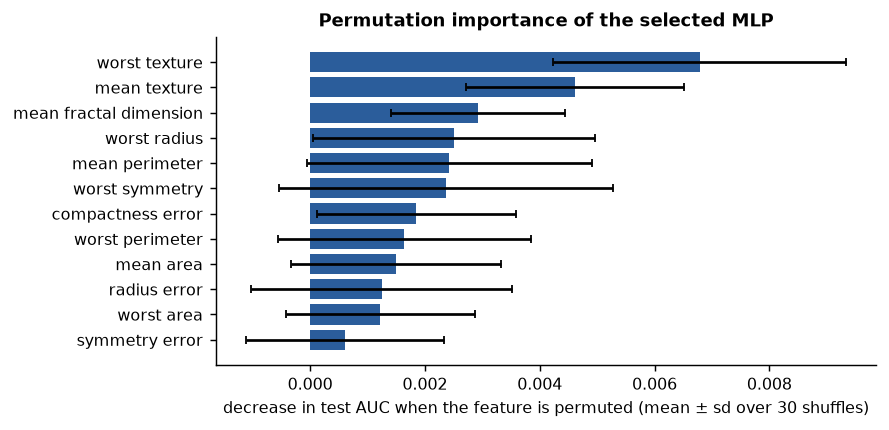

In [29]:
# Paso 7 - interpretación por importancia por permutación: ¿cuánto cae el AUC de prueba cuando se baraja una característica?
from sklearn.inspection import permutation_importance
perm = permutation_importance(mlp_final, X_te, y_te, scoring="roc_auc", n_repeats=30, random_state=0)
imp = pd.DataFrame({"feature": cancer.feature_names, "mean AUC drop": perm.importances_mean, "sd": perm.importances_std}
                   ).sort_values("mean AUC drop", ascending=False)
print(imp.head(10).round(4).to_string(index=False))
print(f"\nfeatures whose permutation changes the AUC by less than 0.001: {(imp['mean AUC drop'].abs() < 0.001).sum()} of 30")

fig, ax = plt.subplots(figsize=(7, 3.4)); top = imp.head(12).iloc[::-1]
ax.barh(top["feature"], top["mean AUC drop"], xerr=top["sd"], color=BLUE, capsize=2)
ax.set_xlabel("decrease in test AUC when the feature is permuted (mean ± sd over 30 shuffles)")
ax.set_title("Permutation importance of the selected MLP"); fig.tight_layout()

<p class="caption"><b>Figura 18.</b> Las doce características cuya permutación aleatoria más reduce el AUC de prueba de la red. La textura (la variación de los niveles de gris dentro del núcleo, "mean" y "worst") encabeza la lista, seguida de las medidas de tamaño ("worst radius", "mean perimeter", "mean area") y de la dimensión fractal, lo cual es coherente con la patología, en la que los núcleos malignos son más grandes y tienen una cromatina más heterogénea. Alrededor de la mitad de las características tienen una importancia indistinguible de cero: la red no las necesita, o su información está duplicada por características correlacionadas (el radio, el perímetro y el área de un mismo núcleo son casi colineales), en cuyo caso permutar una deja que las demás transporten la señal. La importancia por permutación mide dependencia, no causalidad, y reparte la señal entre las características correlacionadas de forma arbitraria.</p>

El paso final es la comparación que todo artículo aplicado debería contener y que muchos omiten: el mismo protocolo aplicado a los métodos más simples de las Unidades 2–4.

In [30]:
# Paso 8 - la comparación justa: AUC y exactitud en validación cruzada de 5 pliegues sobre el conjunto de entrenamiento, luego AUC de prueba, para siete clasificadores.
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
competitors = {"logistic regression (U2)": LogisticRegression(max_iter=2000),
               "Gaussian naive Bayes (U3)": GaussianNB(),
               "SVM, RBF kernel (U3)": SVC(random_state=0),                      # AUC a partir de decision_function
               "k-NN, k = 7 (U3)": KNeighborsClassifier(n_neighbors=7),
               "decision tree, depth 4 (U4)": DecisionTreeClassifier(max_depth=4, random_state=0),
               "random forest, 200 trees (U4)": RandomForestClassifier(n_estimators=200, random_state=0),
               "MLP, selected above (U6)": mlp_final[-1]}
rows = []
for name, clf in competitors.items():
    pipe_c = make_pipeline(StandardScaler(), clf)
    scores = cross_validate(pipe_c, X_tr, y_tr, cv=cv, scoring=["roc_auc", "accuracy"])
    pipe_c.fit(X_tr, y_tr)
    score_te = pipe_c.decision_function(X_te) if hasattr(pipe_c, "decision_function") else pipe_c.predict_proba(X_te)[:, 1]
    test_auc = roc_auc_score(y_te, score_te)
    rows.append((name, scores["test_roc_auc"].mean(), scores["test_roc_auc"].std(), scores["test_accuracy"].mean(), scores["test_accuracy"].std(), test_auc))
comparison = pd.DataFrame(rows, columns=["classifier", "CV AUC", "sd", "CV accuracy", "sd ", "test AUC"]).round(3)
print(comparison.to_string(index=False))

                   classifier  CV AUC    sd  CV accuracy   sd   test AUC
     logistic regression (U2)   0.992 0.009        0.982 0.015     0.993
    Gaussian naive Bayes (U3)   0.988 0.004        0.932 0.022     0.979
         SVM, RBF kernel (U3)   0.995 0.006        0.976 0.008     0.994
             k-NN, k = 7 (U3)   0.989 0.010        0.965 0.019     0.978
  decision tree, depth 4 (U4)   0.926 0.027        0.932 0.018     0.929
random forest, 200 trees (U4)   0.993 0.004        0.954 0.020     0.978
     MLP, selected above (U6)   0.996 0.005        0.978 0.007     0.991


La tabla es el resultado honesto del ejemplo resuelto. La regresión logística, la SVM, el bosque aleatorio y la red alcanzan todos un AUC en validación cruzada de alrededor de 0.99, y las diferencias entre ellos están dentro de una desviación estándar entre pliegues; solo el árbol de decisión individual queda claramente atrás en ambas medidas, y el Bayes ingenuo en exactitud (su AUC es competitivo, pero sus probabilidades están mal calibradas, como mostró la Unidad 3). Con 455 casos y 30 características diseñadas, la flexibilidad adicional de la red neuronal no aporta nada que una regresión logística regularizada no tenga ya; y la regresión logística tiene 31 coeficientes interpretables, se entrena en milisegundos y no tiene hiperparámetros que valga la pena ajustar. La red se gana su lugar cuando la entrada es la imagen del aspirado y no treinta números calculados a partir de ella: el tema de la Unidad 8.

<div class="box key"><h4>Lo que enseña el ejemplo resuelto</h4>
<ul>
<li>El protocolo (división → pipeline → selección por validación cruzada → una única evaluación en prueba → interpretación → comparación) es el mismo para todos los modelos del curso; la red agrega hiperparámetros, no pasos.</li>
<li>Reporta el AUC con su variabilidad entre pliegues, el punto de operación pertinente para el uso clínico y la calibración; una exactitud aislada no es una evaluación.</li>
<li>Incluye siempre los modelos de referencia simples. Un resultado que no supera a la regresión logística por más que el ruido es un resultado a favor de la regresión logística.</li>
</ul></div>

<div class="exercise"><h4>Ejercicio 4 (preparación para el Laboratorio 4)</h4><p>Repite el ejemplo resuelto con los datos de dígitos (diez clases): selecciona el tamaño de la capa oculta y <code>alpha</code> según la exactitud en validación cruzada, evalúa en la partición de prueba del 30 % de la Sección 4.3 con una matriz de confusión de 10 × 10 (<code>ConfusionMatrixDisplay.from_estimator</code>) y compara con k-NN y un bosque aleatorio. Luego reduce el conjunto de entrenamiento al 10 % de su tamaño y repite: ¿qué método se degrada menos, y por qué?</p></div>

## 11. Del perceptrón multicapa al aprendizaje profundo

### 11.1 Profundidad

Una red <strong>profunda</strong> es un perceptrón multicapa con muchas capas ocultas; no hay ninguna otra diferencia de principio. El teorema de aproximación universal dice que una capa oculta basta para <em>representar</em> cualquier función, pero puede necesitar un número exponencial de unidades para hacerlo, mientras que una red profunda puede representar la misma función con muchos menos parámetros <em>componiendo</em> funciones simples: las unidades de cada capa reutilizan las características de la capa inferior, como un programa reutiliza subrutinas. La revisión de LeCun, Bengio y Hinton enuncia la tesis del campo: las redes profundas aprenden una jerarquía de representaciones, cada nivel más abstracto que el anterior, y esta jerarquía es lo que las características diseñadas a mano del reconocimiento de patrones clásico nunca pudieron proporcionar.<sup class="c"><a href="#r6">[6]</a></sup> Lo que hizo práctica la profundidad tras décadas de fracasos fue la conjunción de los remedios de la Sección 9 —ReLU, inicialización escalada, dropout, Adam— con dos factores externos: conjuntos de datos etiquetados con millones de ejemplos, y las unidades de procesamiento gráfico (GPU), cuyos miles de núcleos simples ejecutan en paralelo los productos de matrices de la propagación hacia adelante y hacia atrás (Sección 8.1), cien veces más rápido que un procesador de propósito general. La red de ImageNet de 2012 se entrenó en dos GPU durante alrededor de una semana.<sup class="c"><a href="#r5">[5]</a></sup>

### 11.2 Convolución: un adelanto de la Unidad 8

Una primera capa totalmente conectada sobre una imagen de 256 × 256 tiene 65,536 entradas por unidad, y una capa oculta de 1,000 unidades tiene 65 millones de pesos: demasiados para aprenderlos con cualquier conjunto de datos médicos, y un derroche, porque la característica que detecta un margen tumoral en la esquina superior izquierda es la misma que lo detecta en la inferior derecha. Una <strong>capa convolucional</strong> resuelve ambos problemas: cada unidad mira solo una pequeña ventana de la imagen (digamos, 3 × 3 píxeles), y todas las unidades de la capa comparten los mismos pesos, deslizando la ventana por la imagen. La capa tiene entonces 9 pesos en lugar de 65 millones, detecta su característica dondequiera que aparezca, y las pilas de tales capas aprenden la jerarquía bordes → texturas → partes → objetos. LeCun introdujo la arquitectura para el reconocimiento de dígitos manuscritos a fines de la década de 1980 y le dio su forma definitiva, LeNet-5, en 1998;<sup class="c"><a href="#r33">[33]</a></sup> todos los sistemas de imágenes médicas de la Sección 5 son sus descendientes. La celda siguiente aplica dos filtros de 3 × 3 diseñados a mano a un dígito para mostrar lo que calcula una unidad convolucional; en la Unidad 8 los filtros se aprenden por retropropagación, exactamente como se aprendieron los pesos de esta unidad.

a convolutional unit with a 3 x 3 window has 10 parameters, whatever the image size; a fully connected unit on this 8 x 8 image has 65, and on a 256 x 256 image 65,537


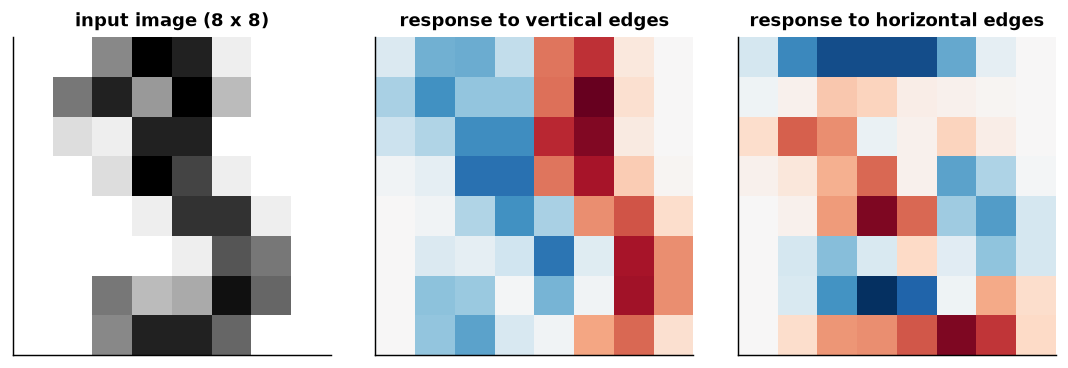

In [31]:
# Lo que calcula una unidad convolucional: un filtro de 3 x 3 deslizado sobre una imagen (aquí, dos detectores de bordes diseñados a mano).
from scipy.signal import convolve2d
img = digits.images[np.flatnonzero(digits.target == 3)[0]]                      # una imagen de 8 x 8 de un '3'
filters = {"vertical edges":   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),   # filtro de Sobel, dirección x
           "horizontal edges": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])}   # filtro de Sobel, dirección y
print("a convolutional unit with a 3 x 3 window has", 3 * 3 + 1, "parameters, whatever the image size;",
      f"a fully connected unit on this 8 x 8 image has {8 * 8 + 1}, and on a 256 x 256 image {256 * 256 + 1:,}")

fig, axes = plt.subplots(1, 3, figsize=(8.5, 2.8))
axes[0].imshow(img, cmap="gray_r"); axes[0].set_title("input image (8 x 8)")
for ax, (name, k) in zip(axes[1:], filters.items()):
    response = convolve2d(img, k, mode="same")                                 # la salida de la unidad en cada posición
    ax.imshow(response, cmap="RdBu_r", vmin=-abs(response).max(), vmax=abs(response).max()); ax.set_title(f"response to {name}")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

<p class="caption"><b>Figura 19.</b> Un "3" manuscrito y sus respuestas a dos filtros de 3 × 3 (operadores de Sobel), cada uno aplicado en todas las posiciones de la imagen. El mapa de respuesta de la izquierda se ilumina donde la intensidad cambia de izquierda a derecha —los trazos verticales— y el de la derecha donde cambia de arriba hacia abajo —los trazos horizontales—. Cada mapa es la salida de una unidad convolucional, con nueve pesos, evaluada en 64 posiciones. Una red convolucional aprende a partir de los datos docenas de filtros como estos en su primera capa y luego combina sus respuestas en la siguiente.</p>

### 11.3 Secuencias y atención

Otras dos arquitecturas completan el mapa. Las <strong>redes recurrentes</strong> (Sección 3.1) procesan una secuencia elemento por elemento, arrastrando hacia adelante un estado oculto, y fueron el modelo estándar para señales y lenguaje durante la década de 2010; la unidad de <em>memoria de corto y largo plazo</em> (long short-term memory) de Hochreiter y Schmidhuber resolvió su problema del gradiente que se desvanece a través del tiempo mediante celdas de memoria con compuertas,<sup class="c"><a href="#r34">[34]</a></sup> y las redes recurrentes leen electrocardiogramas, electroencefalogramas y series de tiempo clínicas. El <strong>Transformer</strong> de 2017 reemplazó la recurrencia por la <em>atención</em>, un mecanismo en el que cada elemento de la secuencia calcula una suma ponderada sobre todos los demás, con pesos que son a su vez funciones aprendidas del contenido; como el cálculo sobre las posiciones es paralelo y no secuencial, los Transformers se entrenan de forma eficiente con secuencias muy largas y corpus muy grandes,<sup class="c"><a href="#r35">[35]</a></sup> y son la base de los grandes modelos de lenguaje y de los predictores de estructura de proteínas de la Unidad 1. Ambas son, al nivel de esta unidad, disposiciones de sumas ponderadas y funciones de activación entrenadas por retropropagación; lo que cambia es el patrón de conexiones y de pesos compartidos.

<div class="box bridge"><h4>Puente con la Unidad 8</h4><p>La Unidad 8 entrena una red convolucional para la clasificación de patrones en imágenes médicas. Todo lo que necesita está en esta unidad: la capa como producto de matrices, la salida softmax y la pérdida de entropía cruzada, la retropropagación, la tasa de aprendizaje y la detención temprana, la estandarización de la entrada y el protocolo de evaluación de la Sección 10. La capa convolucional de la Figura 19 es el único componente nuevo.</p></div>

## 12. Resumen

Ahora deberías ser capaz de explicar, sin apuntes:

- El cerebro en cifras —unos 86 mil millones de neuronas, $10^{14}$–$10^{15}$ sinapsis, componentes que operan en milisegundos, paralelismo masivo— y las cinco propiedades que toman de él las redes artificiales (unidades simples, conexiones ponderadas, representación distribuida, degradación suave, aprendizaje mediante el cambio de pesos), junto con la afirmación honesta de que una red artificial está inspirada en el cerebro, pero no es un modelo de él.
- Los componentes de una unidad —entradas, pesos, sesgo, suma ponderada, función de activación, salida— y de una red —capas de entrada, ocultas y de salida, arquitectura, prealimentada frente a recurrente— y cómo contar los parámetros de una arquitectura.
- Por qué una neurona sigmoide individual es una regresión logística, y por qué una red con capas ocultas es una regresión logística sobre características aprendidas.
- El teorema de aproximación universal (lo que promete y lo que no) y las cuatro limitaciones: necesidad de muchos datos, opacidad, muchos hiperparámetros, entrenamiento no convexo.
- Las funciones de activación escalón, sigmoide, tanh, ReLU y softmax, sus derivadas, y por qué la derivada importa (saturación, unidades muertas, gradientes que se desvanecen).
- Cómo una unidad calcula AND y OR, la demostración geométrica y algebraica de que ninguna calcula XOR, y por qué eso motiva las capas ocultas.
- La regla de aprendizaje de Rosenblatt, su derivación como un paso a lo largo de $y\mathbf{x}$, el teorema de convergencia y su cota $(R/\gamma)^2$, el seguimiento a mano sobre AND, el comportamiento con datos no separables y la regla delta del Adaline como descenso de gradiente sobre una pérdida suave.
- La propagación hacia adelante como productos de matrices; las pérdidas de entropía cruzada y de error cuadrático, y por qué se prefiere la entropía cruzada para clasificación; la retropropagación como la regla de la cadena organizada en torno a $\delta^{(l)}$, con las cuatro ecuaciones matriciales; el seguimiento a mano de un paso en la red 2-2-1; la comprobación del gradiente.
- Las decisiones prácticas —tasa de aprendizaje, épocas y detención temprana, inicialización, estandarización, L2 y dropout— y los experimentos que muestran el avance demasiado lento, la divergencia, el sobreajuste y los gradientes que se desvanecen.
- El protocolo del ejemplo resuelto y su resultado: con datos tabulares de unos pocos cientos de casos, una red iguala, pero no supera, a la regresión logística y a los bosques aleatorios; su ventaja está en las entradas en bruto —imágenes, señales, secuencias—, que retoma la Unidad 8.
- Qué agregan la profundidad, la convolución, la recurrencia y la atención al perceptrón multicapa, y por qué importan las GPU.

## 13. Autoevaluación

<details><summary>1. Un colega dice: "nuestra red tiene tres capas: entrada, oculta y salida". ¿Cuántas capas de unidades que calculan tiene, y por qué importa el conteo al leer un artículo?</summary>Dos: la capa de entrada contiene las características y no calcula nada. Los artículos y el software difieren en si la cuentan o no, así que una arquitectura debería darse como la lista de tamaños de capa (p. ej., 30-16-1), que no es ambigua; el número de parámetros, que acota los datos necesarios, se deduce de esa lista.</details>

<details><summary>2. Cuenta los parámetros de una red 64-100-100-10 e indica qué fracción del conjunto de entrenamiento de dígitos (1,257 imágenes) representa ese número.</summary>$64 \times 100 + 100 + 100 \times 100 + 100 + 100 \times 10 + 10 = 6{,}500 + 10{,}100 + 1{,}010 = 17{,}610$ parámetros, es decir, unos catorce parámetros por imagen de entrenamiento. Una red así puede memorizar el conjunto de entrenamiento; la detención temprana, la penalización L2 y la validación cruzada son lo que la mantiene honesta.</details>

<details><summary>3. A mano: una unidad tiene pesos $w = (2, -1)$, sesgo $b = -0.5$ y activación sigmoide. Calcula su salida para $\mathbf{x} = (1, 1)$ y para $\mathbf{x} = (0, 1)$. ¿En qué lado de la frontera queda cada uno?</summary>$z = 2 - 1 - 0.5 = 0.5 \Rightarrow a = \sigma(0.5) \approx 0.622$ para $(1,1)$; $z = 0 - 1 - 0.5 = -1.5 \Rightarrow a = \sigma(-1.5) \approx 0.182$ para $(0,1)$. El primero está en el lado positivo de la recta $2x_1 - x_2 = 0.5$ (salida mayor que 0.5) y el segundo en el lado negativo.</details>

<details><summary>4. Da pesos y sesgo para una unidad con activación escalón que calcule NOR$(x_1, x_2)$, y explica en una oración por qué ninguna elección calcula XOR.</summary>$w = (-1, -1)$, $b = 0.5$: $z = 0.5$ para $(0,0)$ y negativo en los demás casos. XOR requiere que las dos esquinas diagonales del cuadrado unitario queden a un lado de una recta y las otras dos al otro lado, lo que ninguna recta logra (sumar las desigualdades para $(0,1)$ y $(1,0)$ y restar la de $(0,0)$ contradice la de $(1,1)$).</details>

<details><summary>5. En el seguimiento a mano del perceptrón de la Sección 7.3, la segunda época comienza con $\mathbf{w} = (1,1)$, $b = 0$. Calcula los pesos después de los dos primeros pasos de la época 2 (entradas $(0,0)$ y luego $(0,1)$, $\eta = 1$).</summary>Paso 1: $z = 0 \Rightarrow \hat{y} = +1 \neq -1$; se actualiza $b \leftarrow -1$, $\mathbf{w}$ sin cambios $(1,1)$. Paso 2: $z = 1 - 1 = 0 \Rightarrow \hat{y} = +1 \neq -1$; se actualiza $\mathbf{w} \leftarrow (1,1) - (0,1) = (1,0)$, $b \leftarrow -2$. Esto coincide con las filas 5–6 de la tabla impresa por el código.</details>

<details><summary>6. El teorema de convergencia del perceptrón acota el número de errores por $(R/\gamma)^2$. ¿Qué le ocurre a la cota si cada característica se multiplica por 10, y qué te dice eso sobre los datos, no sobre el algoritmo?</summary>Nada: $R$ y $\gamma$ se multiplican ambos por 10 y la razón no cambia. La cota depende de la <em>geometría</em> del problema —cuán grande es el margen en relación con la dispersión de los datos—, no de sus unidades; un problema cuyas clases casi se tocan ($\gamma/R$ pequeño) necesita muchas actualizaciones, cualquiera que sea la tasa de aprendizaje.</details>

<details><summary>7. ¿Por qué la función escalón no sirve como activación oculta en una red entrenada por retropropagación, y por qué la sigmoide cedió luego su lugar a la ReLU?</summary>Su derivada es cero en todas partes, de modo que $\delta^{(l)} = (\dots) \odot \varphi'(z)$ es cero y ningún peso recibe gradiente. La sigmoide es diferenciable, pero su derivada es como máximo 0.25 y se desvanece cuando la unidad se satura, de modo que los gradientes se reducen geométricamente con la profundidad; la derivada de la ReLU es exactamente 1 para las unidades activas, así que los gradientes las atraviesan sin disminuir (Figura 14).</details>

<details><summary>8. En el seguimiento a mano de la retropropagación, los gradientes de la capa oculta fueron unas diez veces menores que los de la capa de salida. Identifica los dos factores responsables e indica cuál elimina la ReLU.</summary>$\delta^{(1)}_j = \delta^{(2)} W^{(2)}_j\, \sigma'(z^{(1)}_j)$: el error se multiplica por el peso que conecta las unidades (magnitud 0.6 o 0.4) y por la derivada de la sigmoide (como máximo 0.25; aquí 0.249 y 0.206). La ReLU reemplaza el segundo factor por 1 en las unidades activas; el primer factor se controla con la inicialización.</details>

<details><summary>9. Lee el código: en el método <code>backward</code> de la clase <code>MLP</code>, ¿por qué <code>delta</code> se inicializa como <code>(self.A[-1] - y[:, None]) / n</code> sin ninguna derivada de la activación, y qué habría que cambiar si la pérdida fuera el error cuadrático?</summary>Para una salida sigmoide con la entropía cruzada binaria, $\partial L/\partial z^{(L)} = (\hat{y} - y)/n$ exactamente: el factor $\sigma'(z)$ se cancela con la derivada del logaritmo. Con el error cuadrático, la línea pasaría a ser <code>(A[-1] - y) * A[-1] * (1 - A[-1]) / n</code>, como en la celda de XOR, y el entrenamiento se haría más lento cada vez que la salida se saturara.</details>

<details><summary>10. La Figura 13 muestra que la pérdida de validación sube después de unas cincuenta épocas mientras la de entrenamiento sigue bajando. Nombra el fenómeno, el remedio implementado en scikit-learn y otro remedio de la Sección 9.</summary>Sobreajuste. Detención temprana (<code>early_stopping=True</code>, que reserva el 10 % de los datos de entrenamiento y se detiene cuando su puntaje deja de mejorar). Otros remedios: la penalización L2 (<code>alpha</code>), el dropout (no disponible en scikit-learn), una red más pequeña o más datos.</details>

<details><summary>11. En el ejemplo resuelto, la red, la SVM, el bosque aleatorio y la regresión logística alcanzaron todos un AUC en validación cruzada de alrededor de 0.99. Un revisor te pide justificar el uso de la red. ¿Qué respondes?</summary>Que con estos datos la red no se justifica: no supera al modelo de referencia más simple por más que la variabilidad entre pliegues, y es menos interpretable y más costosa de ajustar. La justificación de las redes está en problemas con entradas en bruto y de alta dimensión (imágenes, señales) donde las características deben aprenderse; las características diseñadas de este conjunto de datos ya contienen la información.</details>

<details><summary>12. La Sección 9.4 ajustó el <code>StandardScaler</code> dentro de un <code>Pipeline</code>. ¿Qué error introduciría ajustarlo con el conjunto de datos completo antes de la validación cruzada, y haría que la exactitud reportada fuera mayor o menor que la real?</summary>Fuga de datos: las medias y desviaciones estándar de los pliegues de prueba influirían en la estandarización de los pliegues de entrenamiento, lo que daría al modelo información sobre los datos de prueba. La exactitud reportada tendría un sesgo optimista: sería mayor que la exactitud con casos genuinamente nuevos (Suplemento S1).</details>

## Glosario

<dl class="gloss">
<dt>Función de activación (activation function)</dt><dd>La función no lineal fija $\varphi$ que se aplica a la suma ponderada de una unidad; escalón, sigmoide, tanh y ReLU para unidades ocultas o de salida, softmax para una capa de salida multiclase.</dd>
<dt>Adaline / regla delta (Adaline / delta rule)</dt><dd>La unidad lineal de Widrow y Hoff entrenada por descenso de gradiente sobre el error cuadrático; su actualización $\mathbf{w} \leftarrow \mathbf{w} + \eta (y - z)\mathbf{x}$ es el caso de una sola capa de la retropropagación.</dd>
<dt>Arquitectura (architecture)</dt><dd>La especificación de una red: número y tamaño de las capas, funciones de activación, patrón de conexiones (totalmente conectada, convolucional, recurrente).</dd>
<dt>Retropropagación (backpropagation)</dt><dd>El algoritmo que calcula el gradiente de la pérdida respecto de cada peso aplicando la regla de la cadena capa por capa desde la salida hacia atrás, reutilizando $\delta^{(l)} = \partial L / \partial \mathbf{z}^{(l)}$.</dd>
<dt>Lote, minilote, época (batch, mini-batch, epoch)</dt><dd>El conjunto de casos usado para un paso de gradiente (todos los casos: lote completo; un subconjunto: minilote; un caso: en línea); una pasada por todo el conjunto de entrenamiento es una época.</dd>
<dt>Sesgo (bias)</dt><dd>El término constante $b$ que se suma a la suma ponderada de una unidad; equivale a un peso sobre una entrada constante igual a 1. Desplaza la frontera de decisión alejándola del origen.</dd>
<dt>Capa convolucional (convolutional layer)</dt><dd>Una capa cuyas unidades ven cada una una pequeña ventana de la entrada y comparten los mismos pesos, de modo que una característica se detecta dondequiera que aparezca; el bloque básico de las redes para imágenes (Unidad 8).</dd>
<dt>Entropía cruzada (cross-entropy)</dt><dd>La pérdida de log-verosimilitud negativa para la clasificación probabilística: binaria para una salida sigmoide, categórica para una salida softmax. Con estas salidas, su gradiente respecto de los logits es $\hat{y} - y$.</dd>
<dt>Aprendizaje profundo (deep learning)</dt><dd>Redes neuronales con muchas capas ocultas, entrenadas de extremo a extremo a partir de entradas en bruto; la jerarquía aprendida de representaciones es su rasgo distintivo.</dd>
<dt>Dropout (dropout)</dt><dd>Un método de regularización que lleva a cero cada unidad oculta al azar durante el entrenamiento, lo que obliga a formar representaciones redundantes.</dd>
<dt>Detención temprana (early stopping)</dt><dd>Terminar el entrenamiento cuando la pérdida en un conjunto de validación deja de mejorar y conservar los pesos de la mejor época; el regularizador más común para redes.</dd>
<dt>Prealimentada / recurrente (feed-forward / recurrent)</dt><dd>Una red sin ciclos, cuya salida depende solo de la entrada actual / una red con conexiones de retroalimentación, cuya salida depende de la secuencia de entradas pasadas.</dd>
<dt>Inicialización de Glorot o Xavier (Glorot (Xavier) initialisation)</dt><dd>Pesos iniciales aleatorios con varianza $2/(n_{\text{in}} + n_{\text{out}})$, elegida para que la varianza de la señal y del gradiente se mantenga aproximadamente constante a través de las capas.</dd>
<dt>Comprobación del gradiente (gradient checking)</dt><dd>Verificar una implementación de la retropropagación comparando sus derivadas con diferencias finitas centradas de la pérdida.</dd>
<dt>Aprendizaje hebbiano (Hebbian learning)</dt><dd>La regla de Hebb de 1949: una sinapsis se fortalece cuando las neuronas presináptica y postsináptica están activas a la vez; la primera propuesta de que aprender es ajustar la fuerza de las conexiones.</dd>
<dt>Capa oculta (hidden layer)</dt><dd>Una capa cuyas activaciones no son ni entradas ni salidas; sus unidades calculan las características aprendidas con las que opera la capa de salida.</dd>
<dt>Hiperparámetro (hyperparameter)</dt><dd>Una magnitud fijada antes del entrenamiento (arquitectura, tasa de aprendizaje, intensidad de la penalización, épocas) y elegida por validación cruzada, a diferencia de un parámetro aprendido por descenso de gradiente.</dd>
<dt>Tasa de aprendizaje (learning rate)</dt><dd>El tamaño de paso $\eta$ del descenso de gradiente; si es demasiado pequeña, avanza muy lento; si es demasiado grande, diverge.</dd>
<dt>Linealmente separable (linearly separable)</dt><dd>Una muestra etiquetada para la cual algún hiperplano deja todos los casos de una clase a un lado y todos los de la otra al otro lado; la condición bajo la cual el perceptrón converge.</dd>
<dt>Logit (logit)</dt><dd>La preactivación de una unidad de salida, $z = \mathbf{w}^\top \mathbf{a} + b$, antes de la sigmoide o la softmax; igual al logaritmo de las odds (log-odds) para una salida sigmoide.</dd>
<dt>Neurona de McCulloch–Pitts (McCulloch–Pitts neuron)</dt><dd>La unidad de 1943: entradas binarias, un umbral y una salida binaria; el primer modelo formal de una neurona como dispositivo lógico.</dd>
<dt>Perceptrón multicapa (multilayer perceptron, MLP)</dt><dd>Una red prealimentada totalmente conectada, con una o más capas ocultas y activaciones diferenciables, entrenada por retropropagación.</dd>
<dt>Perceptrón (perceptron)</dt><dd>La unidad de umbral de Rosenblatt y su regla de aprendizaje: actualizar $\mathbf{w} \leftarrow \mathbf{w} + \eta y \mathbf{x}$ solo en los ejemplos mal clasificados.</dd>
<dt>Teorema de convergencia del perceptrón (perceptron convergence theorem)</dt><dd>El resultado de Novikoff: con datos linealmente separables con margen $\gamma$ y radio $R$, el perceptrón comete como máximo $(R/\gamma)^2$ errores.</dd>
<dt>ReLU (ReLU)</dt><dd>Unidad lineal rectificada (rectified linear unit), $\varphi(z) = \max(0, z)$; la activación oculta por defecto de las redes profundas, porque su derivada es 1 para las unidades activas.</dd>
<dt>Saturación (saturation)</dt><dd>El régimen en el que la preactivación de una unidad sigmoide o tanh es grande en magnitud, su salida está en un extremo y su derivada es cercana a cero, de modo que poco gradiente pasa a través de ella.</dd>
<dt>Sigmoide (sigmoid)</dt><dd>La función logística $\sigma(z) = 1/(1 + e^{-z})$; la activación de salida para la clasificación binaria, que entrega $P(y = 1 \mid \mathbf{x})$.</dd>
<dt>Softmax (softmax)</dt><dd>La función que transforma $K$ logits en $K$ números positivos que suman 1; la activación de salida para la clasificación multiclase.</dd>
<dt>Teorema de aproximación universal (universal approximation theorem)</dt><dd>El resultado de Cybenko y de Hornik según el cual una red con una capa oculta de suficientes unidades no lineales puede aproximar cualquier función continua sobre un dominio acotado; un resultado de existencia que no dice nada sobre la aprendibilidad.</dd>
<dt>Gradiente que se desvanece (vanishing gradient)</dt><dd>La reducción geométrica de los gradientes a medida que se propagan hacia atrás a través de muchas capas que se saturan (o de muchos pasos de tiempo), de modo que las primeras capas apenas aprenden; se mitiga con ReLU, inicialización escalada y atajos arquitectónicos.</dd>
<dt>Peso (weight)</dt><dd>El número real ajustable de una conexión, que multiplica la señal que pasa por ella; los parámetros de una red son sus pesos y sesgos.</dd>
</dl>

## Referencias y lecturas recomendadas

<ol class="refs">
<li id="r1">McCulloch WS, Pitts W. A logical calculus of the ideas immanent in nervous activity. <em>Bull Math Biophys</em>. 1943;5:115–133. <a href="https://doi.org/10.1007/BF02478259">doi:10.1007/BF02478259</a></li>
<li id="r2">Rosenblatt F. The perceptron: a probabilistic model for information storage and organization in the brain. <em>Psychol Rev</em>. 1958;65(6):386–408. <a href="https://doi.org/10.1037/h0042519">doi:10.1037/h0042519</a></li>
<li id="r3">Minsky M, Papert S. <em>Perceptrons: An Introduction to Computational Geometry</em>. MIT Press; 1969. Reeditado en 2017. <a href="https://doi.org/10.7551/mitpress/11301.001.0001">doi:10.7551/mitpress/11301.001.0001</a></li>
<li id="r4">Rumelhart DE, Hinton GE, Williams RJ. Learning representations by back-propagating errors. <em>Nature</em>. 1986;323:533–536. <a href="https://doi.org/10.1038/323533a0">doi:10.1038/323533a0</a></li>
<li id="r5">Krizhevsky A, Sutskever I, Hinton GE. ImageNet classification with deep convolutional neural networks. <em>Commun ACM</em>. 2017;60(6):84–90. <a href="https://doi.org/10.1145/3065386">doi:10.1145/3065386</a></li>
<li id="r6">LeCun Y, Bengio Y, Hinton G. Deep learning. <em>Nature</em>. 2015;521:436–444. <a href="https://doi.org/10.1038/nature14539">doi:10.1038/nature14539</a></li>
<li id="r7">Azevedo FAC, Carvalho LRB, Grinberg LT, et al. Equal numbers of neuronal and nonneuronal cells make the human brain an isometrically scaled-up primate brain. <em>J Comp Neurol</em>. 2009;513(5):532–541. <a href="https://doi.org/10.1002/cne.21974">doi:10.1002/cne.21974</a></li>
<li id="r8">Herculano-Houzel S. The human brain in numbers: a linearly scaled-up primate brain. <em>Front Hum Neurosci</em>. 2009;3:31. <a href="https://doi.org/10.3389/neuro.09.031.2009">doi:10.3389/neuro.09.031.2009</a></li>
<li id="r9">Pakkenberg B, Pelvig D, Marner L, et al. Aging and the human neocortex. <em>Exp Gerontol</em>. 2003;38(1–2):95–99. <a href="https://doi.org/10.1016/S0531-5565(02)00151-1">doi:10.1016/S0531-5565(02)00151-1</a></li>
<li id="r10">Hodgkin AL, Huxley AF. A quantitative description of membrane current and its application to conduction and excitation in nerve. <em>J Physiol</em>. 1952;117(4):500–544. <a href="https://doi.org/10.1113/jphysiol.1952.sp004764">doi:10.1113/jphysiol.1952.sp004764</a></li>
<li id="r11">Brunel N, van Rossum MCW. Lapicque's 1907 paper: from frogs to integrate-and-fire. <em>Biol Cybern</em>. 2007;97:337–339. <a href="https://doi.org/10.1007/s00422-007-0190-0">doi:10.1007/s00422-007-0190-0</a></li>
<li id="r12">Hebb DO. <em>The Organization of Behavior: A Neuropsychological Theory</em>. New York: Wiley; 1949. Reeditado por Psychology Press; 2002. <a href="https://doi.org/10.4324/9781410612403">doi:10.4324/9781410612403</a></li>
<li id="r13">Street WN, Wolberg WH, Mangasarian OL. Nuclear feature extraction for breast tumor diagnosis. <em>Proc SPIE</em>. 1993;1905:861–870. <a href="https://doi.org/10.1117/12.148698">doi:10.1117/12.148698</a></li>
<li id="r14">Cybenko G. Approximation by superpositions of a sigmoidal function. <em>Math Control Signals Syst</em>. 1989;2:303–314. <a href="https://doi.org/10.1007/BF02551274">doi:10.1007/BF02551274</a></li>
<li id="r15">Hornik K, Stinchcombe M, White H. Multilayer feedforward networks are universal approximators. <em>Neural Netw</em>. 1989;2(5):359–366. <a href="https://doi.org/10.1016/0893-6080(89)90020-8">doi:10.1016/0893-6080(89)90020-8</a></li>
<li id="r16">Baker JA, Kornguth PJ, Lo JY, Williford ME, Floyd CE. Breast cancer: prediction with artificial neural network based on BI-RADS standardized lexicon. <em>Radiology</em>. 1995;196(3):817–822. <a href="https://doi.org/10.1148/radiology.196.3.7644649">doi:10.1148/radiology.196.3.7644649</a></li>
<li id="r17">Lisboa PJ, Taktak AFG. The use of artificial neural networks in decision support in cancer: a systematic review. <em>Neural Netw</em>. 2006;19(4):408–415. <a href="https://doi.org/10.1016/j.neunet.2005.10.007">doi:10.1016/j.neunet.2005.10.007</a></li>
<li id="r18">Gulshan V, Peng L, Coram M, et al. Development and validation of a deep learning algorithm for detection of diabetic retinopathy in retinal fundus photographs. <em>JAMA</em>. 2016;316(22):2402–2410. <a href="https://doi.org/10.1001/jama.2016.17216">doi:10.1001/jama.2016.17216</a></li>
<li id="r19">Esteva A, Kuprel B, Novoa RA, et al. Dermatologist-level classification of skin cancer with deep neural networks. <em>Nature</em>. 2017;542:115–118. <a href="https://doi.org/10.1038/nature21056">doi:10.1038/nature21056</a></li>
<li id="r20">De Fauw J, Ledsam JR, Romera-Paredes B, et al. Clinically applicable deep learning for diagnosis and referral in retinal disease. <em>Nat Med</em>. 2018;24:1342–1350. <a href="https://doi.org/10.1038/s41591-018-0107-6">doi:10.1038/s41591-018-0107-6</a></li>
<li id="r21">Hannun AY, Rajpurkar P, Haghpanahi M, et al. Cardiologist-level arrhythmia detection and classification in ambulatory electrocardiograms using a deep neural network. <em>Nat Med</em>. 2019;25:65–69. <a href="https://doi.org/10.1038/s41591-018-0268-3">doi:10.1038/s41591-018-0268-3</a></li>
<li id="r22">Rajkomar A, Dean J, Kohane I. Machine learning in medicine. <em>N Engl J Med</em>. 2019;380(14):1347–1358. <a href="https://doi.org/10.1056/NEJMra1814259">doi:10.1056/NEJMra1814259</a></li>
<li id="r23">Novikoff AB. On convergence proofs on perceptrons. In: <em>Proceedings of the Symposium on the Mathematical Theory of Automata</em>, vol. XII. Brooklyn, NY: Polytechnic Institute of Brooklyn; 1962:615–622. (Actas de congreso sin DOI; el teorema y su demostración se reproducen en Minsky y Papert [3] y en <em>Neural Networks for Pattern Recognition</em> de Bishop, incluido en Libros de texto).</li>
<li id="r24">Widrow B, Hoff ME. Adaptive switching circuits. <em>1960 IRE WESCON Convention Record</em>, part 4. New York: IRE; 1960:96–104. Stanford Electronics Laboratories Technical Report 1553-1. <a href="https://doi.org/10.21236/AD0241531">doi:10.21236/AD0241531</a></li>
<li id="r25">Glorot X, Bengio Y. Understanding the difficulty of training deep feedforward neural networks. <em>Proceedings of the 13th International Conference on Artificial Intelligence and Statistics (AISTATS)</em>, PMLR 9:249–256; 2010. <a href="https://proceedings.mlr.press/v9/glorot10a.html">proceedings.mlr.press/v9/glorot10a.html</a> (las actas de PMLR no tienen DOI)</li>
<li id="r26">Nair V, Hinton GE. Rectified linear units improve restricted Boltzmann machines. <em>Proceedings of the 27th International Conference on Machine Learning (ICML)</em>; 2010:807–814. <a href="https://icml.cc/Conferences/2010/papers/432.pdf">icml.cc/Conferences/2010/papers/432.pdf</a> (las actas de ICML 2010 no tienen DOI)</li>
<li id="r27">Srivastava N, Hinton G, Krizhevsky A, Sutskever I, Salakhutdinov R. Dropout: a simple way to prevent neural networks from overfitting. <em>J Mach Learn Res</em>. 2014;15(56):1929–1958. <a href="https://jmlr.org/papers/v15/srivastava14a.html">jmlr.org/papers/v15/srivastava14a.html</a> (los artículos de JMLR no tienen DOI)</li>
<li id="r28">Kingma DP, Ba J. Adam: a method for stochastic optimization. <em>3rd International Conference on Learning Representations (ICLR)</em>; 2015. <a href="https://doi.org/10.48550/arXiv.1412.6980">doi:10.48550/arXiv.1412.6980</a></li>
<li id="r29">Hochreiter S. The vanishing gradient problem during learning recurrent neural nets and problem solutions. <em>Int J Uncertain Fuzziness Knowl-Based Syst</em>. 1998;6(2):107–116. <a href="https://doi.org/10.1142/S0218488598000094">doi:10.1142/S0218488598000094</a></li>
<li id="r30">Efron B, Hastie T, Johnstone I, Tibshirani R. Least angle regression. <em>Ann Stat</em>. 2004;32(2):407–499. (Fuente del conjunto de datos de diabetes). <a href="https://doi.org/10.1214/009053604000000067">doi:10.1214/009053604000000067</a></li>
<li id="r31">Alpaydin E, Kaynak C. Cascading classifiers. <em>Kybernetika</em>. 1998;34(4):369–374. Conjunto de datos UCI Optical Recognition of Handwritten Digits. <a href="https://doi.org/10.24432/C50P49">doi:10.24432/C50P49</a></li>
<li id="r32">Niculescu-Mizil A, Caruana R. Predicting good probabilities with supervised learning. <em>Proceedings of the 22nd International Conference on Machine Learning (ICML)</em>; 2005:625–632. <a href="https://doi.org/10.1145/1102351.1102430">doi:10.1145/1102351.1102430</a></li>
<li id="r33">LeCun Y, Bottou L, Bengio Y, Haffner P. Gradient-based learning applied to document recognition. <em>Proc IEEE</em>. 1998;86(11):2278–2324. <a href="https://doi.org/10.1109/5.726791">doi:10.1109/5.726791</a></li>
<li id="r34">Hochreiter S, Schmidhuber J. Long short-term memory. <em>Neural Comput</em>. 1997;9(8):1735–1780. <a href="https://doi.org/10.1162/neco.1997.9.8.1735">doi:10.1162/neco.1997.9.8.1735</a></li>
<li id="r35">Vaswani A, Shazeer N, Parmar N, et al. Attention is all you need. <em>Advances in Neural Information Processing Systems 30 (NeurIPS 2017)</em>. <a href="https://doi.org/10.48550/arXiv.1706.03762">doi:10.48550/arXiv.1706.03762</a></li>
</ol>

<h4>Libros de texto</h4>
<ul>
<li>Bishop CM. <em>Neural Networks for Pattern Recognition</em>. Oxford University Press; 1995. — El tratamiento clásico del perceptrón multicapa, la retropropagación y su interpretación estadística; los Capítulos 3–4 y 7 cubren esta unidad.</li>
<li>Bishop CM. <em>Pattern Recognition and Machine Learning</em>. Springer; 2006. — Capítulo 5 (redes neuronales). PDF gratuito en el sitio del autor.</li>
<li>Goodfellow I, Bengio Y, Courville A. <em>Deep Learning</em>. MIT Press; 2016. — Los Capítulos 6 (redes prealimentadas profundas), 7 (regularización) y 8 (optimización) amplían las Secciones 8–9; gratuito en línea en deeplearningbook.org.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. — Capítulo 11 (redes neuronales) para la mirada del estadístico, incluida la comparación con los demás métodos de este curso. PDF gratuito.</li>
<li>Russell S, Norvig P. <em>Artificial Intelligence: A Modern Approach</em>. 4th ed. Pearson; 2021. — Capítulo 21 (aprendizaje profundo) para el lugar de las redes en el campo.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Capítulos 10–11 para el lado práctico del entrenamiento de redes; el compañero del Laboratorio 4.</li>
</ul>

<h4>Recursos en línea</h4>
<ul>
<li>Guía de usuario de scikit-learn, "Neural network models (supervised)" — <a href="https://scikit-learn.org/stable/modules/neural_networks_supervised.html">scikit-learn.org/stable/modules/neural_networks_supervised.html</a>; documentación de <code>MLPClassifier</code> y <code>MLPRegressor</code>, con los consejos prácticos de la Sección 9.</li>
<li>Nielsen M. <em>Neural Networks and Deep Learning</em> (libro en línea) — <a href="http://neuralnetworksanddeeplearning.com">neuralnetworksanddeeplearning.com</a>; una exposición de la retropropagación basada en numpy, en el espíritu de la Sección 8.</li>
<li>UCI Machine Learning Repository — <a href="https://archive.ics.uci.edu">archive.ics.uci.edu</a>; fuente original de los datos de cáncer de mama y de dígitos.</li>
</ul>